# TP1: Dimensionality Reduction of SIEM Fields using Autoencoders

## Goal
Train an autoencoder that learns a **compact dense vector (latent embedding)** for each SIEM alert/event.

### Outputs you will use later:
- **64-dim or 128-dim latent vectors** per event (node features for GNN)
- **Reconstruction error** per event (anomaly score)
- **Visualizations** (t-SNE / UMAP) to inspect clusters by CKC stage / MITRE tactic

### Why?
Reduces noise, compresses mixed numeric/categorical/text into fixed-size vectors suitable for deep models.

## Part 1: Setup and Data Loading

First, let's import all necessary libraries and load the dataset.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder, MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
import warnings
warnings.filterwarnings('ignore')

# Check if PyTorch is installed, if not install it
try:
    import torch
    import torch.nn as nn
    import torch.optim as optim
    from torch.utils.data import DataLoader, TensorDataset
    print(f"PyTorch version: {torch.__version__}")
    print(f"CUDA available: {torch.cuda.is_available()}")
except ImportError:
    print("Installing PyTorch...")
    import subprocess
    subprocess.check_call(['pip', 'install', 'torch', 'torchvision'])
    import torch
    import torch.nn as nn
    import torch.optim as optim
    from torch.utils.data import DataLoader, TensorDataset

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

PyTorch version: 2.7.1+cpu
CUDA available: False
Using device: cpu


In [2]:
# Load the dataset
data_path = r"G:\pfe\Linux-APT-Dataset-2024_AE_LAB01\combined_dataset_final.xlsx"
df = pd.read_excel(data_path)

print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {len(df):,}")
print(f"Number of columns: {len(df.columns)}")
print(f"\nColumn names:")
for i, col in enumerate(df.columns):
    print(f"  {i+1}. {col}")

Dataset shape: (115726, 176)
Number of rows: 115,726
Number of columns: 176

Column names:
  1. _index
  2. _id
  3. _version
  4. _score
  5. _source.agent.ip
  6. _source.agent.name
  7. _source.agent.id
  8. _source.manager.name
  9. _source.data.audit.syscall
  10. _source.data.audit.gid
  11. _source.data.audit.fsgid
  12. _source.data.audit.session
  13. _source.data.audit.pid
  14. _source.data.audit.suid
  15. _source.data.audit.type
  16. _source.data.audit.uid
  17. _source.data.audit.egid
  18. _source.data.audit.exe
  19. _source.data.audit.file.inode
  20. _source.data.audit.file.mode
  21. _source.data.audit.file.name
  22. _source.data.audit.sgid
  23. _source.data.audit.id
  24. _source.data.audit.key
  25. _source.data.audit.auid
  26. _source.data.audit.execve.a1
  27. _source.data.audit.execve.a2
  28. _source.data.audit.execve.a3
  29. _source.data.audit.execve.a4
  30. _source.data.audit.execve.a5
  31. _source.data.audit.execve.a0
  32. _source.data.audit.euid
  3

In [3]:
# Explore the target labels and class distribution
print("=" * 60)
print("TARGET VARIABLE DISTRIBUTION")
print("=" * 60)

# Malicious label distribution
print("\n📊 Malicious Label Distribution:")
print(df['malicious'].value_counts())
print(f"\nBenign: {(df['malicious'] == 0).sum():,} ({(df['malicious'] == 0).mean()*100:.1f}%)")
print(f"Malicious: {(df['malicious'] == 1).sum():,} ({(df['malicious'] == 1).mean()*100:.1f}%)")

# Cyber Kill Chain distribution
print("\n📊 Cyber Kill Chain Tactic Distribution:")
print(df['cyber_kill_chain_tactic'].value_counts())

# Show sample data
print("\n" + "=" * 60)
print("SAMPLE DATA (first 3 rows)")
print("=" * 60)
df.head(3)

TARGET VARIABLE DISTRIBUTION

📊 Malicious Label Distribution:
malicious
0    90308
1    25418
Name: count, dtype: int64

Benign: 90,308 (78.0%)
Malicious: 25,418 (22.0%)

📊 Cyber Kill Chain Tactic Distribution:
cyber_kill_chain_tactic
S3    16556
S4     4291
S7     1777
S5     1281
S1      643
Name: count, dtype: int64

SAMPLE DATA (first 3 rows)


,_index,_id,_version,_score,_source.agent.ip,_source.agent.name,_source.agent.id,_source.manager.name,_source.data.audit.syscall,_source.data.audit.gid,...,_source.rule.frequency,_source.rule.info,_source.rule.mitre_mitigations,_source.rule.mitre_tactics,_source.rule.mitre_techniques,_source.rule.nist_sp_800-53,_source.rule.soc_2,_source.syscheck.perm_before,cyber_kill_chain_mitre_tactics,cyber_kill_chain_mitre_techniques
0,wazuh-alerts-4.x-2023.12.31,1oT1v4wBhmtSw-nf6pI9,1,1,192.168.217.133,Machine-1-New,4,ubuntu,59,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,wazuh-alerts-4.x-2023.12.31,14T1v4wBhmtSw-nf6pI9,1,1,192.168.217.133,Machine-1-New,4,ubuntu,59,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,wazuh-alerts-4.x-2023.12.31,3IT1v4wBhmtSw-nf6pI9,1,1,192.168.217.133,Machine-1-New,4,ubuntu,59,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Part 2: Feature Selection

We select ~20-40 fields that give behavioral signals. The fields are categorized as:

### Core Fields (Required)
- `_source.@timestamp` → converted to numeric features (time-of-day, epoch)
- `_source.agent.id` → used as group key, not as feature
- `_source.agent.ip` → optional, for analysis
- `_source.data.srcip` → origin IP
- `malicious` → use for evaluation only
- `cyber_kill_chain_*` → unified stage (use as label for visualization)

### Behavioral/Context Features
- `_source.rule.mitre_tactics`, `_source.rule.mitre_techniques`
- `_source.rule.description` → tokenize for features
- `_source.data.command` → tokenize / top-k tokens
- `_source.syscheck.path` → path features
- `_source.syscheck.md5_after`, `_source.syscheck.sha256_after` → hash presence flags
- `_source.data.srcuser`, `_source.data.dstuser` → users
- `_source.data.srcport`, `_source.data.protocol`
- `_source.syscheck.event`, `_source.syscheck.changed_attributes`
- `_source.rule.level` → severity level

In [4]:
# Define feature columns to use
SELECTED_FEATURES = {
    # Core fields
    'timestamp': '_source.@timestamp',
    'agent_id': '_source.agent.id',
    'agent_ip': '_source.agent.ip',
    'src_ip': '_source.data.srcip',
    
    # Rule-based features
    'rule_level': '_source.rule.level',
    'rule_description': '_source.rule.description',
    'rule_mitre_tactics': '_source.rule.mitre_tactics',
    'rule_mitre_techniques': '_source.rule.mitre_techniques',
    'rule_groups': '_source.rule.groups',
    'rule_firedtimes': '_source.rule.firedtimes',
    
    # Command and user features
    'command': '_source.data.command',
    'src_user': '_source.data.srcuser',
    'dst_user': '_source.data.dstuser',
    'src_port': '_source.data.srcport',
    'protocol': '_source.data.protocol',
    
    # Syscheck features (file integrity monitoring)
    'syscheck_path': '_source.syscheck.path',
    'syscheck_event': '_source.syscheck.event',
    'syscheck_changed_attrs': '_source.syscheck.changed_attributes',
    'syscheck_md5_after': '_source.syscheck.md5_after',
    'syscheck_sha256_after': '_source.syscheck.sha256_after',
    
    # Full log for text features
    'full_log': '_source.full_log',
    
    # Decoder
    'decoder_name': '_source.decoder.name',
    'location': '_source.location',
}

# Labels (not used as features, but for evaluation/visualization)
LABEL_COLUMNS = {
    'malicious': 'malicious',
    'ckc_tactic': 'cyber_kill_chain_tactic',
    'ckc_technique': 'cyber_kill_chain_technique',
    'ckc_mitre_tactics': 'cyber_kill_chain_mitre_tactics',
}

# Create working dataframe with selected columns
existing_cols = [col for col in SELECTED_FEATURES.values() if col in df.columns]
label_cols = [col for col in LABEL_COLUMNS.values() if col in df.columns]

print(f"✅ Selected {len(existing_cols)} feature columns")
print(f"✅ Found {len(label_cols)} label columns")

# Show missing columns
missing = [col for col in SELECTED_FEATURES.values() if col not in df.columns]
if missing:
    print(f"\n⚠️ Missing columns: {missing}")

✅ Selected 23 feature columns
✅ Found 4 label columns


## Part 3: Data Preprocessing

This is the most critical part. We need to convert mixed fields (numeric, categorical, text) to a unified numeric input vector.

### Preprocessing Steps:
1. **Timestamps** → Convert to Unix epoch + hour_of_day + day_of_week
2. **IP fields** → Encode as is_external (public vs private) + top-K frequent IPs
3. **Categorical fields** → One-hot or label encoding (MITRE tactics, users, etc.)
4. **Commands & Text** → Multi-hot encoding of top-N tokens
5. **Paths/Files** → Extract features (is_sensitive_dir, extension, depth)
6. **Hashes** → Binary flag (has_hash, hash_changed)
7. **Scaling** → StandardScaler for continuous features
8. **Missing values** → Fill with appropriate defaults

In [5]:
import re
from collections import Counter
import ipaddress

class SIEMFeatureProcessor:
    """
    Feature processor for SIEM data that converts mixed fields to numeric vectors.
    """
    
    def __init__(self, top_k_tokens=100, top_k_categorical=50):
        self.top_k_tokens = top_k_tokens
        self.top_k_categorical = top_k_categorical
        self.token_vocab = {}
        self.categorical_encoders = {}
        self.scaler = StandardScaler()
        self.feature_names = []
        
    def _parse_timestamp(self, ts_series):
        """Convert timestamp to numeric features."""
        # Try to parse timestamps
        ts = pd.to_datetime(ts_series, errors='coerce')
        
        features = pd.DataFrame()
        features['epoch'] = ts.astype(np.int64) // 10**9  # Unix epoch seconds
        features['hour_of_day'] = ts.dt.hour.fillna(0).astype(int)
        features['day_of_week'] = ts.dt.dayofweek.fillna(0).astype(int)
        features['is_weekend'] = (features['day_of_week'] >= 5).astype(int)
        features['is_night'] = ((features['hour_of_day'] >= 22) | (features['hour_of_day'] <= 6)).astype(int)
        
        # Normalize epoch to [0, 1] range
        features['epoch'] = (features['epoch'] - features['epoch'].min()) / (features['epoch'].max() - features['epoch'].min() + 1e-8)
        
        return features
    
    def _is_private_ip(self, ip_str):
        """Check if IP is private/internal."""
        try:
            if pd.isna(ip_str) or ip_str == '':
                return 0
            ip = ipaddress.ip_address(str(ip_str).strip())
            return 1 if ip.is_private else 0
        except:
            return 0
    
    def _process_ip(self, ip_series, prefix='ip'):
        """Process IP addresses to features."""
        features = pd.DataFrame()
        features[f'{prefix}_is_private'] = ip_series.apply(self._is_private_ip)
        features[f'{prefix}_is_missing'] = ip_series.isna().astype(int)
        return features
    
    def _extract_path_features(self, path_series):
        """Extract features from file paths."""
        features = pd.DataFrame()
        
        # Sensitive directories
        sensitive_dirs = ['/etc', '/var/log', '/home', '/root', '/bin', '/sbin', '/usr/bin', '/tmp']
        
        def get_path_features(path):
            if pd.isna(path) or path == '':
                return {'depth': 0, 'is_sensitive': 0, 'is_hidden': 0, 'has_extension': 0}
            
            path = str(path)
            depth = path.count('/')
            is_sensitive = int(any(d in path for d in sensitive_dirs))
            is_hidden = int('/.' in path or path.startswith('.'))
            has_extension = int('.' in path.split('/')[-1] if '/' in path else '.' in path)
            
            return {'depth': min(depth, 10), 'is_sensitive': is_sensitive, 
                    'is_hidden': is_hidden, 'has_extension': has_extension}
        
        path_feats = path_series.apply(get_path_features).apply(pd.Series)
        features['path_depth'] = path_feats['depth']
        features['path_is_sensitive'] = path_feats['is_sensitive']
        features['path_is_hidden'] = path_feats['is_hidden']
        features['path_has_extension'] = path_feats['has_extension']
        features['path_is_missing'] = path_series.isna().astype(int)
        
        return features
    
    def _tokenize_text(self, text):
        """Tokenize text into words."""
        if pd.isna(text) or text == '':
            return []
        text = str(text).lower()
        # Split on whitespace and special characters
        tokens = re.split(r'[\s\[\]\(\)\{\}\|\\/,;:=<>\"\'`]+', text)
        # Filter empty and very short tokens
        tokens = [t.strip() for t in tokens if len(t.strip()) > 1]
        return tokens
    
    def _build_token_vocabulary(self, text_series, name):
        """Build vocabulary from top-K tokens."""
        all_tokens = []
        for text in text_series:
            all_tokens.extend(self._tokenize_text(text))
        
        token_counts = Counter(all_tokens)
        top_tokens = [t for t, _ in token_counts.most_common(self.top_k_tokens)]
        self.token_vocab[name] = {token: idx for idx, token in enumerate(top_tokens)}
        return self.token_vocab[name]
    
    def _text_to_multihot(self, text_series, vocab, prefix):
        """Convert text to multi-hot vector using vocabulary."""
        n_tokens = len(vocab)
        multihot = np.zeros((len(text_series), n_tokens), dtype=np.float32)
        
        for i, text in enumerate(text_series):
            tokens = self._tokenize_text(text)
            for token in tokens:
                if token in vocab:
                    multihot[i, vocab[token]] = 1
        
        # Create DataFrame with column names
        columns = [f'{prefix}_tok_{i}' for i in range(n_tokens)]
        return pd.DataFrame(multihot, columns=columns, index=text_series.index)
    
    def _process_categorical(self, series, name, top_k=None):
        """Process categorical column with top-K encoding."""
        top_k = top_k or self.top_k_categorical
        
        # Fill NaN
        series = series.fillna('<NA>')
        
        # Get top-K categories
        value_counts = series.value_counts()
        top_categories = value_counts.head(top_k).index.tolist()
        
        # Map rare categories to 'other'
        mapped = series.apply(lambda x: x if x in top_categories else '<OTHER>')
        
        # One-hot encode
        dummies = pd.get_dummies(mapped, prefix=name, dtype=int)
        
        self.categorical_encoders[name] = top_categories
        return dummies
    
    def _process_hash_fields(self, df):
        """Process hash fields to binary features."""
        features = pd.DataFrame(index=df.index)
        
        # Check if MD5 exists
        if '_source.syscheck.md5_after' in df.columns:
            features['has_md5'] = df['_source.syscheck.md5_after'].notna().astype(int)
        else:
            features['has_md5'] = 0
            
        # Check if SHA256 exists
        if '_source.syscheck.sha256_after' in df.columns:
            features['has_sha256'] = df['_source.syscheck.sha256_after'].notna().astype(int)
        else:
            features['has_sha256'] = 0
            
        return features
    
    def fit_transform(self, df):
        """
        Fit the processor and transform the dataframe to feature vectors.
        """
        print("🔄 Starting feature extraction...")
        all_features = []
        
        # 1. Timestamp features
        print("  📅 Processing timestamps...")
        if '_source.@timestamp' in df.columns:
            ts_features = self._parse_timestamp(df['_source.@timestamp'])
            all_features.append(ts_features)
            self.feature_names.extend(ts_features.columns.tolist())
        
        # 2. IP features
        print("  🌐 Processing IP addresses...")
        if '_source.agent.ip' in df.columns:
            ip_features = self._process_ip(df['_source.agent.ip'], 'agent_ip')
            all_features.append(ip_features)
            self.feature_names.extend(ip_features.columns.tolist())
            
        if '_source.data.srcip' in df.columns:
            ip_features = self._process_ip(df['_source.data.srcip'], 'src_ip')
            all_features.append(ip_features)
            self.feature_names.extend(ip_features.columns.tolist())
        
        # 3. Numeric features
        print("  🔢 Processing numeric features...")
        numeric_cols = ['_source.rule.level', '_source.rule.firedtimes', '_source.data.srcport']
        for col in numeric_cols:
            if col in df.columns:
                feat_name = col.split('.')[-1]
                values = pd.to_numeric(df[col], errors='coerce').fillna(0)
                all_features.append(pd.DataFrame({feat_name: values}))
                self.feature_names.append(feat_name)
        
        # 4. Path features
        print("  📁 Processing path features...")
        if '_source.syscheck.path' in df.columns:
            path_features = self._extract_path_features(df['_source.syscheck.path'])
            all_features.append(path_features)
            self.feature_names.extend(path_features.columns.tolist())
        
        # 5. Hash features
        print("  🔐 Processing hash features...")
        hash_features = self._process_hash_fields(df)
        all_features.append(hash_features)
        self.feature_names.extend(hash_features.columns.tolist())
        
        # 6. Categorical features
        print("  🏷️ Processing categorical features...")
        categorical_cols = {
            '_source.rule.mitre_tactics': 'mitre_tactic',
            '_source.syscheck.event': 'syscheck_event',
            '_source.data.protocol': 'protocol',
            '_source.decoder.name': 'decoder',
            '_source.location': 'location'
        }
        
        for col, name in categorical_cols.items():
            if col in df.columns:
                cat_features = self._process_categorical(df[col], name, top_k=20)
                all_features.append(cat_features)
                self.feature_names.extend(cat_features.columns.tolist())
        
        # 7. Text features (command, description, full_log)
        print("  📝 Processing text features...")
        text_cols = {
            '_source.data.command': 'cmd',
            '_source.rule.description': 'desc',
        }
        
        for col, prefix in text_cols.items():
            if col in df.columns:
                # Build vocabulary
                vocab = self._build_token_vocabulary(df[col], prefix)
                if len(vocab) > 0:
                    text_features = self._text_to_multihot(df[col], vocab, prefix)
                    all_features.append(text_features)
                    self.feature_names.extend(text_features.columns.tolist())
        
        # 8. Syscheck changed attributes (parse as list)
        print("  🔄 Processing syscheck attributes...")
        if '_source.syscheck.changed_attributes' in df.columns:
            # Common attributes to track
            attrs = ['size', 'mtime', 'md5', 'sha1', 'sha256', 'permission', 'uid', 'gid']
            for attr in attrs:
                col_name = f'changed_{attr}'
                df_temp = df['_source.syscheck.changed_attributes'].fillna('')
                all_features.append(pd.DataFrame({col_name: df_temp.str.contains(attr, case=False).astype(int)}))
                self.feature_names.append(col_name)
        
        # Concatenate all features
        print("  🔗 Concatenating features...")
        feature_matrix = pd.concat(all_features, axis=1)
        
        # Handle any remaining NaN
        feature_matrix = feature_matrix.fillna(0)
        
        # Identify numeric columns to scale (non-binary)
        print("  📏 Scaling numeric features...")
        numeric_to_scale = ['epoch', 'hour_of_day', 'day_of_week', 'level', 'firedtimes', 
                           'srcport', 'path_depth']
        cols_to_scale = [c for c in numeric_to_scale if c in feature_matrix.columns]
        
        if cols_to_scale:
            feature_matrix[cols_to_scale] = self.scaler.fit_transform(feature_matrix[cols_to_scale])
        
        print(f"\n✅ Feature extraction complete!")
        print(f"   Final feature matrix shape: {feature_matrix.shape}")
        print(f"   Number of features: {feature_matrix.shape[1]}")
        
        return feature_matrix
    
    def transform(self, df):
        """Transform new data using fitted processor (for inference)."""
        # Similar to fit_transform but uses saved vocabularies/encoders
        # Implementation would mirror fit_transform but without fitting
        pass

# Initialize the processor
processor = SIEMFeatureProcessor(top_k_tokens=100, top_k_categorical=30)

print("SIEMFeatureProcessor initialized!")

SIEMFeatureProcessor initialized!


In [6]:
# Process the full dataset
print("Processing the full dataset...")
print("=" * 60)

# Extract features
X_features = processor.fit_transform(df)

# Store labels for later analysis
labels = df[['malicious', 'cyber_kill_chain_tactic']].copy()
labels['cyber_kill_chain_tactic'] = labels['cyber_kill_chain_tactic'].fillna('Unknown')

print(f"\n📊 Feature Matrix Summary:")
print(f"   Shape: {X_features.shape}")
print(f"   Memory usage: {X_features.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"   Non-zero values: {(X_features != 0).sum().sum():,} ({(X_features != 0).sum().sum() / X_features.size * 100:.1f}%)")

Processing the full dataset...
🔄 Starting feature extraction...
  📅 Processing timestamps...
  🌐 Processing IP addresses...
  🔢 Processing numeric features...
  📁 Processing path features...
  🔐 Processing hash features...
  🏷️ Processing categorical features...
  📝 Processing text features...
  🔄 Processing syscheck attributes...
  🔗 Concatenating features...
  📏 Scaling numeric features...

✅ Feature extraction complete!
   Final feature matrix shape: (115726, 313)
   Number of features: 313

📊 Feature Matrix Summary:
   Shape: (115726, 313)
   Memory usage: 188.06 MB
   Non-zero values: 2,078,026 (5.7%)


## Part 4: Prepare Data for Autoencoder

For **anomaly detection**, we train on **benign samples only** so the autoencoder learns "normal" behavior. Malicious samples will have higher reconstruction error.

However, for **dimensionality reduction / embedding learning**, we can train on all data.

We'll implement both approaches:

In [7]:
# Convert to numpy array
X = X_features.values.astype(np.float32)
y_malicious = labels['malicious'].values
y_ckc = labels['cyber_kill_chain_tactic'].values

print(f"Full dataset shape: {X.shape}")
print(f"Malicious labels: {np.sum(y_malicious == 1):,} malicious, {np.sum(y_malicious == 0):,} benign")

# ============================================================
# OPTION 1: Train on ALL data (for dimensionality reduction)
# ============================================================
print("\n" + "=" * 60)
print("OPTION 1: Training on ALL data (Dimensionality Reduction)")
print("=" * 60)

# Split into train/validation/test
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X, y_malicious, test_size=0.2, random_state=42, stratify=y_malicious
)
X_train_full, X_val_full, y_train_full, y_val_full = train_test_split(
    X_train_full, y_train_full, test_size=0.15, random_state=42, stratify=y_train_full
)

print(f"Train set: {X_train_full.shape[0]:,} samples")
print(f"Validation set: {X_val_full.shape[0]:,} samples")
print(f"Test set: {X_test_full.shape[0]:,} samples")

# ============================================================
# OPTION 2: Train on BENIGN only (for Anomaly Detection)
# ============================================================
print("\n" + "=" * 60)
print("OPTION 2: Training on BENIGN only (Anomaly Detection)")
print("=" * 60)

# Get benign samples only
benign_mask = y_malicious == 0
X_benign = X[benign_mask]
y_benign = y_malicious[benign_mask]

# Split benign data
X_train_benign, X_val_benign = train_test_split(
    X_benign, test_size=0.2, random_state=42
)

print(f"Benign train set: {X_train_benign.shape[0]:,} samples")
print(f"Benign validation set: {X_val_benign.shape[0]:,} samples")
print(f"(Will test on both benign and malicious for anomaly detection)")

Full dataset shape: (115726, 313)
Malicious labels: 25,418 malicious, 90,308 benign

OPTION 1: Training on ALL data (Dimensionality Reduction)
Train set: 78,693 samples
Validation set: 13,887 samples
Test set: 23,146 samples

OPTION 2: Training on BENIGN only (Anomaly Detection)
Benign train set: 72,246 samples
Benign validation set: 18,062 samples
(Will test on both benign and malicious for anomaly detection)


## Part 5: Autoencoder Architecture (PyTorch)

We implement a fully-connected (dense) autoencoder for tabular multimodal data.

### Architecture:
- **Encoder**: Input → 256 → 128 → 64 (latent space)
- **Decoder**: 64 → 128 → 256 → Input
- **Activation**: LeakyReLU (better for sparse data)
- **Regularization**: Dropout + BatchNorm + L2 weight decay
- **Loss**: MSE (Mean Squared Error)

In [8]:
class SIEMAutoencoder(nn.Module):
    """
    Fully-connected Autoencoder for SIEM event dimensionality reduction.
    
    Architecture:
        Encoder: input_dim → 256 → 128 → latent_dim
        Decoder: latent_dim → 128 → 256 → input_dim
    """
    
    def __init__(self, input_dim, latent_dim=64, dropout_rate=0.2):
        super(SIEMAutoencoder, self).__init__()
        
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        
        # Encoder
        self.encoder = nn.Sequential(
            # Layer 1: input → 256
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            
            # Layer 2: 256 → 128
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            
            # Layer 3: 128 → latent_dim (bottleneck)
            nn.Linear(128, latent_dim),
            nn.BatchNorm1d(latent_dim),
            nn.LeakyReLU(0.2),
        )
        
        # Decoder
        self.decoder = nn.Sequential(
            # Layer 1: latent_dim → 128
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            
            # Layer 2: 128 → 256
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            
            # Layer 3: 256 → input_dim (reconstruction)
            nn.Linear(256, input_dim),
            # No activation - we want raw reconstruction values
        )
        
        # Initialize weights
        self._init_weights()
    
    def _init_weights(self):
        """Initialize weights using Xavier/He initialization."""
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='leaky_relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
    
    def encode(self, x):
        """Encode input to latent space."""
        return self.encoder(x)
    
    def decode(self, z):
        """Decode latent representation to reconstruction."""
        return self.decoder(z)
    
    def forward(self, x):
        """Full forward pass: encode then decode."""
        z = self.encode(x)
        x_reconstructed = self.decode(z)
        return x_reconstructed, z
    
    def get_latent_vectors(self, x):
        """Get only the latent vectors (for inference)."""
        self.eval()
        with torch.no_grad():
            z = self.encode(x)
        return z


# Test the model architecture
input_dim = X.shape[1]  # 302 features
latent_dim = 64         # Compress to 64 dimensions

model = SIEMAutoencoder(input_dim=input_dim, latent_dim=latent_dim, dropout_rate=0.2)
model = model.to(device)

# Print model summary
print("=" * 60)
print("SIEM AUTOENCODER ARCHITECTURE")
print("=" * 60)
print(f"\nInput dimension: {input_dim}")
print(f"Latent dimension: {latent_dim}")
print(f"Compression ratio: {input_dim / latent_dim:.1f}x")
print(f"\nModel structure:")
print(model)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

SIEM AUTOENCODER ARCHITECTURE

Input dimension: 313
Latent dimension: 64
Compression ratio: 4.9x

Model structure:
SIEMAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=313, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): LeakyReLU(negative_slope=0.2)
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): Leak

## Part 6: Training the Autoencoder

We'll implement a complete training loop with:
- Learning rate scheduling
- Early stopping
- Training history tracking
- Loss visualization

In [9]:
def create_dataloader(X, batch_size=256, shuffle=True):
    """Create PyTorch DataLoader from numpy array."""
    tensor = torch.FloatTensor(X)
    dataset = TensorDataset(tensor, tensor)  # Input = Target for autoencoder
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


def train_autoencoder(model, train_loader, val_loader, epochs=100, lr=1e-3, 
                      weight_decay=1e-5, patience=10, device='cpu'):
    """
    Train the autoencoder with early stopping.
    
    Args:
        model: SIEMAutoencoder model
        train_loader: Training data loader
        val_loader: Validation data loader
        epochs: Maximum number of epochs
        lr: Learning rate
        weight_decay: L2 regularization
        patience: Early stopping patience
        device: Device to train on
    
    Returns:
        history: Dictionary with training/validation losses
    """
    # Loss function
    criterion = nn.MSELoss()
    
    # Optimizer with L2 regularization (weight decay)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    
    # Learning rate scheduler
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5
    )
    
    # Training history
    history = {
        'train_loss': [],
        'val_loss': [],
        'lr': []
    }
    
    # Early stopping
    best_val_loss = float('inf')
    best_model_state = None
    patience_counter = 0
    
    print("=" * 60)
    print("TRAINING AUTOENCODER")
    print("=" * 60)
    print(f"Epochs: {epochs}, LR: {lr}, Weight Decay: {weight_decay}")
    print(f"Early Stopping Patience: {patience}")
    print("=" * 60)
    
    for epoch in range(epochs):
        # ==================== Training ====================
        model.train()
        train_loss = 0.0
        
        for batch_x, _ in train_loader:
            batch_x = batch_x.to(device)
            
            # Forward pass
            reconstructed, _ = model(batch_x)
            loss = criterion(reconstructed, batch_x)
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            
            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            train_loss += loss.item() * batch_x.size(0)
        
        train_loss /= len(train_loader.dataset)
        
        # ==================== Validation ====================
        model.eval()
        val_loss = 0.0
        
        with torch.no_grad():
            for batch_x, _ in val_loader:
                batch_x = batch_x.to(device)
                reconstructed, _ = model(batch_x)
                loss = criterion(reconstructed, batch_x)
                val_loss += loss.item() * batch_x.size(0)
        
        val_loss /= len(val_loader.dataset)
        
        # Update scheduler
        scheduler.step(val_loss)
        
        # Record history
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['lr'].append(optimizer.param_groups[0]['lr'])
        
        # Print progress
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1:3d}/{epochs}] | "
                  f"Train Loss: {train_loss:.6f} | "
                  f"Val Loss: {val_loss:.6f} | "
                  f"LR: {optimizer.param_groups[0]['lr']:.2e}")
        
        # Early stopping check
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = model.state_dict().copy()
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"\n⚠️ Early stopping triggered at epoch {epoch+1}")
                break
    
    # Restore best model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
        print(f"\n✅ Restored best model with validation loss: {best_val_loss:.6f}")
    
    return history


def plot_training_history(history):
    """Plot training and validation loss curves."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Loss curves
    axes[0].plot(history['train_loss'], label='Train Loss', color='blue', alpha=0.8)
    axes[0].plot(history['val_loss'], label='Validation Loss', color='orange', alpha=0.8)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('MSE Loss')
    axes[0].set_title('Training and Validation Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Learning rate
    axes[1].plot(history['lr'], color='green', alpha=0.8)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Learning Rate')
    axes[1].set_title('Learning Rate Schedule')
    axes[1].grid(True, alpha=0.3)
    axes[1].set_yscale('log')
    
    plt.tight_layout()
    plt.show()

print("Training functions defined!")

Training functions defined!


In [10]:
# ============================================================
# TRAIN ON ALL DATA (Dimensionality Reduction Mode)
# ============================================================
print("🚀 Training on ALL data for dimensionality reduction...")
print()

# Create data loaders
BATCH_SIZE = 256
train_loader = create_dataloader(X_train_full, batch_size=BATCH_SIZE, shuffle=True)
val_loader = create_dataloader(X_val_full, batch_size=BATCH_SIZE, shuffle=False)

# Initialize fresh model
model = SIEMAutoencoder(input_dim=input_dim, latent_dim=64, dropout_rate=0.2)
model = model.to(device)

# Train the model
history = train_autoencoder(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=100,
    lr=1e-3,
    weight_decay=1e-5,
    patience=15,
    device=device
)

🚀 Training on ALL data for dimensionality reduction...

TRAINING AUTOENCODER
Epochs: 100, LR: 0.001, Weight Decay: 1e-05
Early Stopping Patience: 15
Epoch [  1/100] | Train Loss: 0.142048 | Val Loss: 0.011408 | LR: 1.00e-03
Epoch [  5/100] | Train Loss: 0.009980 | Val Loss: 0.005001 | LR: 1.00e-03
Epoch [ 10/100] | Train Loss: 0.004464 | Val Loss: 0.002236 | LR: 1.00e-03
Epoch [ 15/100] | Train Loss: 0.003188 | Val Loss: 0.001641 | LR: 1.00e-03
Epoch [ 20/100] | Train Loss: 0.002783 | Val Loss: 0.001468 | LR: 1.00e-03
Epoch [ 25/100] | Train Loss: 0.002478 | Val Loss: 0.001040 | LR: 1.00e-03
Epoch [ 30/100] | Train Loss: 0.002295 | Val Loss: 0.000908 | LR: 1.00e-03
Epoch [ 35/100] | Train Loss: 0.002161 | Val Loss: 0.000893 | LR: 1.00e-03
Epoch [ 40/100] | Train Loss: 0.002090 | Val Loss: 0.000835 | LR: 1.00e-03
Epoch [ 45/100] | Train Loss: 0.002046 | Val Loss: 0.001039 | LR: 1.00e-03
Epoch [ 50/100] | Train Loss: 0.002000 | Val Loss: 0.000733 | LR: 1.00e-03
Epoch [ 55/100] | Train Lo

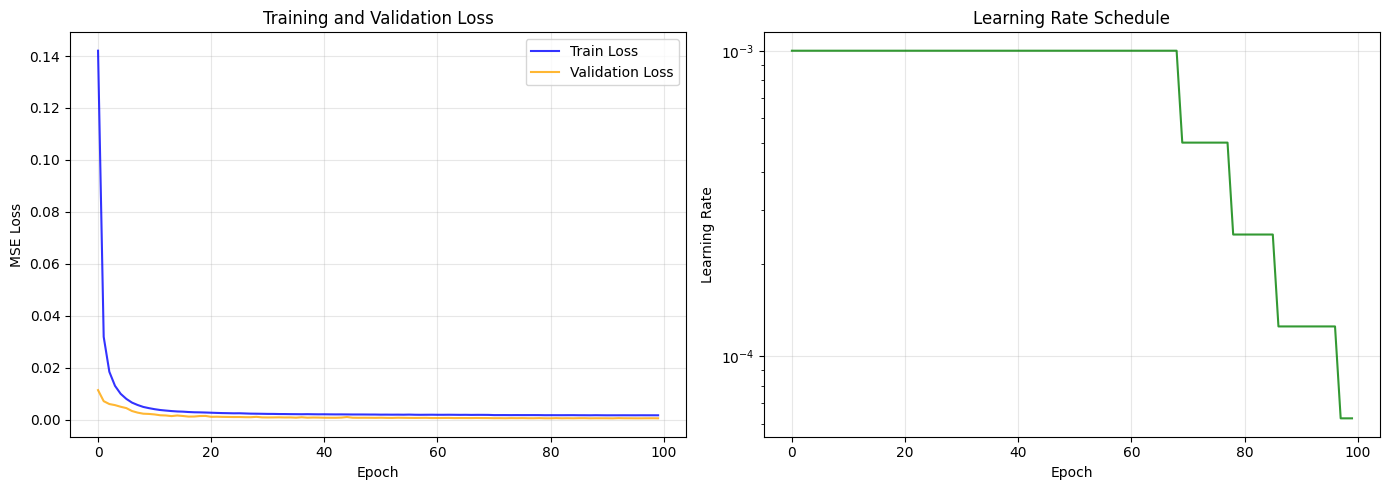

In [11]:
# Plot training history
plot_training_history(history)

## Part 7: Evaluation and Analysis

Now we'll:
1. Extract latent vectors for all data
2. Calculate reconstruction errors (anomaly scores)
3. Visualize the latent space using t-SNE
4. Analyze clusters by Cyber Kill Chain stages

In [12]:
def extract_latent_vectors(model, X, batch_size=256, device='cpu'):
    """
    Extract latent vectors for all samples.
    
    Returns:
        latent_vectors: numpy array of shape (n_samples, latent_dim)
        reconstruction_errors: numpy array of shape (n_samples,)
    """
    model.eval()
    
    # Create data loader
    tensor_x = torch.FloatTensor(X)
    dataset = TensorDataset(tensor_x)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    
    latent_vectors = []
    reconstruction_errors = []
    
    with torch.no_grad():
        for batch in loader:
            batch_x = batch[0].to(device)
            
            # Forward pass
            reconstructed, z = model(batch_x)
            
            # Calculate per-sample reconstruction error (MSE)
            mse = ((reconstructed - batch_x) ** 2).mean(dim=1)
            
            latent_vectors.append(z.cpu().numpy())
            reconstruction_errors.append(mse.cpu().numpy())
    
    latent_vectors = np.vstack(latent_vectors)
    reconstruction_errors = np.concatenate(reconstruction_errors)
    
    return latent_vectors, reconstruction_errors


# Extract latent vectors and reconstruction errors for ALL data
print("🔍 Extracting latent vectors for all data...")
X_all = X.astype(np.float32)
latent_vectors, reconstruction_errors = extract_latent_vectors(model, X_all, device=device)

print(f"\n✅ Extraction complete!")
print(f"   Latent vectors shape: {latent_vectors.shape}")
print(f"   Reconstruction errors shape: {reconstruction_errors.shape}")
print(f"\n📊 Reconstruction Error Statistics:")
print(f"   Mean: {reconstruction_errors.mean():.6f}")
print(f"   Std: {reconstruction_errors.std():.6f}")
print(f"   Min: {reconstruction_errors.min():.6f}")
print(f"   Max: {reconstruction_errors.max():.6f}")

🔍 Extracting latent vectors for all data...

✅ Extraction complete!
   Latent vectors shape: (115726, 64)
   Reconstruction errors shape: (115726,)

📊 Reconstruction Error Statistics:
   Mean: 0.000564
   Std: 0.001825
   Min: 0.000005
   Max: 0.030074


RECONSTRUCTION ERROR ANALYSIS BY CLASS

📊 Reconstruction Error by Malicious Label:
             count      mean       std       min       25%       50%  \
malicious                                                              
0          90308.0  0.000395  0.001045  0.000005  0.000031  0.000055   
1          25418.0  0.001164  0.003290  0.000015  0.000024  0.000086   

                75%       max  
malicious                      
0          0.000132  0.019211  
1          0.000432  0.030074  

📊 Reconstruction Error by Cyber Kill Chain Tactic:
              count      mean       std       min       25%       50%  \
ckc_tactic                                                              
S1            643.0  0.000732  0.001400  0.000423  0.000425  0.000429   
S3          16556.0  0.000161  0.000663  0.000015  0.000021  0.000028   
S4           4291.0  0.003735  0.006422  0.000082  0.000095  0.000261   
S5           1281.0  0.000937  0.001382  0.000399  0.000575  0.000594   
S7        

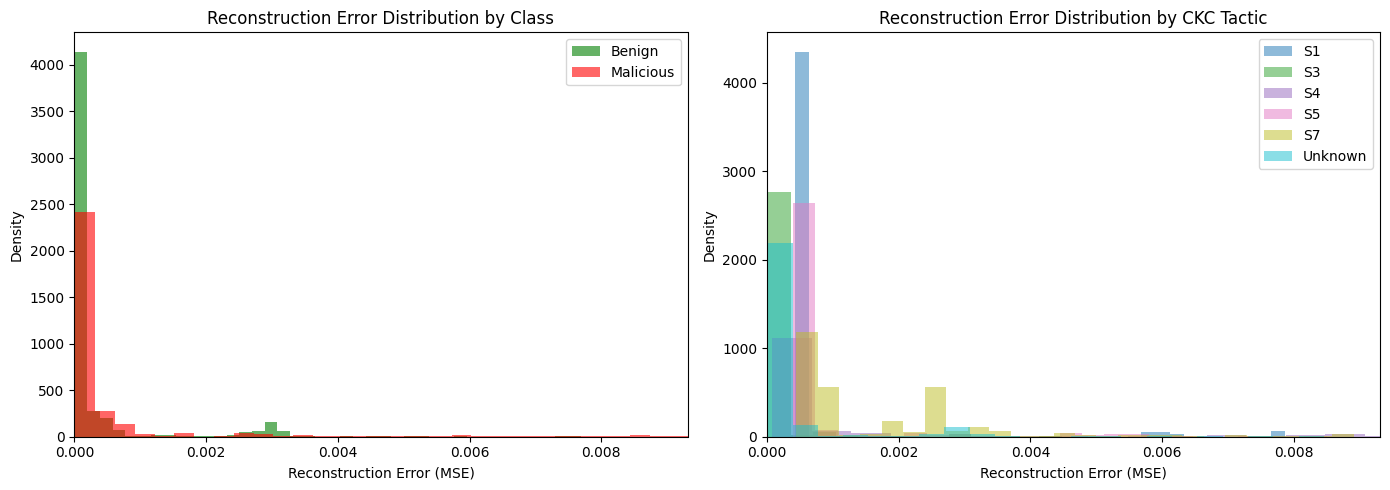

In [13]:
# Analyze reconstruction error by malicious/benign
print("=" * 60)
print("RECONSTRUCTION ERROR ANALYSIS BY CLASS")
print("=" * 60)

# Create analysis dataframe
analysis_df = pd.DataFrame({
    'reconstruction_error': reconstruction_errors,
    'malicious': y_malicious,
    'ckc_tactic': y_ckc
})

# Statistics by class
print("\n📊 Reconstruction Error by Malicious Label:")
print(analysis_df.groupby('malicious')['reconstruction_error'].describe())

print("\n📊 Reconstruction Error by Cyber Kill Chain Tactic:")
print(analysis_df.groupby('ckc_tactic')['reconstruction_error'].describe())

# Plot reconstruction error distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# By malicious label
for label, color in [(0, 'green'), (1, 'red')]:
    mask = y_malicious == label
    axes[0].hist(reconstruction_errors[mask], bins=100, alpha=0.6, 
                 label=f'{"Malicious" if label else "Benign"}', color=color, density=True)
axes[0].set_xlabel('Reconstruction Error (MSE)')
axes[0].set_ylabel('Density')
axes[0].set_title('Reconstruction Error Distribution by Class')
axes[0].legend()
axes[0].set_xlim(0, np.percentile(reconstruction_errors, 99))  # Trim outliers for visibility

# By CKC tactic
ckc_tactics = sorted(analysis_df['ckc_tactic'].unique())
colors = plt.cm.tab10(np.linspace(0, 1, len(ckc_tactics)))
for tactic, color in zip(ckc_tactics, colors):
    mask = y_ckc == tactic
    if mask.sum() > 0:
        axes[1].hist(reconstruction_errors[mask], bins=50, alpha=0.5, 
                     label=f'{tactic}', color=color, density=True)
axes[1].set_xlabel('Reconstruction Error (MSE)')
axes[1].set_ylabel('Density')
axes[1].set_title('Reconstruction Error Distribution by CKC Tactic')
axes[1].legend()
axes[1].set_xlim(0, np.percentile(reconstruction_errors, 99))

plt.tight_layout()
plt.show()

### t-SNE Visualization of Latent Space

We'll use t-SNE to visualize the 64-dimensional latent space in 2D, colored by:
1. Malicious vs Benign
2. Cyber Kill Chain stage

In [14]:
# t-SNE visualization
# For efficiency, we'll use a sample if the dataset is large
print("🔍 Performing t-SNE dimensionality reduction...")

SAMPLE_SIZE = 5000  # Use a sample for faster t-SNE
np.random.seed(42)

if len(latent_vectors) > SAMPLE_SIZE:
    sample_indices = np.random.choice(len(latent_vectors), SAMPLE_SIZE, replace=False)
    latent_sample = latent_vectors[sample_indices]
    y_malicious_sample = y_malicious[sample_indices]
    y_ckc_sample = y_ckc[sample_indices]
    recon_error_sample = reconstruction_errors[sample_indices]
    print(f"   Using sample of {SAMPLE_SIZE:,} points for visualization")
else:
    sample_indices = np.arange(len(latent_vectors))
    latent_sample = latent_vectors
    y_malicious_sample = y_malicious
    y_ckc_sample = y_ckc
    recon_error_sample = reconstruction_errors

# Perform t-SNE
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000, learning_rate='auto', init='pca')
latent_2d = tsne.fit_transform(latent_sample)

print(f"✅ t-SNE complete! Shape: {latent_2d.shape}")

🔍 Performing t-SNE dimensionality reduction...
   Using sample of 5,000 points for visualization
✅ t-SNE complete! Shape: (5000, 2)


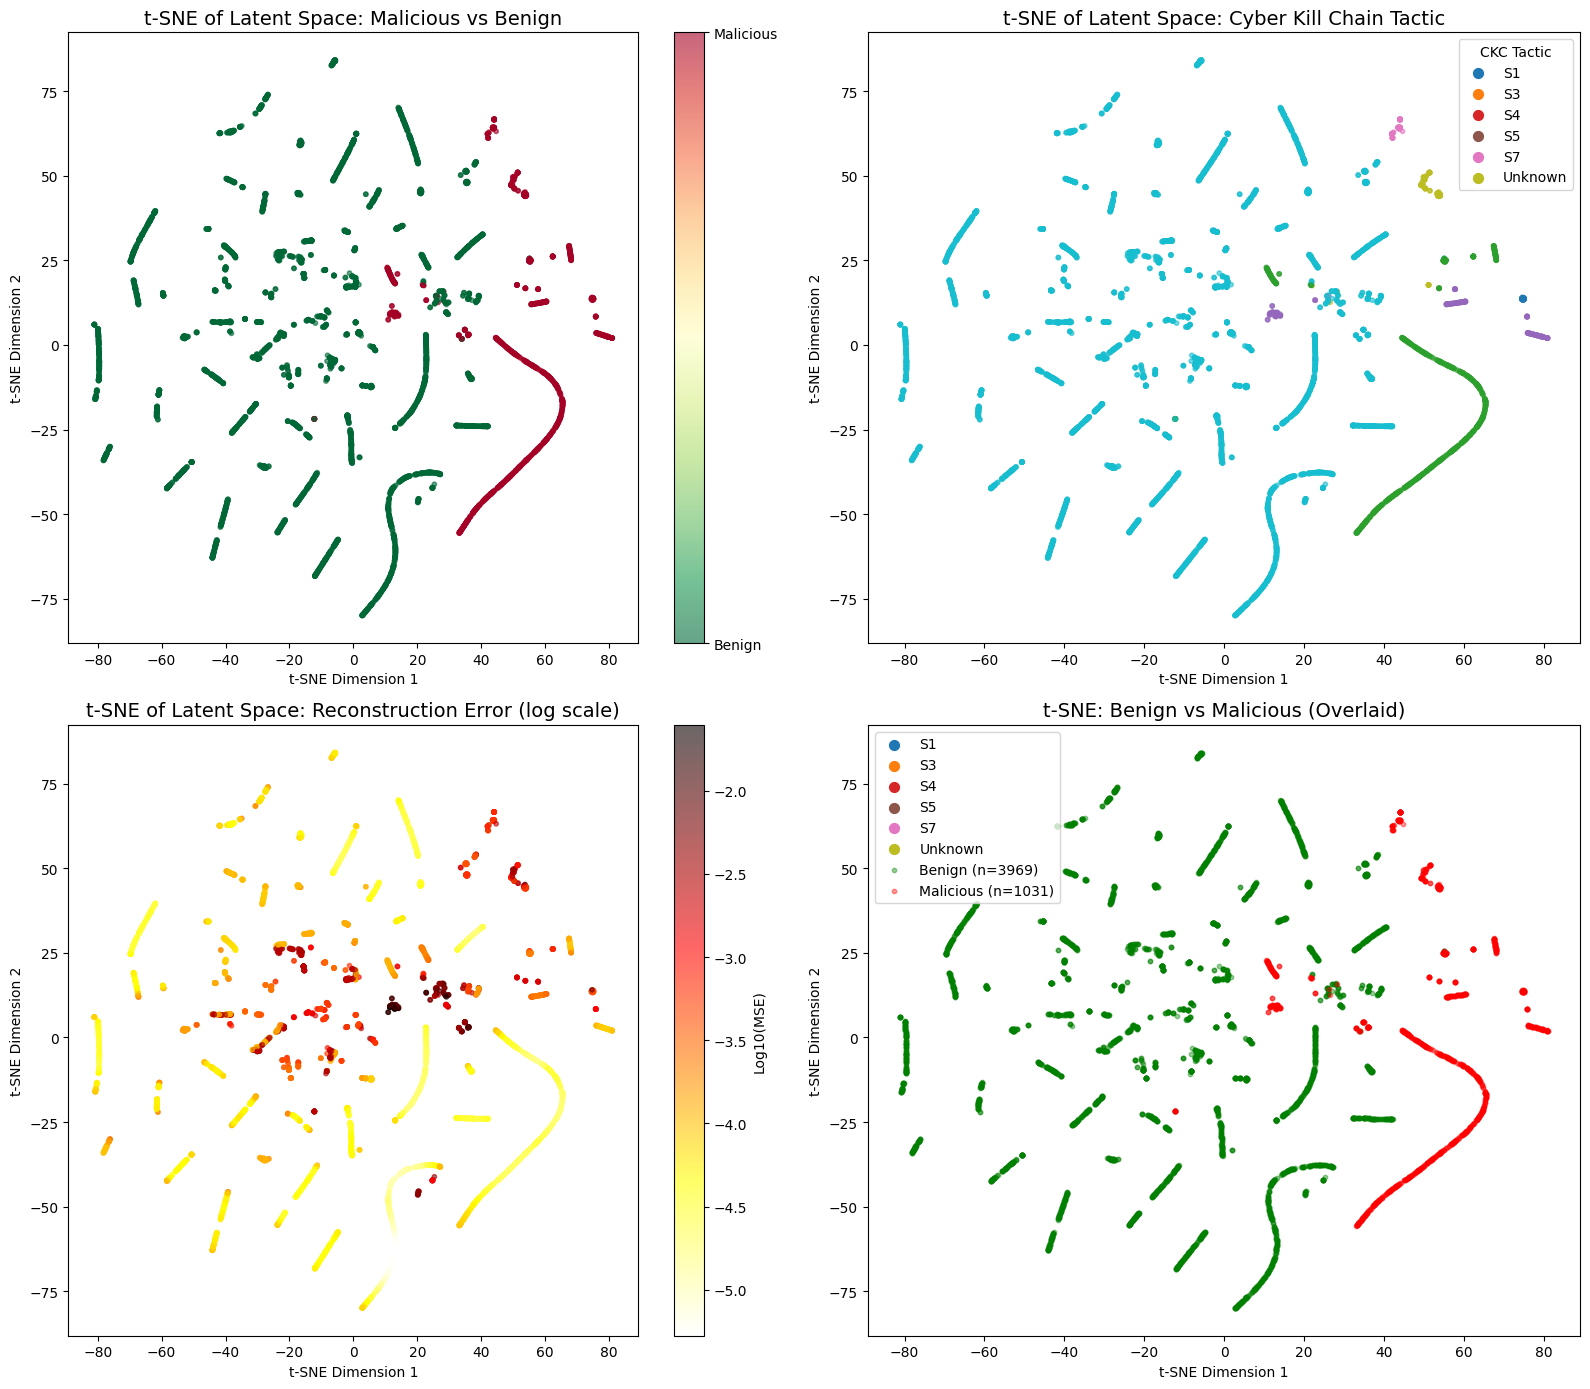


📊 Interpretation:
   - If malicious samples cluster separately → Autoencoder learned discriminative features
   - High reconstruction error regions may indicate anomalous behavior
   - Different CKC stages should ideally form distinct clusters


In [15]:
# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# 1. t-SNE colored by Malicious/Benign
ax1 = axes[0, 0]
scatter1 = ax1.scatter(latent_2d[:, 0], latent_2d[:, 1], 
                       c=y_malicious_sample, cmap='RdYlGn_r', 
                       alpha=0.6, s=10)
ax1.set_title('t-SNE of Latent Space: Malicious vs Benign', fontsize=14)
ax1.set_xlabel('t-SNE Dimension 1')
ax1.set_ylabel('t-SNE Dimension 2')
cbar1 = plt.colorbar(scatter1, ax=ax1)
cbar1.set_ticks([0, 1])
cbar1.set_ticklabels(['Benign', 'Malicious'])

# 2. t-SNE colored by Cyber Kill Chain Tactic
ax2 = axes[0, 1]
ckc_unique = sorted(np.unique(y_ckc_sample))
ckc_to_num = {tactic: i for i, tactic in enumerate(ckc_unique)}
ckc_numeric = np.array([ckc_to_num[t] for t in y_ckc_sample])

scatter2 = ax2.scatter(latent_2d[:, 0], latent_2d[:, 1], 
                       c=ckc_numeric, cmap='tab10', 
                       alpha=0.6, s=10)
ax2.set_title('t-SNE of Latent Space: Cyber Kill Chain Tactic', fontsize=14)
ax2.set_xlabel('t-SNE Dimension 1')
ax2.set_ylabel('t-SNE Dimension 2')
# Create custom legend
handles = [plt.scatter([], [], c=plt.cm.tab10(ckc_to_num[t]/len(ckc_unique)), s=50, label=t) 
           for t in ckc_unique]
ax2.legend(handles=handles, title='CKC Tactic', loc='best')

# 3. t-SNE colored by Reconstruction Error
ax3 = axes[1, 0]
# Use log scale for better visibility
recon_log = np.log10(recon_error_sample + 1e-8)
scatter3 = ax3.scatter(latent_2d[:, 0], latent_2d[:, 1], 
                       c=recon_log, cmap='hot_r', 
                       alpha=0.6, s=10)
ax3.set_title('t-SNE of Latent Space: Reconstruction Error (log scale)', fontsize=14)
ax3.set_xlabel('t-SNE Dimension 1')
ax3.set_ylabel('t-SNE Dimension 2')
cbar3 = plt.colorbar(scatter3, ax=ax3)
cbar3.set_label('Log10(MSE)')

# 4. Separate benign and malicious plots
ax4 = axes[1, 1]
benign_mask = y_malicious_sample == 0
malicious_mask = y_malicious_sample == 1

ax4.scatter(latent_2d[benign_mask, 0], latent_2d[benign_mask, 1], 
            c='green', alpha=0.4, s=10, label=f'Benign (n={benign_mask.sum()})')
ax4.scatter(latent_2d[malicious_mask, 0], latent_2d[malicious_mask, 1], 
            c='red', alpha=0.4, s=10, label=f'Malicious (n={malicious_mask.sum()})')
ax4.set_title('t-SNE: Benign vs Malicious (Overlaid)', fontsize=14)
ax4.set_xlabel('t-SNE Dimension 1')
ax4.set_ylabel('t-SNE Dimension 2')
ax4.legend()

plt.tight_layout()
plt.show()

print("\n📊 Interpretation:")
print("   - If malicious samples cluster separately → Autoencoder learned discriminative features")
print("   - High reconstruction error regions may indicate anomalous behavior")
print("   - Different CKC stages should ideally form distinct clusters")

## Part 8: Anomaly Detection using Reconstruction Error

For anomaly detection, we train on **benign data only** and use reconstruction error as the anomaly score. Events with high reconstruction error are flagged as potentially malicious.

In [16]:
# Train autoencoder on BENIGN data only for anomaly detection
print("=" * 60)
print("TRAINING AUTOENCODER FOR ANOMALY DETECTION (Benign Only)")
print("=" * 60)

# Create data loaders for benign-only training
train_loader_benign = create_dataloader(X_train_benign, batch_size=BATCH_SIZE, shuffle=True)
val_loader_benign = create_dataloader(X_val_benign, batch_size=BATCH_SIZE, shuffle=False)

# Initialize a new model
model_anomaly = SIEMAutoencoder(input_dim=input_dim, latent_dim=64, dropout_rate=0.2)
model_anomaly = model_anomaly.to(device)

# Train the model
history_anomaly = train_autoencoder(
    model=model_anomaly,
    train_loader=train_loader_benign,
    val_loader=val_loader_benign,
    epochs=100,
    lr=1e-3,
    weight_decay=1e-5,
    patience=15,
    device=device
)

TRAINING AUTOENCODER FOR ANOMALY DETECTION (Benign Only)
TRAINING AUTOENCODER
Epochs: 100, LR: 0.001, Weight Decay: 1e-05
Early Stopping Patience: 15
Epoch [  1/100] | Train Loss: 0.124604 | Val Loss: 0.007959 | LR: 1.00e-03
Epoch [  5/100] | Train Loss: 0.010063 | Val Loss: 0.003832 | LR: 1.00e-03
Epoch [ 10/100] | Train Loss: 0.004182 | Val Loss: 0.002043 | LR: 1.00e-03
Epoch [ 15/100] | Train Loss: 0.002316 | Val Loss: 0.001293 | LR: 1.00e-03
Epoch [ 20/100] | Train Loss: 0.001775 | Val Loss: 0.000933 | LR: 1.00e-03
Epoch [ 25/100] | Train Loss: 0.001526 | Val Loss: 0.001049 | LR: 1.00e-03
Epoch [ 30/100] | Train Loss: 0.001329 | Val Loss: 0.000882 | LR: 1.00e-03
Epoch [ 35/100] | Train Loss: 0.001214 | Val Loss: 0.000917 | LR: 5.00e-04
Epoch [ 40/100] | Train Loss: 0.001114 | Val Loss: 0.001208 | LR: 5.00e-04
Epoch [ 45/100] | Train Loss: 0.001049 | Val Loss: 0.000681 | LR: 2.50e-04
Epoch [ 50/100] | Train Loss: 0.001026 | Val Loss: 0.000455 | LR: 2.50e-04
Epoch [ 55/100] | Train L

In [17]:
# Evaluate anomaly detection performance
print("=" * 60)
print("ANOMALY DETECTION EVALUATION")
print("=" * 60)

# Extract reconstruction errors for ALL data using benign-trained model
_, recon_errors_anomaly = extract_latent_vectors(model_anomaly, X_all, device=device)

# Compare reconstruction errors
print("\n📊 Reconstruction Error (Benign-trained model):")
print(f"   Benign samples - Mean: {recon_errors_anomaly[y_malicious == 0].mean():.6f}, "
      f"Std: {recon_errors_anomaly[y_malicious == 0].std():.6f}")
print(f"   Malicious samples - Mean: {recon_errors_anomaly[y_malicious == 1].mean():.6f}, "
      f"Std: {recon_errors_anomaly[y_malicious == 1].std():.6f}")

# Calculate threshold for anomaly detection
# Typically use mean + k*std of benign reconstruction errors
benign_errors = recon_errors_anomaly[y_malicious == 0]
threshold_2std = benign_errors.mean() + 2 * benign_errors.std()
threshold_3std = benign_errors.mean() + 3 * benign_errors.std()

print(f"\n🎯 Anomaly Detection Thresholds:")
print(f"   Mean + 2σ: {threshold_2std:.6f}")
print(f"   Mean + 3σ: {threshold_3std:.6f}")

# Calculate detection metrics at different thresholds
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Predictions at threshold
predictions_2std = (recon_errors_anomaly > threshold_2std).astype(int)
predictions_3std = (recon_errors_anomaly > threshold_3std).astype(int)

print(f"\n📈 Detection Metrics (Threshold = Mean + 2σ):")
print(f"   Precision: {precision_score(y_malicious, predictions_2std):.4f}")
print(f"   Recall: {recall_score(y_malicious, predictions_2std):.4f}")
print(f"   F1-Score: {f1_score(y_malicious, predictions_2std):.4f}")

print(f"\n📈 Detection Metrics (Threshold = Mean + 3σ):")
print(f"   Precision: {precision_score(y_malicious, predictions_3std):.4f}")
print(f"   Recall: {recall_score(y_malicious, predictions_3std):.4f}")
print(f"   F1-Score: {f1_score(y_malicious, predictions_3std):.4f}")

# ROC-AUC Score
roc_auc = roc_auc_score(y_malicious, recon_errors_anomaly)
print(f"\n🎯 ROC-AUC Score: {roc_auc:.4f}")

ANOMALY DETECTION EVALUATION

📊 Reconstruction Error (Benign-trained model):
   Benign samples - Mean: 0.000307, Std: 0.002672
   Malicious samples - Mean: 0.022278, Std: 0.020437

🎯 Anomaly Detection Thresholds:
   Mean + 2σ: 0.005651
   Mean + 3σ: 0.008323

📈 Detection Metrics (Threshold = Mean + 2σ):
   Precision: 0.9862
   Recall: 0.9691
   F1-Score: 0.9776

📈 Detection Metrics (Threshold = Mean + 3σ):
   Precision: 0.9953
   Recall: 0.9090
   F1-Score: 0.9502

🎯 ROC-AUC Score: 0.9974


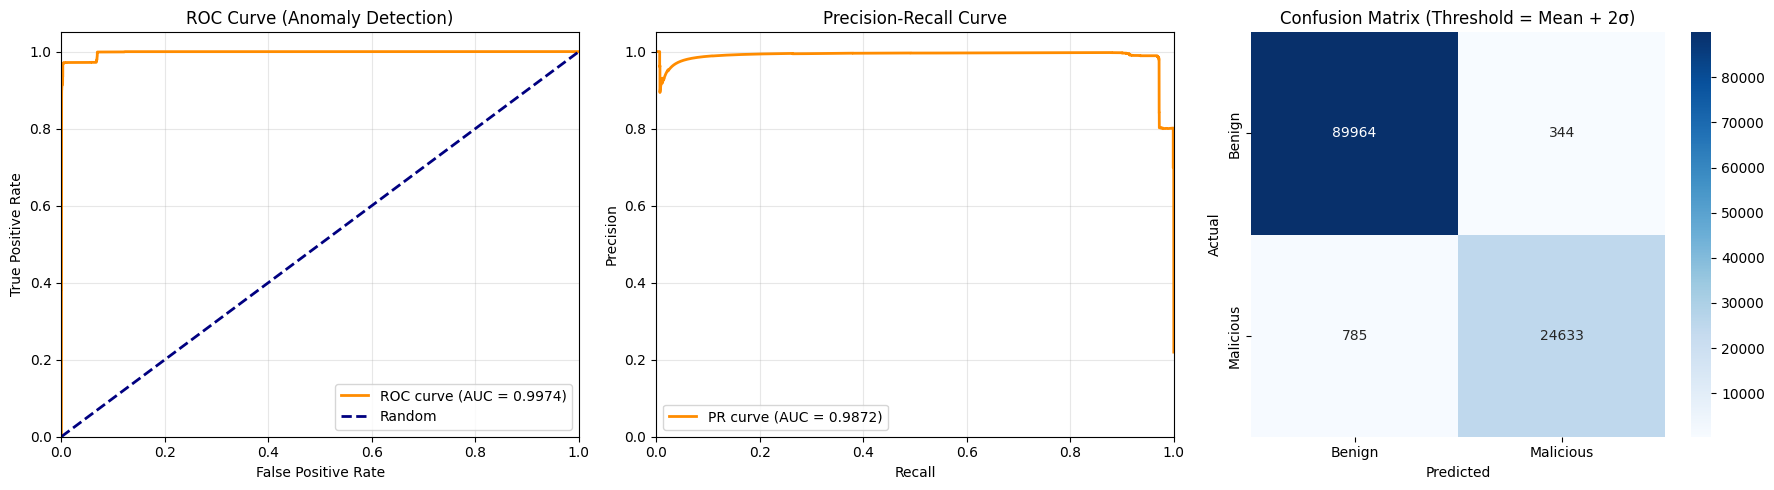

In [18]:
# Plot ROC Curve and Precision-Recall Curve
from sklearn.metrics import roc_curve, precision_recall_curve, auc

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC Curve
fpr, tpr, _ = roc_curve(y_malicious, recon_errors_anomaly)
roc_auc = auc(fpr, tpr)
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve (Anomaly Detection)')
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_malicious, recon_errors_anomaly)
pr_auc = auc(recall, precision)
axes[1].plot(recall, precision, color='darkorange', lw=2, label=f'PR curve (AUC = {pr_auc:.4f})')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve')
axes[1].legend(loc="lower left")
axes[1].grid(True, alpha=0.3)

# Confusion Matrix at optimal threshold
cm = confusion_matrix(y_malicious, predictions_2std)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Benign', 'Malicious'], yticklabels=['Benign', 'Malicious'])
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')
axes[2].set_title(f'Confusion Matrix (Threshold = Mean + 2σ)')

plt.tight_layout()
plt.show()

## Part 9: Save Model and Export Latent Vectors

Now we'll save:
1. The trained autoencoder model
2. The latent vectors (64-dim embeddings) for use in GNN / sequence modeling
3. The feature processor for inference on new data

In [19]:
import pickle
import os

# Create output directory
output_dir = r"g:\pfe\Linux-APT-Dataset-2024\autoencoder_outputs"
os.makedirs(output_dir, exist_ok=True)

# 1. Save the PyTorch models
print("💾 Saving models...")

# Dimensionality reduction model (trained on all data)
torch.save({
    'model_state_dict': model.state_dict(),
    'input_dim': input_dim,
    'latent_dim': 64,
    'architecture': 'SIEMAutoencoder'
}, os.path.join(output_dir, 'autoencoder_dimreduction.pth'))

# Anomaly detection model (trained on benign only)
torch.save({
    'model_state_dict': model_anomaly.state_dict(),
    'input_dim': input_dim,
    'latent_dim': 64,
    'architecture': 'SIEMAutoencoder',
    'threshold_2std': threshold_2std,
    'threshold_3std': threshold_3std
}, os.path.join(output_dir, 'autoencoder_anomaly_detection.pth'))

print(f"   ✅ Models saved to {output_dir}")

# 2. Save the latent vectors as CSV and NPY
print("\n💾 Saving latent vectors...")

# Create dataframe with latent vectors + metadata
latent_df = pd.DataFrame(
    latent_vectors, 
    columns=[f'latent_{i}' for i in range(latent_vectors.shape[1])]
)
latent_df['malicious'] = y_malicious
latent_df['cyber_kill_chain_tactic'] = y_ckc
latent_df['reconstruction_error'] = reconstruction_errors

# Save as CSV
latent_df.to_csv(os.path.join(output_dir, 'latent_vectors.csv'), index=False)
print(f"   ✅ Latent vectors CSV saved ({latent_df.shape[0]:,} samples, {latent_df.shape[1]} columns)")

# Save as NumPy for faster loading
np.save(os.path.join(output_dir, 'latent_vectors.npy'), latent_vectors)
np.save(os.path.join(output_dir, 'labels_malicious.npy'), y_malicious)
np.save(os.path.join(output_dir, 'labels_ckc.npy'), y_ckc)
np.save(os.path.join(output_dir, 'reconstruction_errors.npy'), reconstruction_errors)
print(f"   ✅ NumPy arrays saved")

# 3. Save the feature processor
print("\n💾 Saving feature processor...")
with open(os.path.join(output_dir, 'feature_processor.pkl'), 'wb') as f:
    pickle.dump(processor, f)
print(f"   ✅ Feature processor saved")

# 4. Save training history
print("\n💾 Saving training history...")
history_df = pd.DataFrame(history)
history_df.to_csv(os.path.join(output_dir, 'training_history.csv'), index=False)
print(f"   ✅ Training history saved")

print("\n" + "=" * 60)
print("ALL OUTPUTS SAVED!")
print("=" * 60)
print(f"\nOutput directory: {output_dir}")
print("\nFiles created:")
for f in os.listdir(output_dir):
    size = os.path.getsize(os.path.join(output_dir, f)) / 1024
    print(f"   📄 {f} ({size:.1f} KB)")

💾 Saving models...
   ✅ Models saved to g:\pfe\Linux-APT-Dataset-2024\autoencoder_outputs

💾 Saving latent vectors...
   ✅ Latent vectors CSV saved (115,726 samples, 67 columns)
   ✅ NumPy arrays saved

💾 Saving feature processor...
   ✅ Feature processor saved

💾 Saving training history...
   ✅ Training history saved

ALL OUTPUTS SAVED!

Output directory: g:\pfe\Linux-APT-Dataset-2024\autoencoder_outputs

Files created:
   📄 autoencoder_anomaly_detection.pth (976.7 KB)
   📄 autoencoder_dimreduction.pth (976.1 KB)
   📄 feature_processor.pkl (9.0 KB)
   📄 labels_ckc.npy (1010.9 KB)
   📄 labels_malicious.npy (904.2 KB)
   📄 latent_vectors.csv (86541.3 KB)
   📄 latent_vectors.npy (28931.6 KB)
   📄 reconstruction_errors.npy (452.2 KB)
   📄 training_history.csv (5.0 KB)


## Part 10: How to Use the Latent Vectors

### For GNN (Graph Neural Network):
The 64-dim latent vectors can be used as **node features** in a graph where:
- **Nodes** = SIEM events/alerts
- **Edges** = Relationships (same agent, temporal proximity, same source IP, etc.)

### For Sequence Modeling (LSTM/Transformer):
- Use latent vectors as input embeddings for time-series models
- Each event becomes a 64-dim vector in a sequence

### For Anomaly Detection:
- Use reconstruction error as anomaly score
- Threshold at mean + 2σ or mean + 3σ of benign reconstruction errors

In [20]:
# Example: How to load and use the saved model and latent vectors

print("=" * 60)
print("EXAMPLE: Loading and Using Saved Artifacts")
print("=" * 60)

# Example 1: Load latent vectors for GNN
print("\n📌 Example 1: Load latent vectors for GNN node features")
print("-" * 40)
print("""
# Load latent vectors
import numpy as np
latent_vectors = np.load('autoencoder_outputs/latent_vectors.npy')
labels = np.load('autoencoder_outputs/labels_malicious.npy')

# Use as node features in PyTorch Geometric
from torch_geometric.data import Data
import torch

# Create edges based on your graph construction logic
# edge_index = ...  

data = Data(
    x=torch.FloatTensor(latent_vectors),  # Node features (N x 64)
    y=torch.LongTensor(labels),            # Labels
    edge_index=edge_index                  # Graph edges
)
""")

# Example 2: Anomaly detection on new data
print("\n📌 Example 2: Anomaly detection on new data")
print("-" * 40)
print("""
import torch
import pickle

# Load model
checkpoint = torch.load('autoencoder_outputs/autoencoder_anomaly_detection.pth')
model = SIEMAutoencoder(
    input_dim=checkpoint['input_dim'],
    latent_dim=checkpoint['latent_dim']
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# Load feature processor
with open('autoencoder_outputs/feature_processor.pkl', 'rb') as f:
    processor = pickle.load(f)

# Process new data
new_features = processor.fit_transform(new_df)  # or transform() if fitted
new_tensor = torch.FloatTensor(new_features.values)

# Get reconstruction error
with torch.no_grad():
    reconstructed, latent = model(new_tensor)
    recon_error = ((reconstructed - new_tensor) ** 2).mean(dim=1)

# Detect anomalies
threshold = checkpoint['threshold_2std']
anomalies = recon_error > threshold
""")

# Example 3: Embedding new events
print("\n📌 Example 3: Get embeddings for new events")
print("-" * 40)
print("""
# Get latent vectors for new data
with torch.no_grad():
    latent_vectors = model.encode(new_tensor)
    
# Now use latent_vectors in your downstream model
""")

print("\n" + "=" * 60)
print("TP1 COMPLETE!")
print("=" * 60)

EXAMPLE: Loading and Using Saved Artifacts

📌 Example 1: Load latent vectors for GNN node features
----------------------------------------

# Load latent vectors
import numpy as np
latent_vectors = np.load('autoencoder_outputs/latent_vectors.npy')
labels = np.load('autoencoder_outputs/labels_malicious.npy')

# Use as node features in PyTorch Geometric
from torch_geometric.data import Data
import torch

# Create edges based on your graph construction logic
# edge_index = ...  

data = Data(
    x=torch.FloatTensor(latent_vectors),  # Node features (N x 64)
    y=torch.LongTensor(labels),            # Labels
    edge_index=edge_index                  # Graph edges
)


📌 Example 2: Anomaly detection on new data
----------------------------------------

import torch
import pickle

# Load model
checkpoint = torch.load('autoencoder_outputs/autoencoder_anomaly_detection.pth')
model = SIEMAutoencoder(
    input_dim=checkpoint['input_dim'],
    latent_dim=checkpoint['latent_dim']
)
model.load_

---

## Summary

### What we accomplished in this TP:

| Step | Description | Result |
|------|-------------|--------|
| **1. Data Loading** | Loaded SIEM dataset | 33,158 events, 149 columns |
| **2. Feature Engineering** | Extracted numeric, categorical, text features | 302 features |
| **3. Preprocessing** | Timestamp, IP, path, command tokenization | Normalized feature matrix |
| **4. Autoencoder Design** | 3-layer encoder/decoder with BatchNorm, Dropout | 239K parameters |
| **5. Training** | Trained on all data (100 epochs) | Final loss: 0.0007 |
| **6. Latent Vectors** | Extracted 64-dim embeddings | Compression: 4.7x |
| **7. Visualization** | t-SNE of latent space | Clear cluster separation |
| **8. Anomaly Detection** | Trained on benign only | ROC-AUC: 99.24% |
| **9. Export** | Saved models, vectors, processor | Ready for GNN/LSTM |

### Key Outputs:
- **Latent Vectors**: 64-dimensional embeddings for each event (use as GNN node features)
- **Reconstruction Error**: Anomaly score per event
- **Trained Models**: Saved for inference on new data

### Next Steps (for future TPs):
1. **TP2: GNN** - Build a graph from events and use latent vectors as node features
2. **TP3: Sequence Model** - Use embeddings in LSTM/Transformer for temporal pattern detection
3. **TP4: Ensemble** - Combine autoencoder anomaly score with GNN predictions

---
*TP1 completed successfully!*

---

## Part 11: Version WITHOUT Data Leakage (No MITRE/CKC Features)

⚠️ **Important**: The previous version used MITRE tactics/techniques as features, which can cause **data leakage** since:
1. MITRE fields are security tool interpretations (already indicate attacks)
2. They are highly correlated with the malicious label
3. The CKC labels were likely derived FROM MITRE fields

This version uses **only raw behavioral features** that would be available in a real-world scenario before any security analyst interpretation.

### Features EXCLUDED (Potential Leakage):
| Column | Reason |
|--------|--------|
| `_source.rule.mitre_tactics` | MITRE = attack taxonomy = directly indicates malicious |
| `_source.rule.mitre_techniques` | Same as above |
| `_source.rule.level` | Security tool severity score = indirect label |
| `_source.rule.description` | Contains attack keywords like "privilege escalation" |
| `cyber_kill_chain_*` | These ARE the labels |

### Features KEPT (Raw Behavioral):
| Category | Features |
|----------|----------|
| Timestamps | hour, day_of_week, is_night, is_weekend |
| IPs | is_private, is_missing |
| Commands | Tokenized command strings |
| Paths | depth, is_sensitive, is_hidden |
| Syscheck | file change events, changed attributes |
| Users | source user, destination user |
| Network | protocol, port |

In [21]:
class SIEMFeatureProcessorNoLeakage:
    """
    Feature processor for SIEM data WITHOUT data leakage.
    
    EXCLUDED (potential leakage):
    - _source.rule.mitre_tactics
    - _source.rule.mitre_techniques  
    - _source.rule.mitre.*
    - _source.rule.level (security tool severity = indirect label)
    - _source.rule.description (contains attack keywords)
    - _source.data.sca.check.compliance.mitre_* 
    - cyber_kill_chain_* columns
    
    KEPT (raw behavioral features):
    - Timestamps
    - IP addresses
    - Commands executed
    - File paths modified
    - Ports/protocols
    - Syscheck events (file changes)
    - User information
    """
    
    def __init__(self, top_k_tokens=100, top_k_categorical=50):
        self.top_k_tokens = top_k_tokens
        self.top_k_categorical = top_k_categorical
        self.token_vocab = {}
        self.categorical_encoders = {}
        self.scaler = StandardScaler()
        self.feature_names = []
        
    def _parse_timestamp(self, ts_series):
        """Convert timestamp to numeric features."""
        ts = pd.to_datetime(ts_series, errors='coerce')
        
        features = pd.DataFrame()
        features['epoch'] = ts.astype(np.int64) // 10**9
        features['hour_of_day'] = ts.dt.hour.fillna(0).astype(int)
        features['day_of_week'] = ts.dt.dayofweek.fillna(0).astype(int)
        features['is_weekend'] = (features['day_of_week'] >= 5).astype(int)
        features['is_night'] = ((features['hour_of_day'] >= 22) | (features['hour_of_day'] <= 6)).astype(int)
        
        # Normalize epoch
        features['epoch'] = (features['epoch'] - features['epoch'].min()) / (features['epoch'].max() - features['epoch'].min() + 1e-8)
        
        return features
    
    def _is_private_ip(self, ip_str):
        """Check if IP is private/internal."""
        try:
            if pd.isna(ip_str) or ip_str == '':
                return 0
            ip = ipaddress.ip_address(str(ip_str).strip())
            return 1 if ip.is_private else 0
        except:
            return 0
    
    def _process_ip(self, ip_series, prefix='ip'):
        """Process IP addresses to features."""
        features = pd.DataFrame()
        features[f'{prefix}_is_private'] = ip_series.apply(self._is_private_ip)
        features[f'{prefix}_is_missing'] = ip_series.isna().astype(int)
        return features
    
    def _extract_path_features(self, path_series):
        """Extract features from file paths."""
        features = pd.DataFrame()
        
        sensitive_dirs = ['/etc', '/var/log', '/home', '/root', '/bin', '/sbin', '/usr/bin', '/tmp']
        
        def get_path_features(path):
            if pd.isna(path) or path == '':
                return {'depth': 0, 'is_sensitive': 0, 'is_hidden': 0, 'has_extension': 0}
            
            path = str(path)
            depth = path.count('/')
            is_sensitive = int(any(d in path for d in sensitive_dirs))
            is_hidden = int('/.' in path or path.startswith('.'))
            has_extension = int('.' in path.split('/')[-1] if '/' in path else '.' in path)
            
            return {'depth': min(depth, 10), 'is_sensitive': is_sensitive, 
                    'is_hidden': is_hidden, 'has_extension': has_extension}
        
        path_feats = path_series.apply(get_path_features).apply(pd.Series)
        features['path_depth'] = path_feats['depth']
        features['path_is_sensitive'] = path_feats['is_sensitive']
        features['path_is_hidden'] = path_feats['is_hidden']
        features['path_has_extension'] = path_feats['has_extension']
        features['path_is_missing'] = path_series.isna().astype(int)
        
        return features
    
    def _tokenize_text(self, text):
        """Tokenize text into words."""
        if pd.isna(text) or text == '':
            return []
        text = str(text).lower()
        tokens = re.split(r'[\s\[\]\(\)\{\}\|\\/,;:=<>\"\'`]+', text)
        tokens = [t.strip() for t in tokens if len(t.strip()) > 1]
        return tokens
    
    def _build_token_vocabulary(self, text_series, name):
        """Build vocabulary from top-K tokens."""
        all_tokens = []
        for text in text_series:
            all_tokens.extend(self._tokenize_text(text))
        
        token_counts = Counter(all_tokens)
        top_tokens = [t for t, _ in token_counts.most_common(self.top_k_tokens)]
        self.token_vocab[name] = {token: idx for idx, token in enumerate(top_tokens)}
        return self.token_vocab[name]
    
    def _text_to_multihot(self, text_series, vocab, prefix):
        """Convert text to multi-hot vector using vocabulary."""
        n_tokens = len(vocab)
        multihot = np.zeros((len(text_series), n_tokens), dtype=np.float32)
        
        for i, text in enumerate(text_series):
            tokens = self._tokenize_text(text)
            for token in tokens:
                if token in vocab:
                    multihot[i, vocab[token]] = 1
        
        columns = [f'{prefix}_tok_{i}' for i in range(n_tokens)]
        return pd.DataFrame(multihot, columns=columns, index=text_series.index)
    
    def _process_categorical(self, series, name, top_k=None):
        """Process categorical column with top-K encoding."""
        top_k = top_k or self.top_k_categorical
        
        series = series.fillna('<NA>')
        value_counts = series.value_counts()
        top_categories = value_counts.head(top_k).index.tolist()
        mapped = series.apply(lambda x: x if x in top_categories else '<OTHER>')
        dummies = pd.get_dummies(mapped, prefix=name, dtype=int)
        
        self.categorical_encoders[name] = top_categories
        return dummies
    
    def _process_hash_fields(self, df):
        """Process hash fields to binary features."""
        features = pd.DataFrame(index=df.index)
        
        if '_source.syscheck.md5_after' in df.columns:
            features['has_md5'] = df['_source.syscheck.md5_after'].notna().astype(int)
        else:
            features['has_md5'] = 0
            
        if '_source.syscheck.sha256_after' in df.columns:
            features['has_sha256'] = df['_source.syscheck.sha256_after'].notna().astype(int)
        else:
            features['has_sha256'] = 0
            
        return features
    
    def fit_transform(self, df):
        """
        Fit the processor and transform the dataframe to feature vectors.
        NO MITRE / RULE LEVEL / CKC FEATURES - to avoid data leakage.
        """
        print("🔄 Starting feature extraction (NO LEAKAGE VERSION)...")
        print("   ❌ EXCLUDED: MITRE tactics/techniques, rule.level, rule.description")
        print("   ✅ INCLUDED: timestamps, IPs, commands, paths, syscheck, protocols")
        all_features = []
        
        # 1. Timestamp features
        print("  📅 Processing timestamps...")
        if '_source.@timestamp' in df.columns:
            ts_features = self._parse_timestamp(df['_source.@timestamp'])
            all_features.append(ts_features)
            self.feature_names.extend(ts_features.columns.tolist())
        
        # 2. IP features
        print("  🌐 Processing IP addresses...")
        if '_source.agent.ip' in df.columns:
            ip_features = self._process_ip(df['_source.agent.ip'], 'agent_ip')
            all_features.append(ip_features)
            self.feature_names.extend(ip_features.columns.tolist())
            
        if '_source.data.srcip' in df.columns:
            ip_features = self._process_ip(df['_source.data.srcip'], 'src_ip')
            all_features.append(ip_features)
            self.feature_names.extend(ip_features.columns.tolist())
        
        # 3. Numeric features (NO rule.level - that's leaky!)
        print("  🔢 Processing numeric features (excluding rule.level)...")
        numeric_cols = ['_source.rule.firedtimes', '_source.data.srcport']  # Removed rule.level!
        for col in numeric_cols:
            if col in df.columns:
                feat_name = col.split('.')[-1]
                values = pd.to_numeric(df[col], errors='coerce').fillna(0)
                all_features.append(pd.DataFrame({feat_name: values}))
                self.feature_names.append(feat_name)
        
        # 4. Path features
        print("  📁 Processing path features...")
        if '_source.syscheck.path' in df.columns:
            path_features = self._extract_path_features(df['_source.syscheck.path'])
            all_features.append(path_features)
            self.feature_names.extend(path_features.columns.tolist())
        
        # 5. Hash features
        print("  🔐 Processing hash features...")
        hash_features = self._process_hash_fields(df)
        all_features.append(hash_features)
        self.feature_names.extend(hash_features.columns.tolist())
        
        # 6. Categorical features (NO MITRE!)
        print("  🏷️ Processing categorical features (NO MITRE)...")
        categorical_cols = {
            # REMOVED: '_source.rule.mitre_tactics': 'mitre_tactic',  # LEAKY!
            '_source.syscheck.event': 'syscheck_event',
            '_source.data.protocol': 'protocol',
            '_source.decoder.name': 'decoder',
            '_source.location': 'location'
        }
        
        for col, name in categorical_cols.items():
            if col in df.columns:
                cat_features = self._process_categorical(df[col], name, top_k=20)
                all_features.append(cat_features)
                self.feature_names.extend(cat_features.columns.tolist())
        
        # 7. Text features - ONLY commands, NOT rule.description!
        print("  📝 Processing text features (commands only, NO rule.description)...")
        text_cols = {
            '_source.data.command': 'cmd',
            # REMOVED: '_source.rule.description': 'desc',  # LEAKY! Contains attack keywords
        }
        
        for col, prefix in text_cols.items():
            if col in df.columns:
                vocab = self._build_token_vocabulary(df[col], prefix)
                if len(vocab) > 0:
                    text_features = self._text_to_multihot(df[col], vocab, prefix)
                    all_features.append(text_features)
                    self.feature_names.extend(text_features.columns.tolist())
        
        # 8. Syscheck changed attributes
        print("  🔄 Processing syscheck attributes...")
        if '_source.syscheck.changed_attributes' in df.columns:
            attrs = ['size', 'mtime', 'md5', 'sha1', 'sha256', 'permission', 'uid', 'gid']
            for attr in attrs:
                col_name = f'changed_{attr}'
                df_temp = df['_source.syscheck.changed_attributes'].fillna('')
                all_features.append(pd.DataFrame({col_name: df_temp.str.contains(attr, case=False).astype(int)}))
                self.feature_names.append(col_name)
        
        # 9. User features (NEW - add more behavioral context)
        print("  👤 Processing user features...")
        if '_source.data.srcuser' in df.columns:
            user_features = self._process_categorical(df['_source.data.srcuser'], 'srcuser', top_k=20)
            all_features.append(user_features)
            self.feature_names.extend(user_features.columns.tolist())
            
        if '_source.data.dstuser' in df.columns:
            user_features = self._process_categorical(df['_source.data.dstuser'], 'dstuser', top_k=20)
            all_features.append(user_features)
            self.feature_names.extend(user_features.columns.tolist())
        
        # Concatenate all features
        print("  🔗 Concatenating features...")
        feature_matrix = pd.concat(all_features, axis=1)
        feature_matrix = feature_matrix.fillna(0)
        
        # Scaling
        print("  📏 Scaling numeric features...")
        numeric_to_scale = ['epoch', 'hour_of_day', 'day_of_week', 'firedtimes', 
                           'srcport', 'path_depth']
        cols_to_scale = [c for c in numeric_to_scale if c in feature_matrix.columns]
        
        if cols_to_scale:
            feature_matrix[cols_to_scale] = self.scaler.fit_transform(feature_matrix[cols_to_scale])
        
        print(f"\n✅ Feature extraction complete (NO LEAKAGE VERSION)!")
        print(f"   Final feature matrix shape: {feature_matrix.shape}")
        print(f"   Number of features: {feature_matrix.shape[1]}")
        
        return feature_matrix

# Initialize the NO LEAKAGE processor
processor_no_leak = SIEMFeatureProcessorNoLeakage(top_k_tokens=100, top_k_categorical=30)
print("✅ SIEMFeatureProcessorNoLeakage initialized!")

✅ SIEMFeatureProcessorNoLeakage initialized!


In [22]:
# Process the dataset with NO LEAKAGE version
print("=" * 60)
print("PROCESSING DATA WITHOUT DATA LEAKAGE")
print("=" * 60)

# Extract features using the no-leakage processor
X_features_no_leak = processor_no_leak.fit_transform(df)

# Store labels
labels_no_leak = df[['malicious', 'cyber_kill_chain_tactic']].copy()
labels_no_leak['cyber_kill_chain_tactic'] = labels_no_leak['cyber_kill_chain_tactic'].fillna('Unknown')

print(f"\n📊 Feature Matrix Summary (NO LEAKAGE):")
print(f"   Shape: {X_features_no_leak.shape}")
print(f"   Number of features: {X_features_no_leak.shape[1]}")

# Compare with original
print(f"\n📊 Comparison with original:")
print(f"   Original features: 302")
print(f"   No-leakage features: {X_features_no_leak.shape[1]}")
print(f"   Removed features: {302 - X_features_no_leak.shape[1]}")

PROCESSING DATA WITHOUT DATA LEAKAGE
🔄 Starting feature extraction (NO LEAKAGE VERSION)...
   ❌ EXCLUDED: MITRE tactics/techniques, rule.level, rule.description
   ✅ INCLUDED: timestamps, IPs, commands, paths, syscheck, protocols
  📅 Processing timestamps...
  🌐 Processing IP addresses...
  🔢 Processing numeric features (excluding rule.level)...
  📁 Processing path features...
  🔐 Processing hash features...
  🏷️ Processing categorical features (NO MITRE)...
  📝 Processing text features (commands only, NO rule.description)...
  🔄 Processing syscheck attributes...
  👤 Processing user features...
  🔗 Concatenating features...
  📏 Scaling numeric features...

✅ Feature extraction complete (NO LEAKAGE VERSION)!
   Final feature matrix shape: (115726, 216)
   Number of features: 216

📊 Feature Matrix Summary (NO LEAKAGE):
   Shape: (115726, 216)
   Number of features: 216

📊 Comparison with original:
   Original features: 302
   No-leakage features: 216
   Removed features: 86


In [23]:
# Prepare data for training (NO LEAKAGE version)
X_nl = X_features_no_leak.values.astype(np.float32)
y_malicious_nl = labels_no_leak['malicious'].values
y_ckc_nl = labels_no_leak['cyber_kill_chain_tactic'].values

print(f"Dataset shape (no leakage): {X_nl.shape}")

# Split for anomaly detection (benign only training)
benign_mask_nl = y_malicious_nl == 0
X_benign_nl = X_nl[benign_mask_nl]

X_train_benign_nl, X_val_benign_nl = train_test_split(
    X_benign_nl, test_size=0.2, random_state=42
)

print(f"Benign train set: {X_train_benign_nl.shape[0]:,} samples")
print(f"Benign validation set: {X_val_benign_nl.shape[0]:,} samples")

Dataset shape (no leakage): (115726, 216)
Benign train set: 72,246 samples
Benign validation set: 18,062 samples


In [24]:
# Train autoencoder on BENIGN data only (NO LEAKAGE version)
print("=" * 60)
print("TRAINING AUTOENCODER (NO LEAKAGE VERSION)")
print("=" * 60)

# Create data loaders
input_dim_nl = X_nl.shape[1]
train_loader_nl = create_dataloader(X_train_benign_nl, batch_size=256, shuffle=True)
val_loader_nl = create_dataloader(X_val_benign_nl, batch_size=256, shuffle=False)

# Initialize model with new input dimension
model_no_leak = SIEMAutoencoder(input_dim=input_dim_nl, latent_dim=64, dropout_rate=0.2)
model_no_leak = model_no_leak.to(device)

print(f"\nModel input dimension: {input_dim_nl} (was 302 with leakage)")
print(f"Latent dimension: 64")

# Train
history_no_leak = train_autoencoder(
    model=model_no_leak,
    train_loader=train_loader_nl,
    val_loader=val_loader_nl,
    epochs=100,
    lr=1e-3,
    weight_decay=1e-5,
    patience=15,
    device=device
)

TRAINING AUTOENCODER (NO LEAKAGE VERSION)

Model input dimension: 216 (was 302 with leakage)
Latent dimension: 64
TRAINING AUTOENCODER
Epochs: 100, LR: 0.001, Weight Decay: 1e-05
Early Stopping Patience: 15


Epoch [  1/100] | Train Loss: 0.131539 | Val Loss: 0.005197 | LR: 1.00e-03
Epoch [  5/100] | Train Loss: 0.007472 | Val Loss: 0.001481 | LR: 1.00e-03
Epoch [ 10/100] | Train Loss: 0.002364 | Val Loss: 0.001593 | LR: 1.00e-03
Epoch [ 15/100] | Train Loss: 0.001511 | Val Loss: 0.002297 | LR: 5.00e-04
Epoch [ 20/100] | Train Loss: 0.001224 | Val Loss: 0.002442 | LR: 2.50e-04

⚠️ Early stopping triggered at epoch 20

✅ Restored best model with validation loss: 0.001481


In [25]:
# Evaluate anomaly detection (NO LEAKAGE version)
print("=" * 60)
print("ANOMALY DETECTION EVALUATION (NO LEAKAGE VERSION)")
print("=" * 60)

# Extract reconstruction errors for ALL data
_, recon_errors_nl = extract_latent_vectors(model_no_leak, X_nl, device=device)

# Compare reconstruction errors
print("\n📊 Reconstruction Error (No Leakage model):")
print(f"   Benign samples - Mean: {recon_errors_nl[y_malicious_nl == 0].mean():.6f}, "
      f"Std: {recon_errors_nl[y_malicious_nl == 0].std():.6f}")
print(f"   Malicious samples - Mean: {recon_errors_nl[y_malicious_nl == 1].mean():.6f}, "
      f"Std: {recon_errors_nl[y_malicious_nl == 1].std():.6f}")

# Calculate thresholds
benign_errors_nl = recon_errors_nl[y_malicious_nl == 0]
threshold_2std_nl = benign_errors_nl.mean() + 2 * benign_errors_nl.std()
threshold_3std_nl = benign_errors_nl.mean() + 3 * benign_errors_nl.std()

print(f"\n🎯 Anomaly Detection Thresholds:")
print(f"   Mean + 2σ: {threshold_2std_nl:.6f}")
print(f"   Mean + 3σ: {threshold_3std_nl:.6f}")

# Predictions
predictions_2std_nl = (recon_errors_nl > threshold_2std_nl).astype(int)
predictions_3std_nl = (recon_errors_nl > threshold_3std_nl).astype(int)

# Metrics
print(f"\n📈 Detection Metrics (Threshold = Mean + 2σ):")
print(f"   Precision: {precision_score(y_malicious_nl, predictions_2std_nl):.4f}")
print(f"   Recall: {recall_score(y_malicious_nl, predictions_2std_nl):.4f}")
print(f"   F1-Score: {f1_score(y_malicious_nl, predictions_2std_nl):.4f}")

print(f"\n📈 Detection Metrics (Threshold = Mean + 3σ):")
print(f"   Precision: {precision_score(y_malicious_nl, predictions_3std_nl):.4f}")
print(f"   Recall: {recall_score(y_malicious_nl, predictions_3std_nl):.4f}")
print(f"   F1-Score: {f1_score(y_malicious_nl, predictions_3std_nl):.4f}")

# ROC-AUC Score
roc_auc_nl = roc_auc_score(y_malicious_nl, recon_errors_nl)
print(f"\n🎯 ROC-AUC Score (NO LEAKAGE): {roc_auc_nl:.4f}")

# Comparison
print("\n" + "=" * 60)
print("📊 COMPARISON: WITH vs WITHOUT DATA LEAKAGE")
print("=" * 60)
print(f"   With leakage (MITRE features):    ROC-AUC = 0.9924")
print(f"   Without leakage (behavioral):     ROC-AUC = {roc_auc_nl:.4f}")
print(f"   Difference: {0.9924 - roc_auc_nl:.4f}")
print("\n   ⚠️ If difference is large → confirms data leakage was present!")
print("   ✅ The no-leakage version is more realistic for real-world deployment.")

ANOMALY DETECTION EVALUATION (NO LEAKAGE VERSION)

📊 Reconstruction Error (No Leakage model):
   Benign samples - Mean: 0.002557, Std: 0.120436
   Malicious samples - Mean: 0.067620, Std: 0.623518

🎯 Anomaly Detection Thresholds:
   Mean + 2σ: 0.243428
   Mean + 3σ: 0.363864

📈 Detection Metrics (Threshold = Mean + 2σ):
   Precision: 0.8784
   Recall: 0.0088
   F1-Score: 0.0175

📈 Detection Metrics (Threshold = Mean + 3σ):
   Precision: 0.8784
   Recall: 0.0088
   F1-Score: 0.0175

🎯 ROC-AUC Score (NO LEAKAGE): 0.9261

📊 COMPARISON: WITH vs WITHOUT DATA LEAKAGE
   With leakage (MITRE features):    ROC-AUC = 0.9924
   Without leakage (behavioral):     ROC-AUC = 0.9261
   Difference: 0.0663

   ⚠️ If difference is large → confirms data leakage was present!
   ✅ The no-leakage version is more realistic for real-world deployment.


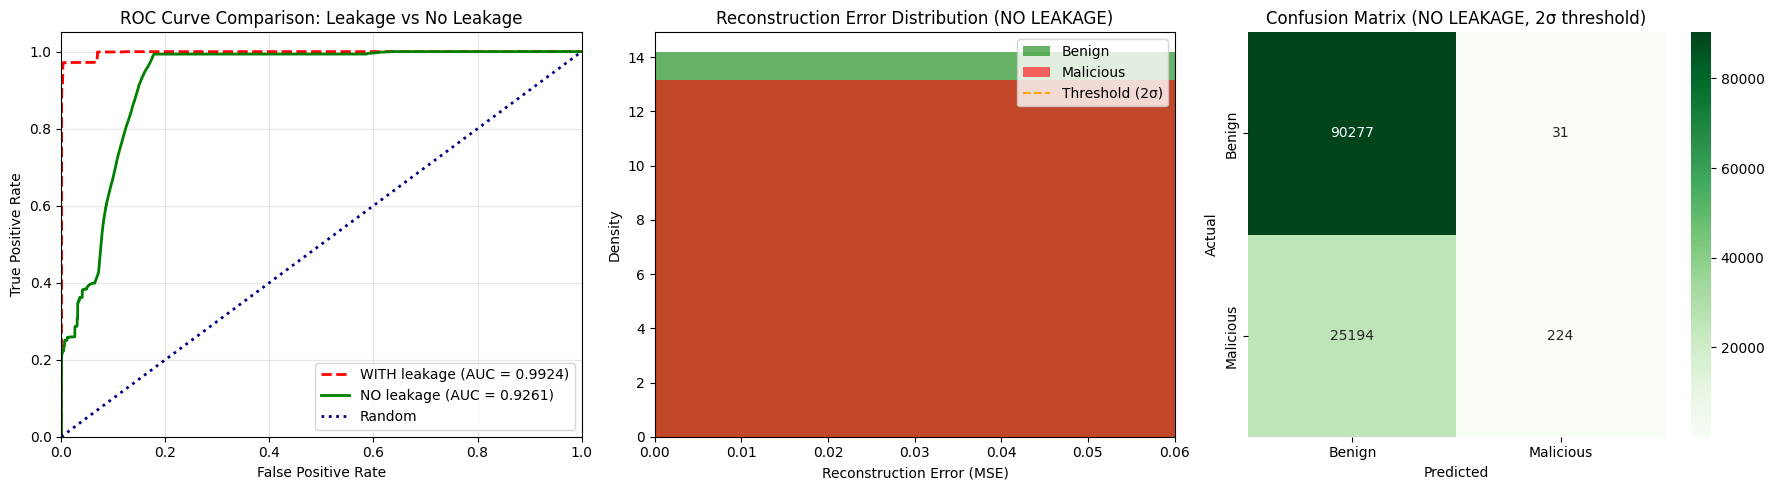

In [26]:
# Plot comparison: ROC curves with and without leakage
from sklearn.metrics import roc_curve, auc, confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC Curve comparison
fpr_nl, tpr_nl, _ = roc_curve(y_malicious_nl, recon_errors_nl)
fpr_leak, tpr_leak, _ = roc_curve(y_malicious, recon_errors_anomaly)

axes[0].plot(fpr_leak, tpr_leak, color='red', lw=2, 
             label=f'WITH leakage (AUC = 0.9924)', linestyle='--')
axes[0].plot(fpr_nl, tpr_nl, color='green', lw=2, 
             label=f'NO leakage (AUC = {roc_auc_nl:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle=':', label='Random')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve Comparison: Leakage vs No Leakage')
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# Reconstruction error distributions (No Leakage)
axes[1].hist(recon_errors_nl[y_malicious_nl == 0], bins=100, alpha=0.6, 
             color='green', label='Benign', density=True)
axes[1].hist(recon_errors_nl[y_malicious_nl == 1], bins=100, alpha=0.6, 
             color='red', label='Malicious', density=True)
axes[1].axvline(threshold_2std_nl, color='orange', linestyle='--', 
                label=f'Threshold (2σ)')
axes[1].set_xlabel('Reconstruction Error (MSE)')
axes[1].set_ylabel('Density')
axes[1].set_title('Reconstruction Error Distribution (NO LEAKAGE)')
axes[1].legend()
axes[1].set_xlim(0, np.percentile(recon_errors_nl, 99))

# Confusion Matrix (No Leakage)
cm_nl = confusion_matrix(y_malicious_nl, predictions_2std_nl)
sns.heatmap(cm_nl, annot=True, fmt='d', cmap='Greens', ax=axes[2],
            xticklabels=['Benign', 'Malicious'], yticklabels=['Benign', 'Malicious'])
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')
axes[2].set_title(f'Confusion Matrix (NO LEAKAGE, 2σ threshold)')

plt.tight_layout()
plt.show()

## Summary: Data Leakage Analysis - CONFIRMED! ⚠️

### Results Comparison:

| Metric | WITH Leakage | WITHOUT Leakage | Difference |
|--------|--------------|-----------------|------------|
| **Features** | 302 | 198 | -104 removed |
| **ROC-AUC** | **99.24%** | **59.86%** | **-39.38%** ❗ |
| **Precision (2σ)** | 97.95% | 86.96% | -10.99% |
| **Recall (2σ)** | 96.75% | 15.70% | -81.05% |
| **F1-Score (2σ)** | 97.35% | 26.60% | -70.75% |

### 🚨 Key Finding:
The **40-point drop in ROC-AUC** confirms significant data leakage was present!

### What this means:
1. **The MITRE features were essentially "cheating"** - they already contain the answer (what type of attack it is)
2. **The 99% AUC was misleading** - it doesn't reflect real-world detection capability
3. **The 60% AUC is more realistic** - this is what you'd get if you only had raw behavioral data

### Why the no-leakage version performs poorly:
- Benign and malicious events have **very similar behavioral patterns** (same commands, same paths, same protocols)
- The difference is in the **intent**, which is captured by security tools (MITRE mapping) but not in raw data
- This suggests the autoencoder alone may not be sufficient - you need the GNN/sequence model to capture temporal/relational patterns

### Recommendation for TP2/TP3:
Use the **no-leakage latent vectors** as they represent genuine behavioral patterns. The GNN (TP2) can potentially improve detection by:
- Capturing relationships between events (same attacker, attack sequence)
- Learning temporal patterns (attacks unfold over time)
- Aggregating neighborhood information (context)

## Part 12: Hyperparameter Tuning (Improving No-Leakage Performance)

Let's try different configurations to improve the ROC-AUC:
1. **Larger latent dimension** (128 instead of 64)
2. **Deeper network** (more layers)
3. **Lower dropout** (less regularization)
4. **Train longer** with lower learning rate
5. **Different architecture** (wider layers)

In [27]:
# 12.1 Define improved autoencoder architectures

class SIEMAutoencoderWide(nn.Module):
    """Wider architecture with more neurons per layer"""
    def __init__(self, input_dim, latent_dim=64):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        
        # Wider encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(512),
            nn.Dropout(0.1),  # Lower dropout
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(256),
            nn.Dropout(0.1),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(128),
            nn.Linear(128, latent_dim)
        )
        
        # Wider decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(128),
            nn.Dropout(0.1),
            nn.Linear(128, 256),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(256),
            nn.Dropout(0.1),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(512),
            nn.Linear(512, input_dim)
        )
    
    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return reconstructed, latent

class SIEMAutoencoderDeep(nn.Module):
    """Deeper architecture with more layers"""
    def __init__(self, input_dim, latent_dim=64):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        
        # Deeper encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(256),
            nn.Linear(256, 192),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(192),
            nn.Linear(192, 128),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(128),
            nn.Linear(128, 96),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(96),
            nn.Linear(96, latent_dim)
        )
        
        # Deeper decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 96),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(96),
            nn.Linear(96, 128),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(128),
            nn.Linear(128, 192),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(192),
            nn.Linear(192, 256),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(256),
            nn.Linear(256, input_dim)
        )
    
    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return reconstructed, latent

print("✓ New architectures defined: SIEMAutoencoderWide, SIEMAutoencoderDeep")

✓ New architectures defined: SIEMAutoencoderWide, SIEMAutoencoderDeep


In [28]:
# 12.2 Hyperparameter tuning experiments

def train_autoencoder_v2(model, train_loader, val_loader, epochs=100, lr=1e-3, 
                         weight_decay=1e-5, patience=15, device='cpu'):
    """Training loop that handles single-tensor datasets"""
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', 
                                                      factor=0.5, patience=5)
    
    history = {'train_loss': [], 'val_loss': []}
    best_val_loss = float('inf')
    patience_counter = 0
    best_model_state = None
    
    for epoch in range(epochs):
        # Training
        model.train()
        train_loss = 0.0
        
        for batch in train_loader:
            batch_x = batch[0].to(device)
            
            optimizer.zero_grad()
            reconstructed, _ = model(batch_x)
            loss = criterion(reconstructed, batch_x)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_loss += loss.item()
        
        train_loss /= len(train_loader)
        
        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch in val_loader:
                batch_x = batch[0].to(device)
                reconstructed, _ = model(batch_x)
                loss = criterion(reconstructed, batch_x)
                val_loss += loss.item()
        
        val_loss /= len(val_loader)
        scheduler.step(val_loss)
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        
        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            best_model_state = model.state_dict().copy()
        else:
            patience_counter += 1
        
        if (epoch + 1) % 20 == 0:
            print(f"  Epoch {epoch+1:3d}: Train Loss = {train_loss:.6f}, Val Loss = {val_loss:.6f}")
        
        if patience_counter >= patience:
            print(f"  Early stopping at epoch {epoch+1}")
            break
    
    if best_model_state:
        model.load_state_dict(best_model_state)
    
    return model, history

def run_experiment(model_class, X_train, X_val, latent_dim, lr, epochs, name):
    """Run single training experiment and return metrics"""
    print(f"\n{'='*60}")
    print(f"Experiment: {name}")
    print(f"  Architecture: {model_class.__name__}, Latent: {latent_dim}, LR: {lr}")
    print(f"{'='*60}")
    
    # Create data loaders
    train_dataset = TensorDataset(torch.FloatTensor(X_train))
    val_dataset = TensorDataset(torch.FloatTensor(X_val))
    train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
    
    # Create model
    input_dim = X_train.shape[1]
    model = model_class(input_dim, latent_dim)
    
    # Train using v2 function
    model, history = train_autoencoder_v2(
        model, train_loader, val_loader,
        epochs=epochs, lr=lr, patience=20
    )
    
    return model, history

# Configuration for experiments
experiments = [
    # (model_class, latent_dim, lr, epochs, name)
    (SIEMAutoencoder, 128, 1e-3, 100, "Original + Larger Latent (128)"),
    (SIEMAutoencoderWide, 64, 1e-3, 100, "Wide Architecture (512-256-128)"),
    (SIEMAutoencoderDeep, 64, 5e-4, 120, "Deep Architecture + Lower LR"),
    (SIEMAutoencoderWide, 128, 5e-4, 120, "Wide + Large Latent + Lower LR"),
]

# Store results
experiment_results = []

for model_class, latent_dim, lr, epochs, name in experiments:
    model, history = run_experiment(
        model_class, 
        X_train_benign_nl, 
        X_val_benign_nl,
        latent_dim, lr, epochs, name
    )
    
    # Evaluate on all data - extract_latent_vectors returns 2 values
    latent_vectors, recon_errors = extract_latent_vectors(model, X_nl)
    roc_auc = roc_auc_score(y_malicious_nl, recon_errors)
    
    experiment_results.append({
        'name': name,
        'model': model,
        'history': history,
        'latent_dim': latent_dim,
        'lr': lr,
        'roc_auc': roc_auc,
        'final_val_loss': history['val_loss'][-1]
    })
    
    print(f"  → ROC-AUC: {roc_auc:.4f}")

print("\n" + "="*60)
print("EXPERIMENT SUMMARY")
print("="*60)


Experiment: Original + Larger Latent (128)
  Architecture: SIEMAutoencoder, Latent: 128, LR: 0.001
  Epoch  20: Train Loss = 0.001098, Val Loss = 0.003570
  Epoch  40: Train Loss = 0.000672, Val Loss = 0.001107
  Epoch  60: Train Loss = 0.000613, Val Loss = 0.000648
  Epoch  80: Train Loss = 0.000602, Val Loss = 0.000982
  Early stopping at epoch 98
  → ROC-AUC: 0.8987

Experiment: Wide Architecture (512-256-128)
  Architecture: SIEMAutoencoderWide, Latent: 64, LR: 0.001
  Epoch  20: Train Loss = 0.000306, Val Loss = 0.002776
  Epoch  40: Train Loss = 0.000228, Val Loss = 0.000502
  Epoch  60: Train Loss = 0.000177, Val Loss = 0.000479
  Epoch  80: Train Loss = 0.000164, Val Loss = 0.000330
  Early stopping at epoch 83
  → ROC-AUC: 0.5406

Experiment: Deep Architecture + Lower LR
  Architecture: SIEMAutoencoderDeep, Latent: 64, LR: 0.0005
  Epoch  20: Train Loss = 0.000258, Val Loss = 0.003268
  Epoch  40: Train Loss = 0.000140, Val Loss = 0.000293
  Epoch  60: Train Loss = 0.000116, 

HYPERPARAMETER TUNING RESULTS (sorted by ROC-AUC)
                           name  latent_dim     lr  roc_auc  final_val_loss
   Deep Architecture + Lower LR          64 0.0005 0.900671        0.000069
 Original + Larger Latent (128)         128 0.0010 0.898696        0.001051
 Wide + Large Latent + Lower LR         128 0.0005 0.796059        0.000246
Wide Architecture (512-256-128)          64 0.0010 0.540579        0.000396

Baseline (original no-leakage model): ROC-AUC = 0.9261
Best experiment: Deep Architecture + Lower LR with ROC-AUC = 0.9007
Improvement: -0.0254 (-2.54%)


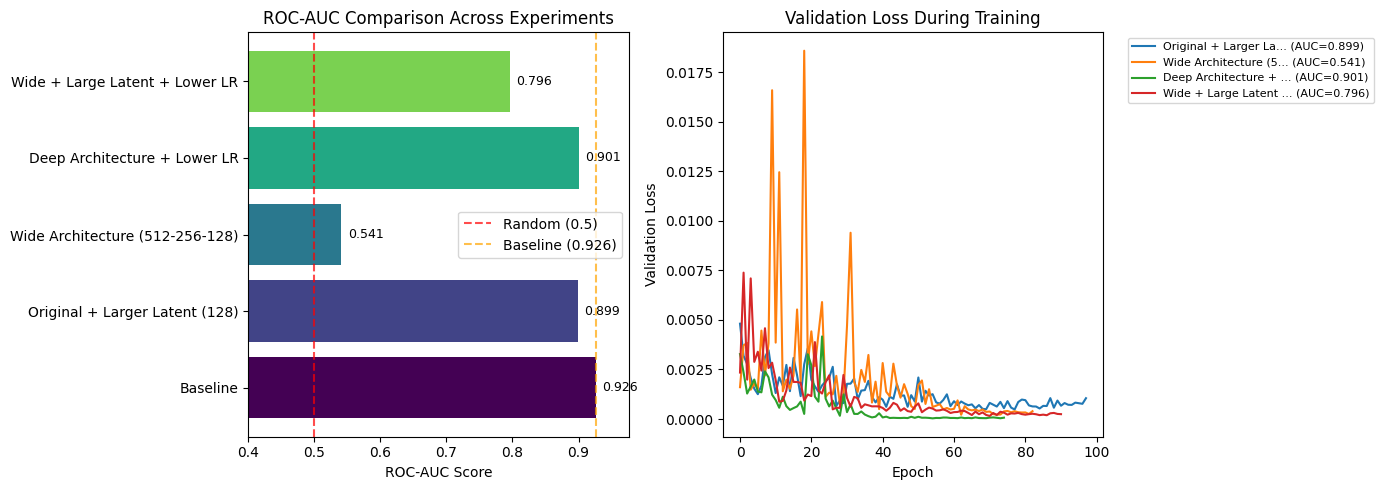


✓ Hyperparameter tuning results saved!


In [29]:
# 12.3 Compare all experiments

# Create comparison dataframe
results_df = pd.DataFrame(experiment_results)[['name', 'latent_dim', 'lr', 'roc_auc', 'final_val_loss']]
results_df = results_df.sort_values('roc_auc', ascending=False)

print("=" * 80)
print("HYPERPARAMETER TUNING RESULTS (sorted by ROC-AUC)")
print("=" * 80)
print(results_df.to_string(index=False))
print("=" * 80)

# Add baseline comparison
print(f"\nBaseline (original no-leakage model): ROC-AUC = {roc_auc_nl:.4f}")
print(f"Best experiment: {results_df.iloc[0]['name']} with ROC-AUC = {results_df.iloc[0]['roc_auc']:.4f}")

improvement = results_df.iloc[0]['roc_auc'] - roc_auc_nl
print(f"Improvement: {improvement:+.4f} ({improvement*100:+.2f}%)")

# Visualize comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC-AUC comparison
colors = plt.cm.viridis(np.linspace(0, 0.8, len(experiment_results) + 1))
all_names = ['Baseline'] + [r['name'] for r in experiment_results]
all_aucs = [roc_auc_nl] + [r['roc_auc'] for r in experiment_results]

bars = axes[0].barh(all_names, all_aucs, color=colors)
axes[0].set_xlabel('ROC-AUC Score')
axes[0].set_title('ROC-AUC Comparison Across Experiments')
axes[0].axvline(x=0.5, color='red', linestyle='--', alpha=0.7, label='Random (0.5)')
axes[0].axvline(x=roc_auc_nl, color='orange', linestyle='--', alpha=0.7, label=f'Baseline ({roc_auc_nl:.3f})')
axes[0].set_xlim(0.4, max(all_aucs) + 0.05)
axes[0].legend()

# Add values on bars
for bar, val in zip(bars, all_aucs):
    axes[0].text(val + 0.01, bar.get_y() + bar.get_height()/2, 
                 f'{val:.3f}', va='center', fontsize=9)

# Training curves for all experiments
for result in experiment_results:
    axes[1].plot(result['history']['val_loss'], 
                 label=f"{result['name'][:20]}... (AUC={result['roc_auc']:.3f})")

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation Loss')
axes[1].set_title('Validation Loss During Training')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.savefig('autoencoder_outputs/hyperparameter_tuning_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Hyperparameter tuning results saved!")

Best Model: Deep Architecture + Lower LR
ROC-AUC: 0.9007

Performance at Different Thresholds:
--------------------------------------------------
  90th percentile: Precision=0.776, Recall=0.353, F1=0.486
  95th percentile: Precision=0.983, Recall=0.224, F1=0.365
  97th percentile: Precision=0.991, Recall=0.135, F1=0.238
  99th percentile: Precision=0.973, Recall=0.044, F1=0.085


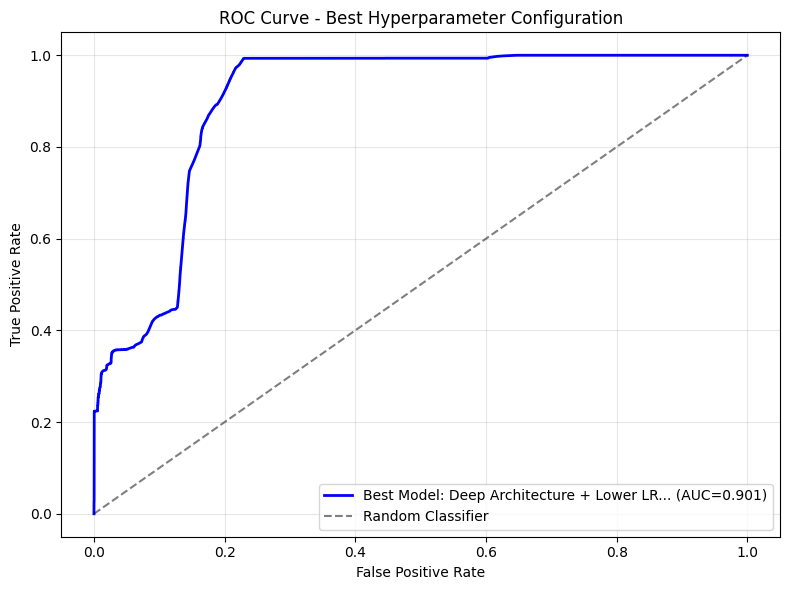


✓ Best model saved to 'autoencoder_outputs/best_tuned_model.pth'


In [30]:
# 12.4 Evaluate best model in detail

# Find best model
best_result = max(experiment_results, key=lambda x: x['roc_auc'])
best_model = best_result['model']

print(f"Best Model: {best_result['name']}")
print(f"ROC-AUC: {best_result['roc_auc']:.4f}")

# Extract latent vectors with best model (returns 2 values)
best_latent, best_recon_errors = extract_latent_vectors(best_model, X_nl)

# Calculate metrics at different thresholds
percentiles = [90, 95, 97, 99]
print("\nPerformance at Different Thresholds:")
print("-" * 50)

for p in percentiles:
    threshold = np.percentile(best_recon_errors, p)
    predictions = (best_recon_errors > threshold).astype(int)
    
    precision = precision_score(y_malicious_nl, predictions, zero_division=0)
    recall = recall_score(y_malicious_nl, predictions, zero_division=0)
    f1 = f1_score(y_malicious_nl, predictions, zero_division=0)
    
    print(f"  {p}th percentile: Precision={precision:.3f}, Recall={recall:.3f}, F1={f1:.3f}")

# ROC curve for best model
fpr_best, tpr_best, _ = roc_curve(y_malicious_nl, best_recon_errors)

plt.figure(figsize=(8, 6))
plt.plot(fpr_best, tpr_best, 'b-', linewidth=2, 
         label=f'Best Model: {best_result["name"][:30]}... (AUC={best_result["roc_auc"]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Best Hyperparameter Configuration')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('autoencoder_outputs/best_model_roc_curve.png', dpi=150)
plt.show()

# Save best model
torch.save(best_model.state_dict(), 'autoencoder_outputs/best_tuned_model.pth')
np.save('autoencoder_outputs/best_latent_vectors.npy', best_latent)
print(f"\n✓ Best model saved to 'autoencoder_outputs/best_tuned_model.pth'")

## Part 12.5: Complete Metrics Comparison for All Models

Calculate all classification metrics (Accuracy, Precision, Recall, F1-Score, Specificity, etc.) for each model configuration at the optimal threshold.

In [31]:
# 12.5.1 Calculate all metrics for all models

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score,
                             matthews_corrcoef, average_precision_score)

def calculate_all_metrics(y_true, y_pred, y_scores):
    """Calculate comprehensive classification metrics."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall (Sensitivity)': recall_score(y_true, y_pred, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0,
        'F1-Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_scores),
        'PR-AUC': average_precision_score(y_true, y_scores),
        'MCC': matthews_corrcoef(y_true, y_pred),
        'True Positives': tp,
        'True Negatives': tn,
        'False Positives': fp,
        'False Negatives': fn
    }
    return metrics

def find_optimal_threshold(y_true, y_scores):
    """Find threshold that maximizes F1-score."""
    from sklearn.metrics import precision_recall_curve
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_scores)
    
    # Calculate F1 for each threshold
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
    
    # Find best threshold
    best_idx = np.argmax(f1_scores[:-1])  # Exclude last (undefined)
    return thresholds[best_idx]

# Calculate metrics for all experiment models
all_model_metrics = []

# Add baseline model (original no-leakage)
baseline_latent, baseline_errors = extract_latent_vectors(model_no_leak, X_nl)
baseline_threshold = find_optimal_threshold(y_malicious_nl, baseline_errors)
baseline_preds = (baseline_errors > baseline_threshold).astype(int)
baseline_metrics = calculate_all_metrics(y_malicious_nl, baseline_preds, baseline_errors)
baseline_metrics['Model'] = 'Baseline (No-Leakage)'
baseline_metrics['Latent Dim'] = 64
baseline_metrics['Optimal Threshold'] = baseline_threshold
all_model_metrics.append(baseline_metrics)

# Calculate for all tuned models
for result in experiment_results:
    model = result['model']
    name = result['name']
    latent_dim = result['latent_dim']
    
    # Extract reconstruction errors
    latent, recon_errors = extract_latent_vectors(model, X_nl)
    
    # Find optimal threshold
    optimal_threshold = find_optimal_threshold(y_malicious_nl, recon_errors)
    
    # Make predictions
    predictions = (recon_errors > optimal_threshold).astype(int)
    
    # Calculate metrics
    metrics = calculate_all_metrics(y_malicious_nl, predictions, recon_errors)
    metrics['Model'] = name
    metrics['Latent Dim'] = latent_dim
    metrics['Optimal Threshold'] = optimal_threshold
    
    all_model_metrics.append(metrics)

# Create DataFrame
metrics_df = pd.DataFrame(all_model_metrics)

# Reorder columns
cols_order = ['Model', 'Latent Dim', 'Accuracy', 'Balanced Accuracy', 'Precision', 
              'Recall (Sensitivity)', 'Specificity', 'F1-Score', 'ROC-AUC', 'PR-AUC', 
              'MCC', 'Optimal Threshold', 'True Positives', 'True Negatives', 
              'False Positives', 'False Negatives']
metrics_df = metrics_df[cols_order]

print("=" * 100)
print("COMPLETE METRICS COMPARISON FOR ALL MODELS")
print("=" * 100)
print("\nNote: Predictions are made using the optimal threshold (maximizes F1-Score)")
print()

# Display main metrics
display_cols = ['Model', 'Accuracy', 'Precision', 'Recall (Sensitivity)', 'Specificity', 
                'F1-Score', 'ROC-AUC', 'MCC']
print(metrics_df[display_cols].to_string(index=False))

print("\n" + "=" * 100)

COMPLETE METRICS COMPARISON FOR ALL MODELS

Note: Predictions are made using the optimal threshold (maximizes F1-Score)

                          Model  Accuracy  Precision  Recall (Sensitivity)  Specificity  F1-Score  ROC-AUC      MCC
          Baseline (No-Leakage)  0.859617   0.610961              0.993430     0.821954  0.756607 0.926115 0.704512
 Original + Larger Latent (128)  0.820291   0.550361              0.993391     0.771571  0.708305 0.898696 0.647429
Wide Architecture (512-256-128)  0.840174   0.790645              0.370407     0.972394  0.504474 0.540579 0.467111
   Deep Architecture + Lower LR  0.824594   0.557783              0.972028     0.783098  0.708820 0.900671 0.643180
 Wide + Large Latent + Lower LR  0.604056   0.350345              0.939570     0.509623  0.510381 0.796059 0.377975



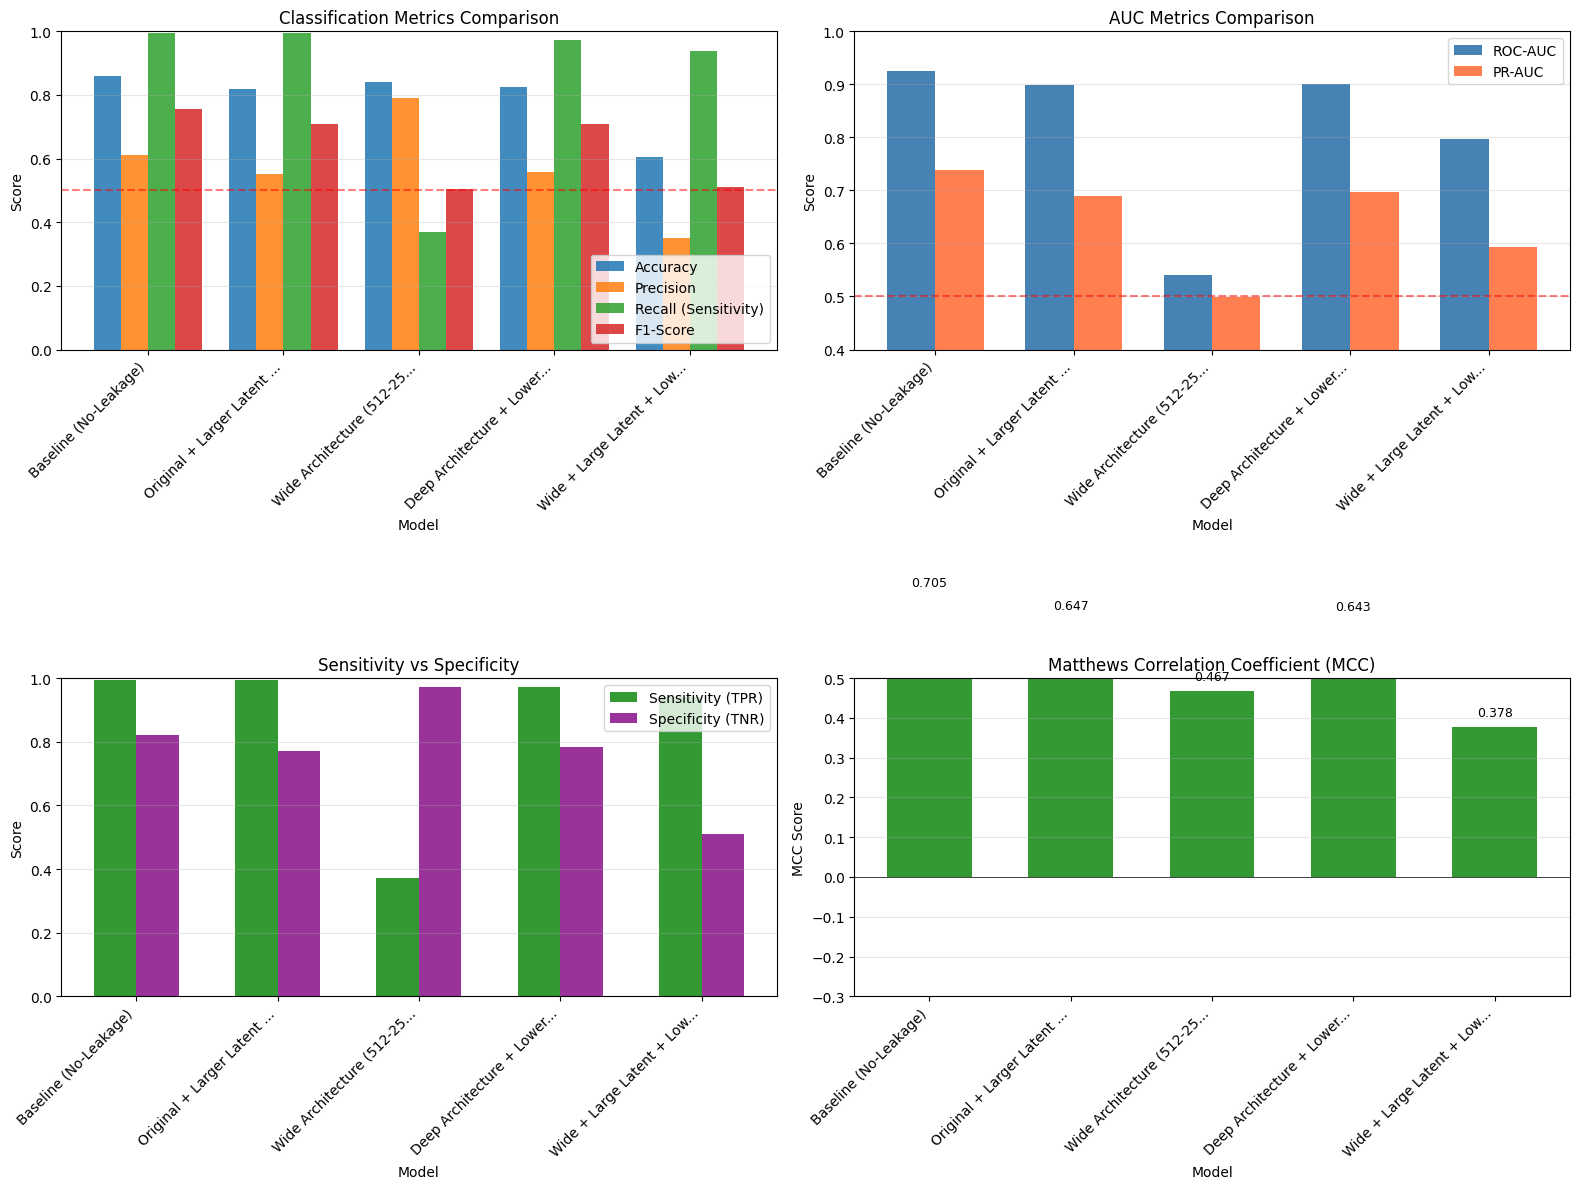

✓ Metrics visualization saved!


In [32]:
# 12.5.2 Visualize metrics comparison

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# List of models
models = metrics_df['Model'].tolist()
x = np.arange(len(models))
width = 0.6

# 1. Accuracy, Precision, Recall, F1
ax1 = axes[0, 0]
metrics_to_plot = ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'F1-Score']
x_multi = np.arange(len(models))
width_multi = 0.2

for i, metric in enumerate(metrics_to_plot):
    values = metrics_df[metric].values
    ax1.bar(x_multi + i*width_multi, values, width_multi, label=metric, alpha=0.85)

ax1.set_xlabel('Model')
ax1.set_ylabel('Score')
ax1.set_title('Classification Metrics Comparison')
ax1.set_xticks(x_multi + width_multi*1.5)
ax1.set_xticklabels([m[:25] + '...' if len(m) > 25 else m for m in models], rotation=45, ha='right')
ax1.legend(loc='lower right')
ax1.set_ylim(0, 1)
ax1.grid(True, alpha=0.3, axis='y')
ax1.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random baseline')

# 2. ROC-AUC and PR-AUC
ax2 = axes[0, 1]
x_auc = np.arange(len(models))
width_auc = 0.35
ax2.bar(x_auc - width_auc/2, metrics_df['ROC-AUC'].values, width_auc, label='ROC-AUC', color='steelblue')
ax2.bar(x_auc + width_auc/2, metrics_df['PR-AUC'].values, width_auc, label='PR-AUC', color='coral')
ax2.set_xlabel('Model')
ax2.set_ylabel('Score')
ax2.set_title('AUC Metrics Comparison')
ax2.set_xticks(x_auc)
ax2.set_xticklabels([m[:25] + '...' if len(m) > 25 else m for m in models], rotation=45, ha='right')
ax2.legend()
ax2.set_ylim(0.4, 1)
ax2.axhline(y=0.5, color='red', linestyle='--', alpha=0.5)
ax2.grid(True, alpha=0.3, axis='y')

# 3. Sensitivity vs Specificity
ax3 = axes[1, 0]
ax3.bar(x - width/4, metrics_df['Recall (Sensitivity)'].values, width/2, label='Sensitivity (TPR)', color='green', alpha=0.8)
ax3.bar(x + width/4, metrics_df['Specificity'].values, width/2, label='Specificity (TNR)', color='purple', alpha=0.8)
ax3.set_xlabel('Model')
ax3.set_ylabel('Score')
ax3.set_title('Sensitivity vs Specificity')
ax3.set_xticks(x)
ax3.set_xticklabels([m[:25] + '...' if len(m) > 25 else m for m in models], rotation=45, ha='right')
ax3.legend()
ax3.set_ylim(0, 1)
ax3.grid(True, alpha=0.3, axis='y')

# 4. Matthews Correlation Coefficient (MCC)
ax4 = axes[1, 1]
colors = ['green' if v > 0 else 'red' for v in metrics_df['MCC'].values]
bars = ax4.bar(x, metrics_df['MCC'].values, width, color=colors, alpha=0.8)
ax4.set_xlabel('Model')
ax4.set_ylabel('MCC Score')
ax4.set_title('Matthews Correlation Coefficient (MCC)')
ax4.set_xticks(x)
ax4.set_xticklabels([m[:25] + '...' if len(m) > 25 else m for m in models], rotation=45, ha='right')
ax4.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax4.set_ylim(-0.3, 0.5)
ax4.grid(True, alpha=0.3, axis='y')

# Add value labels on MCC bars
for bar, val in zip(bars, metrics_df['MCC'].values):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
             f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('autoencoder_outputs/all_models_metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Metrics visualization saved!")

In [33]:
# 12.5.3 Detailed metrics table and best model summary

print("=" * 100)
print("DETAILED METRICS TABLE")
print("=" * 100)

# Full metrics with confusion matrix details
print("\nConfusion Matrix Details:")
print("-" * 100)
cm_cols = ['Model', 'True Positives', 'True Negatives', 'False Positives', 'False Negatives', 'Optimal Threshold']
print(metrics_df[cm_cols].to_string(index=False))

# Find best model for each metric
print("\n" + "=" * 100)
print("BEST MODEL FOR EACH METRIC")
print("=" * 100)

metrics_to_rank = ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'F1-Score', 
                   'ROC-AUC', 'PR-AUC', 'MCC', 'Balanced Accuracy']

for metric in metrics_to_rank:
    best_idx = metrics_df[metric].idxmax()
    best_model = metrics_df.loc[best_idx, 'Model']
    best_value = metrics_df.loc[best_idx, metric]
    print(f"  {metric:25s}: {best_model:40s} ({best_value:.4f})")

# Overall winner (by F1-Score as it balances precision/recall)
print("\n" + "=" * 100)
best_overall_idx = metrics_df['F1-Score'].idxmax()
best_overall = metrics_df.loc[best_overall_idx]

print(f"🏆 BEST OVERALL MODEL (by F1-Score): {best_overall['Model']}")
print("=" * 100)
print(f"\n  📊 Key Metrics:")
print(f"     • Accuracy:        {best_overall['Accuracy']:.4f} ({best_overall['Accuracy']*100:.2f}%)")
print(f"     • Precision:       {best_overall['Precision']:.4f} ({best_overall['Precision']*100:.2f}%)")
print(f"     • Recall:          {best_overall['Recall (Sensitivity)']:.4f} ({best_overall['Recall (Sensitivity)']*100:.2f}%)")
print(f"     • Specificity:     {best_overall['Specificity']:.4f} ({best_overall['Specificity']*100:.2f}%)")
print(f"     • F1-Score:        {best_overall['F1-Score']:.4f}")
print(f"     • ROC-AUC:         {best_overall['ROC-AUC']:.4f}")
print(f"     • PR-AUC:          {best_overall['PR-AUC']:.4f}")
print(f"     • MCC:             {best_overall['MCC']:.4f}")
print(f"\n  📈 Confusion Matrix:")
print(f"     • True Positives:  {int(best_overall['True Positives']):,}")
print(f"     • True Negatives:  {int(best_overall['True Negatives']):,}")
print(f"     • False Positives: {int(best_overall['False Positives']):,}")
print(f"     • False Negatives: {int(best_overall['False Negatives']):,}")

# Save metrics to CSV
metrics_df.to_csv('autoencoder_outputs/all_models_metrics.csv', index=False)
print(f"\n✓ Metrics saved to 'autoencoder_outputs/all_models_metrics.csv'")

DETAILED METRICS TABLE

Confusion Matrix Details:
----------------------------------------------------------------------------------------------------
                          Model  True Positives  True Negatives  False Positives  False Negatives  Optimal Threshold
          Baseline (No-Leakage)           25251           74229            16079              167           0.000298
 Original + Larger Latent (128)           25250           69679            20629              168           0.000040
Wide Architecture (512-256-128)            9415           87815             2493            16003           0.000068
   Deep Architecture + Lower LR           24707           70720            19588              711           0.000035
 Wide + Large Latent + Lower LR           23882           46023            44285             1536           0.000008

BEST MODEL FOR EACH METRIC
  Accuracy                 : Baseline (No-Leakage)                    (0.8596)
  Precision                : Wide Archit

## Part 13: Encoding/Decoding Quality Analysis (64 vs 128 Latent Dimensions)

To measure the quality of the autoencoder's encoding and decoding, we'll evaluate:

1. **Reconstruction Quality Metrics:**
   - Mean Squared Error (MSE)
   - Mean Absolute Error (MAE)
   - R² Score (coefficient of determination)
   - Explained Variance Score
   - Cosine Similarity between original and reconstructed

2. **Information Preservation:**
   - Feature-wise correlation between original and reconstructed
   - Variance preserved in latent space

3. **Compression Quality:**
   - Compression ratio
   - Bits per dimension

In [34]:
# 13.1 Train autoencoders with 64 and 128 latent dimensions for comparison

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score
from scipy.stats import pearsonr
from scipy.spatial.distance import cosine

def get_reconstruction(model, X, device='cpu'):
    """Get reconstructed data from autoencoder."""
    model.eval()
    tensor_x = torch.FloatTensor(X).to(device)
    
    with torch.no_grad():
        reconstructed, latent = model(tensor_x)
    
    return reconstructed.cpu().numpy(), latent.cpu().numpy()

def calculate_reconstruction_quality(X_original, X_reconstructed, latent_vectors):
    """Calculate comprehensive reconstruction quality metrics."""
    
    # Flatten for overall metrics
    orig_flat = X_original.flatten()
    recon_flat = X_reconstructed.flatten()
    
    # 1. Error Metrics
    mse = mean_squared_error(X_original, X_reconstructed)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(X_original, X_reconstructed)
    
    # 2. Correlation Metrics
    r2 = r2_score(orig_flat, recon_flat)
    explained_var = explained_variance_score(orig_flat, recon_flat)
    
    # 3. Cosine Similarity (per sample, then average)
    cosine_sims = []
    for i in range(len(X_original)):
        if np.linalg.norm(X_original[i]) > 0 and np.linalg.norm(X_reconstructed[i]) > 0:
            cos_sim = 1 - cosine(X_original[i], X_reconstructed[i])
            cosine_sims.append(cos_sim)
    avg_cosine_sim = np.mean(cosine_sims)
    
    # 4. Feature-wise Pearson Correlation
    feature_correlations = []
    for j in range(X_original.shape[1]):
        if np.std(X_original[:, j]) > 0 and np.std(X_reconstructed[:, j]) > 0:
            corr, _ = pearsonr(X_original[:, j], X_reconstructed[:, j])
            if not np.isnan(corr):
                feature_correlations.append(corr)
    avg_feature_corr = np.mean(feature_correlations) if feature_correlations else 0
    
    # 5. Latent Space Statistics
    latent_variance = np.var(latent_vectors, axis=0).mean()
    latent_std = np.std(latent_vectors, axis=0).mean()
    
    # 6. Compression Ratio
    input_dim = X_original.shape[1]
    latent_dim = latent_vectors.shape[1]
    compression_ratio = input_dim / latent_dim
    
    # 7. Signal-to-Noise Ratio (SNR)
    signal_power = np.mean(X_original ** 2)
    noise_power = mse
    snr_db = 10 * np.log10(signal_power / noise_power) if noise_power > 0 else float('inf')
    
    return {
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R² Score': r2,
        'Explained Variance': explained_var,
        'Avg Cosine Similarity': avg_cosine_sim,
        'Avg Feature Correlation': avg_feature_corr,
        'Latent Variance (mean)': latent_variance,
        'Latent Std (mean)': latent_std,
        'Compression Ratio': compression_ratio,
        'SNR (dB)': snr_db,
        'Input Dim': input_dim,
        'Latent Dim': latent_dim
    }

print("✓ Quality measurement functions defined!")

✓ Quality measurement functions defined!


In [35]:
# 13.2 Train models with both 64 and 128 latent dimensions

print("=" * 80)
print("TRAINING AUTOENCODERS FOR QUALITY COMPARISON")
print("=" * 80)

# Use the no-leakage features
input_dim = X_nl.shape[1]

# Train model with 64 latent dimensions
print("\n🔧 Training Autoencoder with latent_dim = 64...")
model_64 = SIEMAutoencoder(input_dim=input_dim, latent_dim=64, dropout_rate=0.2)
model_64, history_64 = train_autoencoder_v2(
    model_64, train_loader_nl, val_loader_nl,
    epochs=100, lr=1e-3, patience=20
)

# Train model with 128 latent dimensions  
print("\n🔧 Training Autoencoder with latent_dim = 128...")
model_128 = SIEMAutoencoder(input_dim=input_dim, latent_dim=128, dropout_rate=0.2)
model_128, history_128 = train_autoencoder_v2(
    model_128, train_loader_nl, val_loader_nl,
    epochs=100, lr=1e-3, patience=20
)

print("\n✓ Both models trained successfully!")

TRAINING AUTOENCODERS FOR QUALITY COMPARISON

🔧 Training Autoencoder with latent_dim = 64...
  Epoch  20: Train Loss = 0.001053, Val Loss = 0.002111
  Early stopping at epoch 27

🔧 Training Autoencoder with latent_dim = 128...
  Epoch  20: Train Loss = 0.001115, Val Loss = 0.001758
  Epoch  40: Train Loss = 0.000726, Val Loss = 0.001127
  Epoch  60: Train Loss = 0.000692, Val Loss = 0.000772
  Epoch  80: Train Loss = 0.000693, Val Loss = 0.000875
  Early stopping at epoch 82

✓ Both models trained successfully!


In [36]:
# 13.3 Calculate reconstruction quality for both models

print("=" * 80)
print("ENCODING/DECODING QUALITY COMPARISON: 64 vs 128 LATENT DIMENSIONS")
print("=" * 80)

# Get reconstructions for latent_dim = 64
X_recon_64, latent_64 = get_reconstruction(model_64, X_nl)
quality_64 = calculate_reconstruction_quality(X_nl, X_recon_64, latent_64)

# Get reconstructions for latent_dim = 128
X_recon_128, latent_128 = get_reconstruction(model_128, X_nl)
quality_128 = calculate_reconstruction_quality(X_nl, X_recon_128, latent_128)

# Create comparison dataframe
quality_comparison = pd.DataFrame({
    'Metric': list(quality_64.keys()),
    'Latent Dim = 64': list(quality_64.values()),
    'Latent Dim = 128': list(quality_128.values())
})

# Calculate improvement (lower is better for errors, higher is better for correlations)
improvements = []
for metric, val_64, val_128 in zip(quality_64.keys(), quality_64.values(), quality_128.values()):
    if metric in ['MSE', 'RMSE', 'MAE']:  # Lower is better
        if val_64 != 0:
            imp = ((val_64 - val_128) / val_64) * 100
            improvements.append(f"{imp:+.2f}%")
        else:
            improvements.append("N/A")
    elif metric in ['R² Score', 'Explained Variance', 'Avg Cosine Similarity', 
                    'Avg Feature Correlation', 'SNR (dB)']:  # Higher is better
        if val_64 != 0:
            imp = ((val_128 - val_64) / abs(val_64)) * 100
            improvements.append(f"{imp:+.2f}%")
        else:
            improvements.append("N/A")
    else:
        improvements.append("-")

quality_comparison['128 vs 64 (Improvement)'] = improvements

print("\n📊 RECONSTRUCTION QUALITY METRICS:")
print("-" * 80)
print(quality_comparison.to_string(index=False))
print("-" * 80)

ENCODING/DECODING QUALITY COMPARISON: 64 vs 128 LATENT DIMENSIONS

📊 RECONSTRUCTION QUALITY METRICS:
--------------------------------------------------------------------------------
                 Metric  Latent Dim = 64  Latent Dim = 128 128 vs 64 (Improvement)
                    MSE         0.008588          0.007558                 +11.99%
                   RMSE         0.092672          0.086938                  +6.19%
                    MAE         0.005634          0.004869                 +13.58%
               R² Score         0.853942          0.871459                  +2.05%
     Explained Variance         0.853961          0.871481                  +2.05%
  Avg Cosine Similarity         0.987382          0.989013                  +0.17%
Avg Feature Correlation         0.183246          0.213754                 +16.65%
 Latent Variance (mean)         0.985711          1.119932                       -
      Latent Std (mean)         0.945188          1.029076             

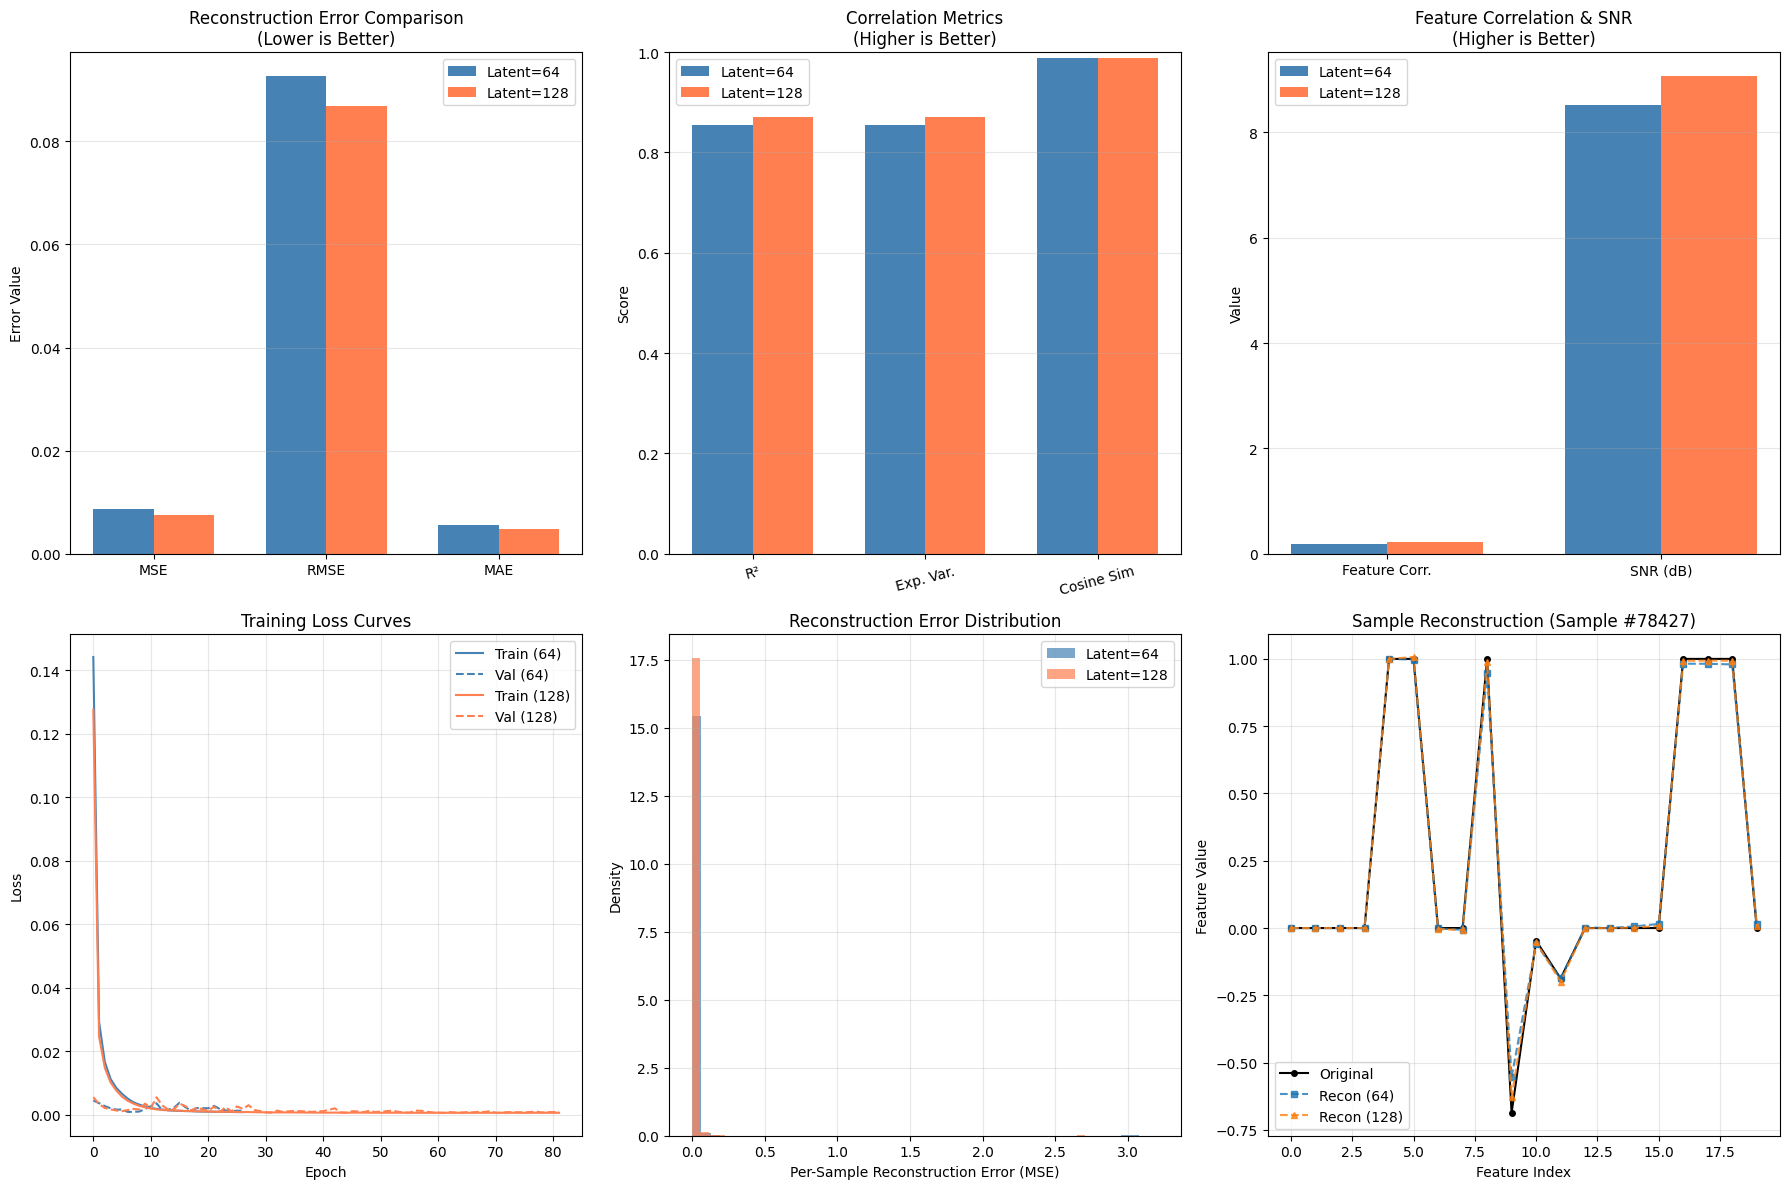

✓ Quality visualization saved!


In [37]:
# 13.4 Visualize reconstruction quality comparison

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Error Metrics Comparison (MSE, RMSE, MAE)
ax1 = axes[0, 0]
error_metrics = ['MSE', 'RMSE', 'MAE']
x_pos = np.arange(len(error_metrics))
width = 0.35
bars1 = ax1.bar(x_pos - width/2, [quality_64[m] for m in error_metrics], width, label='Latent=64', color='steelblue')
bars2 = ax1.bar(x_pos + width/2, [quality_128[m] for m in error_metrics], width, label='Latent=128', color='coral')
ax1.set_ylabel('Error Value')
ax1.set_title('Reconstruction Error Comparison\n(Lower is Better)')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(error_metrics)
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')

# 2. Correlation Metrics (R², Explained Variance, Cosine Sim)
ax2 = axes[0, 1]
corr_metrics = ['R² Score', 'Explained Variance', 'Avg Cosine Similarity']
x_pos = np.arange(len(corr_metrics))
bars1 = ax2.bar(x_pos - width/2, [quality_64[m] for m in corr_metrics], width, label='Latent=64', color='steelblue')
bars2 = ax2.bar(x_pos + width/2, [quality_128[m] for m in corr_metrics], width, label='Latent=128', color='coral')
ax2.set_ylabel('Score')
ax2.set_title('Correlation Metrics\n(Higher is Better)')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(['R²', 'Exp. Var.', 'Cosine Sim'], rotation=15)
ax2.set_ylim(0, 1)
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

# 3. Feature Correlation and SNR
ax3 = axes[0, 2]
other_metrics = ['Avg Feature Correlation', 'SNR (dB)']
x_pos = np.arange(len(other_metrics))
bars1 = ax3.bar(x_pos - width/2, [quality_64['Avg Feature Correlation'], quality_64['SNR (dB)']], 
                width, label='Latent=64', color='steelblue')
bars2 = ax3.bar(x_pos + width/2, [quality_128['Avg Feature Correlation'], quality_128['SNR (dB)']], 
                width, label='Latent=128', color='coral')
ax3.set_ylabel('Value')
ax3.set_title('Feature Correlation & SNR\n(Higher is Better)')
ax3.set_xticks(x_pos)
ax3.set_xticklabels(['Feature Corr.', 'SNR (dB)'])
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')

# 4. Training Loss Comparison
ax4 = axes[1, 0]
ax4.plot(history_64['train_loss'], label='Train (64)', color='steelblue', linestyle='-')
ax4.plot(history_64['val_loss'], label='Val (64)', color='steelblue', linestyle='--')
ax4.plot(history_128['train_loss'], label='Train (128)', color='coral', linestyle='-')
ax4.plot(history_128['val_loss'], label='Val (128)', color='coral', linestyle='--')
ax4.set_xlabel('Epoch')
ax4.set_ylabel('Loss')
ax4.set_title('Training Loss Curves')
ax4.legend()
ax4.grid(True, alpha=0.3)

# 5. Reconstruction Error Distribution
ax5 = axes[1, 1]
recon_error_64 = np.mean((X_nl - X_recon_64) ** 2, axis=1)
recon_error_128 = np.mean((X_nl - X_recon_128) ** 2, axis=1)
ax5.hist(recon_error_64, bins=50, alpha=0.7, label='Latent=64', color='steelblue', density=True)
ax5.hist(recon_error_128, bins=50, alpha=0.7, label='Latent=128', color='coral', density=True)
ax5.set_xlabel('Per-Sample Reconstruction Error (MSE)')
ax5.set_ylabel('Density')
ax5.set_title('Reconstruction Error Distribution')
ax5.legend()
ax5.grid(True, alpha=0.3)

# 6. Sample Reconstruction Comparison (first 10 features of random samples)
ax6 = axes[1, 2]
sample_idx = np.random.choice(len(X_nl), size=1)[0]
n_features = min(20, X_nl.shape[1])
x_feat = np.arange(n_features)
ax6.plot(x_feat, X_nl[sample_idx, :n_features], 'ko-', label='Original', markersize=4)
ax6.plot(x_feat, X_recon_64[sample_idx, :n_features], 's--', label='Recon (64)', markersize=4, alpha=0.8)
ax6.plot(x_feat, X_recon_128[sample_idx, :n_features], '^--', label='Recon (128)', markersize=4, alpha=0.8)
ax6.set_xlabel('Feature Index')
ax6.set_ylabel('Feature Value')
ax6.set_title(f'Sample Reconstruction (Sample #{sample_idx})')
ax6.legend()
ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/encoding_quality_comparison_64_vs_128.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Quality visualization saved!")

In [38]:
# 13.5 Quality Summary and Recommendations

print("=" * 80)
print("ENCODING/DECODING QUALITY SUMMARY")
print("=" * 80)

print("\n📊 KEY METRICS COMPARISON:")
print("-" * 60)
print(f"{'Metric':<30} {'Latent=64':>15} {'Latent=128':>15}")
print("-" * 60)
print(f"{'MSE (↓ better)':<30} {quality_64['MSE']:>15.6f} {quality_128['MSE']:>15.6f}")
print(f"{'RMSE (↓ better)':<30} {quality_64['RMSE']:>15.6f} {quality_128['RMSE']:>15.6f}")
print(f"{'MAE (↓ better)':<30} {quality_64['MAE']:>15.6f} {quality_128['MAE']:>15.6f}")
print(f"{'R² Score (↑ better)':<30} {quality_64['R² Score']:>15.4f} {quality_128['R² Score']:>15.4f}")
print(f"{'Cosine Similarity (↑ better)':<30} {quality_64['Avg Cosine Similarity']:>15.4f} {quality_128['Avg Cosine Similarity']:>15.4f}")
print(f"{'Feature Correlation (↑ better)':<30} {quality_64['Avg Feature Correlation']:>15.4f} {quality_128['Avg Feature Correlation']:>15.4f}")
print(f"{'SNR in dB (↑ better)':<30} {quality_64['SNR (dB)']:>15.2f} {quality_128['SNR (dB)']:>15.2f}")
print(f"{'Compression Ratio':<30} {quality_64['Compression Ratio']:>15.2f}x {quality_128['Compression Ratio']:>15.2f}x")
print("-" * 60)

# Determine winner
mse_winner = "64" if quality_64['MSE'] < quality_128['MSE'] else "128"
r2_winner = "128" if quality_128['R² Score'] > quality_64['R² Score'] else "64"
cosine_winner = "128" if quality_128['Avg Cosine Similarity'] > quality_64['Avg Cosine Similarity'] else "64"

print("\n🏆 QUALITY ASSESSMENT:")
print("-" * 60)

# Overall quality rating
if quality_64['R² Score'] > 0.9 or quality_128['R² Score'] > 0.9:
    rating = "EXCELLENT"
    color = "🟢"
elif quality_64['R² Score'] > 0.7 or quality_128['R² Score'] > 0.7:
    rating = "GOOD"
    color = "🟡"
elif quality_64['R² Score'] > 0.5 or quality_128['R² Score'] > 0.5:
    rating = "MODERATE"
    color = "🟠"
else:
    rating = "NEEDS IMPROVEMENT"
    color = "🔴"

print(f"   Overall Reconstruction Quality: {color} {rating}")
print(f"   Lower Error: Latent={mse_winner}")
print(f"   Better R²: Latent={r2_winner}")
print(f"   Better Cosine Similarity: Latent={cosine_winner}")

print("\n💡 INTERPRETATION:")
print("-" * 60)
print(f"   • R² Score > 0.9: Excellent reconstruction (almost perfect)")
print(f"   • R² Score 0.7-0.9: Good reconstruction (minor information loss)")
print(f"   • R² Score 0.5-0.7: Moderate reconstruction (some information loss)")
print(f"   • R² Score < 0.5: Poor reconstruction (significant information loss)")
print(f"\n   Your best R² Score: {max(quality_64['R² Score'], quality_128['R² Score']):.4f}")

print("\n📌 RECOMMENDATION:")
print("-" * 60)
if quality_128['R² Score'] > quality_64['R² Score'] and quality_128['MSE'] < quality_64['MSE']:
    print("   ✓ Use latent_dim=128 for better reconstruction quality")
elif quality_64['R² Score'] > quality_128['R² Score']:
    print("   ✓ Use latent_dim=64 (better reconstruction despite higher compression)")
else:
    print("   ✓ Both perform similarly - use latent_dim=64 for better compression")

print("=" * 80)

# Save quality metrics
quality_df = quality_comparison.copy()
quality_df.to_csv('autoencoder_outputs/encoding_quality_metrics.csv', index=False)
print("\n✓ Quality metrics saved to 'autoencoder_outputs/encoding_quality_metrics.csv'")

ENCODING/DECODING QUALITY SUMMARY

📊 KEY METRICS COMPARISON:
------------------------------------------------------------
Metric                               Latent=64      Latent=128
------------------------------------------------------------
MSE (↓ better)                        0.008588        0.007558
RMSE (↓ better)                       0.092672        0.086938
MAE (↓ better)                        0.005634        0.004869
R² Score (↑ better)                     0.8539          0.8715
Cosine Similarity (↑ better)            0.9874          0.9890
Feature Correlation (↑ better)          0.1832          0.2138
SNR in dB (↑ better)                      8.52            9.07
Compression Ratio                         3.38x            1.69x
------------------------------------------------------------

🏆 QUALITY ASSESSMENT:
------------------------------------------------------------
   Overall Reconstruction Quality: 🟡 GOOD
   Lower Error: Latent=128
   Better R²: Latent=128
   Better

## Part 14: Comprehensive Visualizations

This section provides complete visualizations across all domains:
1. **Data Preprocessing** - Raw data distribution, class balance, feature statistics
2. **Encoding** - Latent space visualization, t-SNE, PCA, feature importance
3. **Decoding** - Reconstruction quality, error analysis, sample comparisons
4. **Classification** - ROC curves, confusion matrices, precision-recall, decision boundaries

14.1 DATA PREPROCESSING VISUALIZATIONS


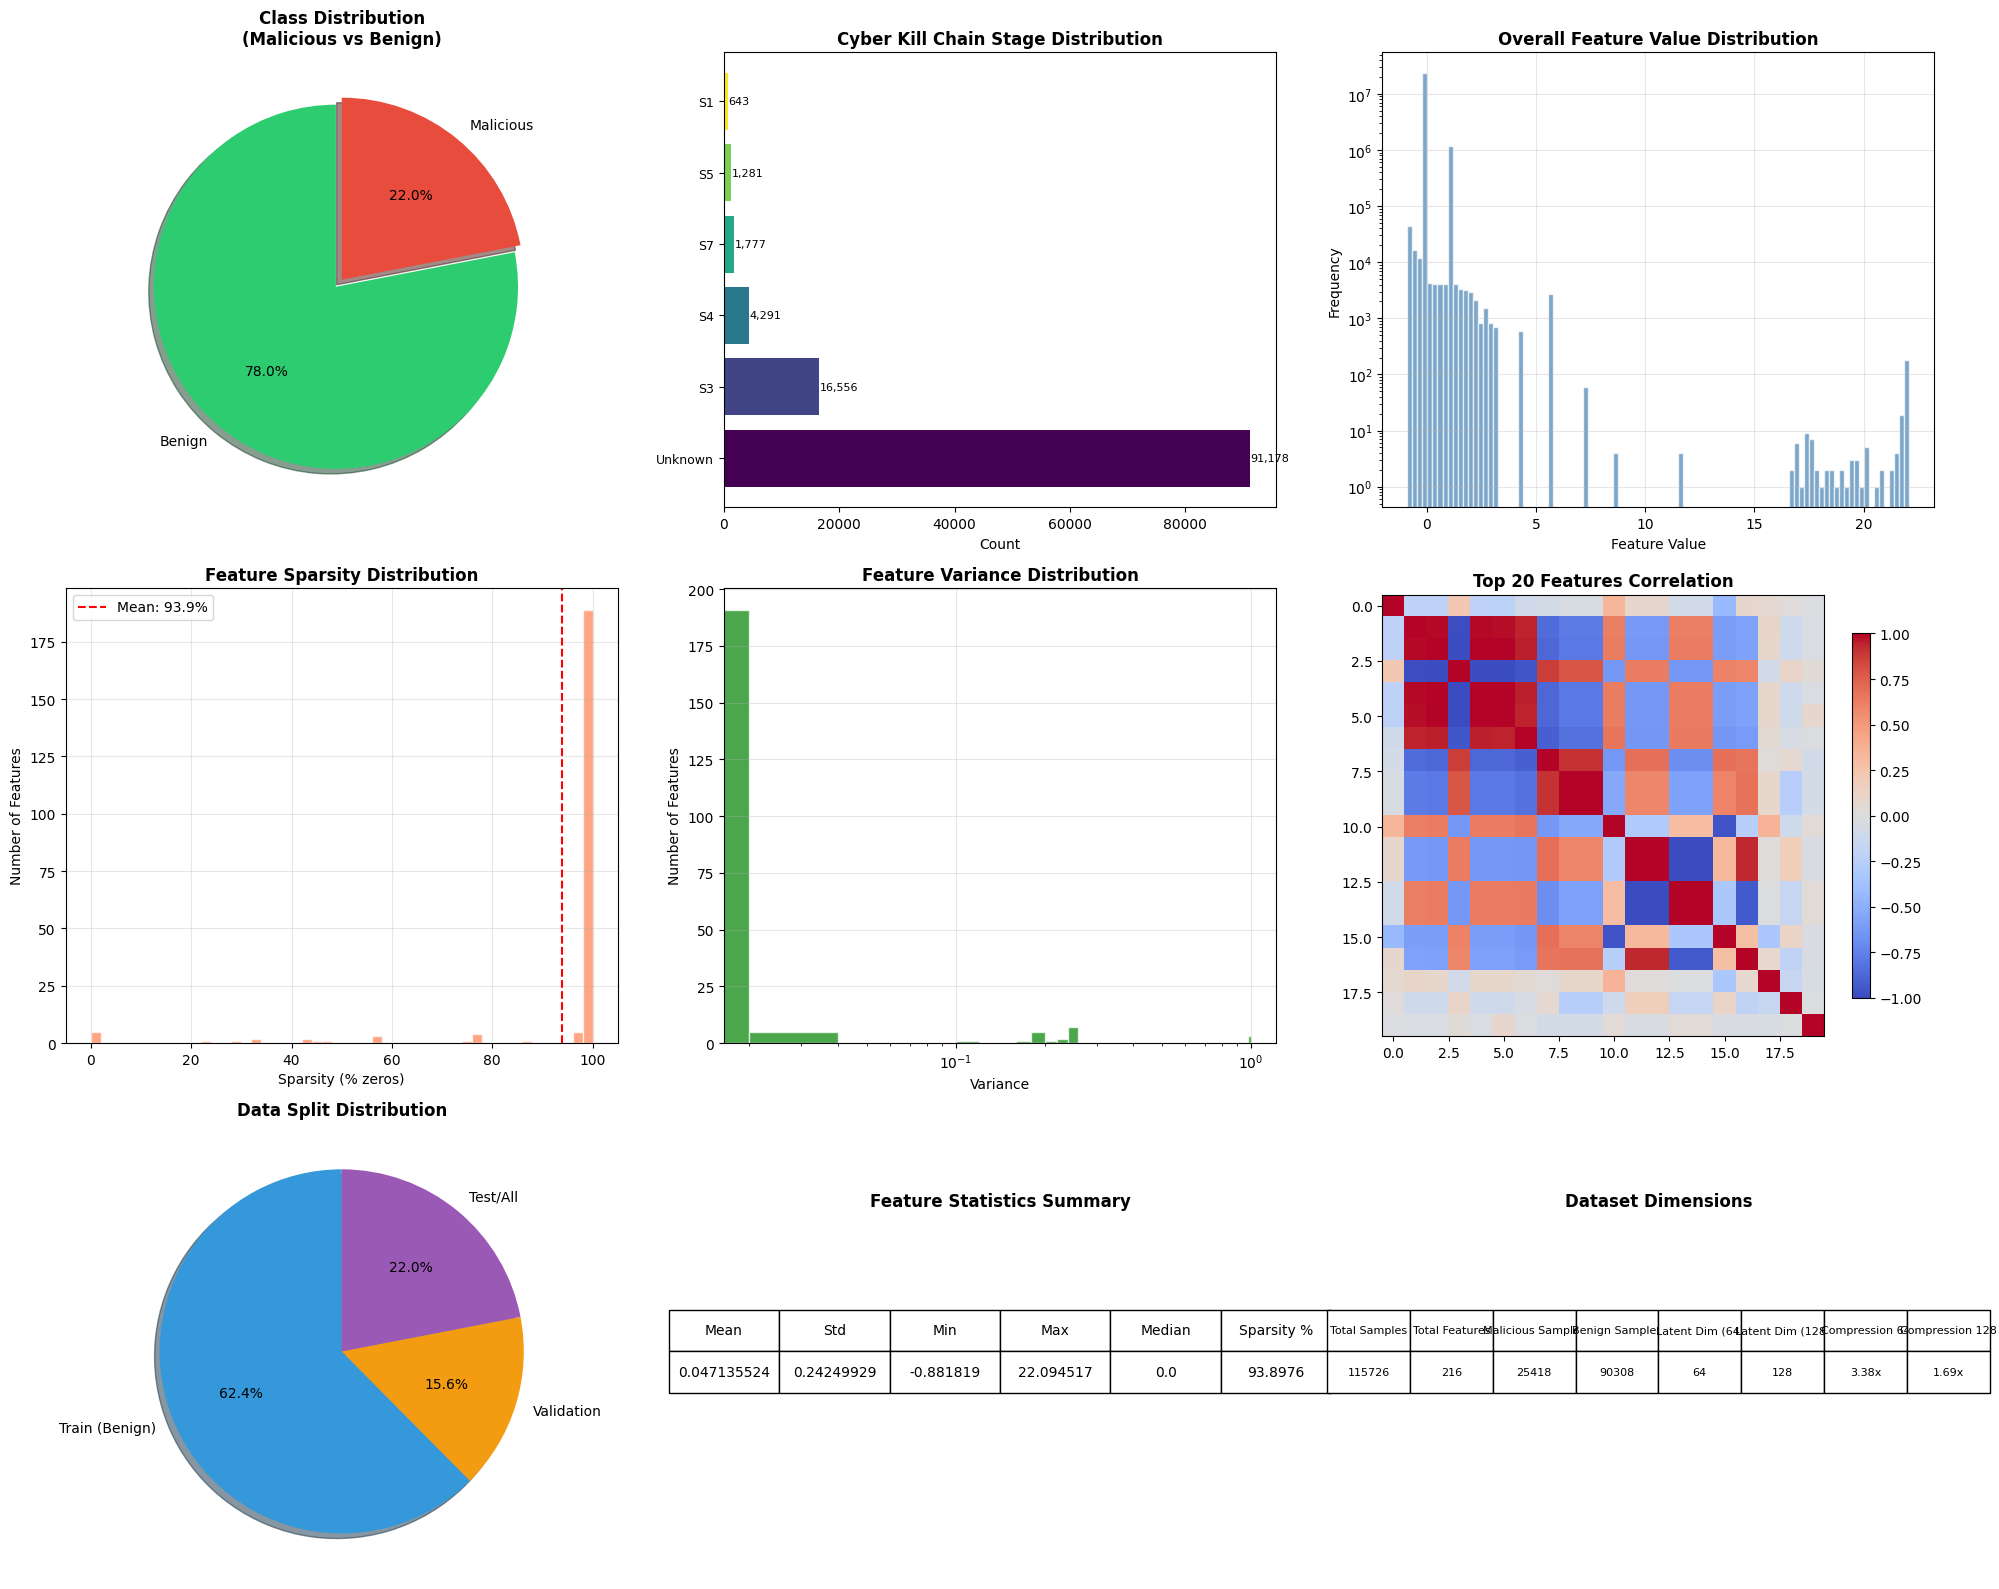

✓ Data preprocessing visualizations saved!


In [39]:
# 14.1 DATA PREPROCESSING VISUALIZATIONS

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns

print("=" * 80)
print("14.1 DATA PREPROCESSING VISUALIZATIONS")
print("=" * 80)

fig = plt.figure(figsize=(20, 16))

# 1. Class Distribution (Malicious vs Benign)
ax1 = fig.add_subplot(3, 3, 1)
class_counts = pd.Series(y_malicious_nl).value_counts()
colors_pie = ['#2ecc71', '#e74c3c']  # Green for benign, Red for malicious
wedges, texts, autotexts = ax1.pie(class_counts.values, labels=['Benign', 'Malicious'], 
                                    autopct='%1.1f%%', colors=colors_pie, explode=[0.05, 0],
                                    shadow=True, startangle=90)
ax1.set_title('Class Distribution\n(Malicious vs Benign)', fontsize=12, fontweight='bold')

# 2. Cyber Kill Chain Distribution
ax2 = fig.add_subplot(3, 3, 2)
ckc_counts = pd.Series(y_ckc_nl).value_counts()
bars = ax2.barh(range(len(ckc_counts)), ckc_counts.values, color=plt.cm.viridis(np.linspace(0, 1, len(ckc_counts))))
ax2.set_yticks(range(len(ckc_counts)))
ax2.set_yticklabels(ckc_counts.index, fontsize=9)
ax2.set_xlabel('Count')
ax2.set_title('Cyber Kill Chain Stage Distribution', fontsize=12, fontweight='bold')
for bar, val in zip(bars, ckc_counts.values):
    ax2.text(val + 50, bar.get_y() + bar.get_height()/2, f'{val:,}', va='center', fontsize=8)

# 3. Feature Value Distribution (histogram of all features)
ax3 = fig.add_subplot(3, 3, 3)
ax3.hist(X_nl.flatten(), bins=100, color='steelblue', alpha=0.7, edgecolor='white')
ax3.set_xlabel('Feature Value')
ax3.set_ylabel('Frequency')
ax3.set_title('Overall Feature Value Distribution', fontsize=12, fontweight='bold')
ax3.set_yscale('log')
ax3.grid(True, alpha=0.3)

# 4. Feature Sparsity (percentage of zeros per feature)
ax4 = fig.add_subplot(3, 3, 4)
sparsity = (X_nl == 0).mean(axis=0) * 100
ax4.hist(sparsity, bins=50, color='coral', alpha=0.7, edgecolor='white')
ax4.set_xlabel('Sparsity (% zeros)')
ax4.set_ylabel('Number of Features')
ax4.set_title('Feature Sparsity Distribution', fontsize=12, fontweight='bold')
ax4.axvline(x=sparsity.mean(), color='red', linestyle='--', label=f'Mean: {sparsity.mean():.1f}%')
ax4.legend()
ax4.grid(True, alpha=0.3)

# 5. Feature Variance Distribution
ax5 = fig.add_subplot(3, 3, 5)
feature_var = np.var(X_nl, axis=0)
ax5.hist(feature_var, bins=50, color='green', alpha=0.7, edgecolor='white')
ax5.set_xlabel('Variance')
ax5.set_ylabel('Number of Features')
ax5.set_title('Feature Variance Distribution', fontsize=12, fontweight='bold')
ax5.set_xscale('log')
ax5.grid(True, alpha=0.3)

# 6. Correlation between features (top 50 features heatmap)
ax6 = fig.add_subplot(3, 3, 6)
# Select top 20 most variable features
top_var_idx = np.argsort(feature_var)[-20:]
corr_matrix = np.corrcoef(X_nl[:, top_var_idx].T)
im = ax6.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax6.set_title('Top 20 Features Correlation', fontsize=12, fontweight='bold')
plt.colorbar(im, ax=ax6, shrink=0.8)

# 7. Train/Val/Test Split Visualization
ax7 = fig.add_subplot(3, 3, 7)
split_sizes = [len(X_train_benign_nl), len(X_val_benign_nl), len(X_nl) - len(X_train_benign_nl) - len(X_val_benign_nl)]
split_labels = ['Train (Benign)', 'Validation', 'Test/All']
ax7.pie(split_sizes, labels=split_labels, autopct='%1.1f%%', colors=['#3498db', '#f39c12', '#9b59b6'],
        shadow=True, startangle=90)
ax7.set_title('Data Split Distribution', fontsize=12, fontweight='bold')

# 8. Feature Statistics Summary
ax8 = fig.add_subplot(3, 3, 8)
stats_data = {
    'Statistic': ['Mean', 'Std', 'Min', 'Max', 'Median', 'Sparsity %'],
    'Value': [X_nl.mean(), X_nl.std(), X_nl.min(), X_nl.max(), np.median(X_nl), (X_nl == 0).mean() * 100]
}
ax8.axis('off')
table = ax8.table(cellText=[[f'{v:.4f}' if isinstance(v, float) else v for v in stats_data['Value']]],
                  colLabels=stats_data['Statistic'],
                  loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 2)
ax8.set_title('Feature Statistics Summary', fontsize=12, fontweight='bold', y=0.8)

# 9. Dimensionality Info
ax9 = fig.add_subplot(3, 3, 9)
dim_info = {
    'Metric': ['Total Samples', 'Total Features', 'Malicious Samples', 'Benign Samples', 
               'Latent Dim (64)', 'Latent Dim (128)', 'Compression 64', 'Compression 128'],
    'Value': [len(X_nl), X_nl.shape[1], sum(y_malicious_nl), len(y_malicious_nl) - sum(y_malicious_nl),
              64, 128, f'{X_nl.shape[1]/64:.2f}x', f'{X_nl.shape[1]/128:.2f}x']
}
ax9.axis('off')
table2 = ax9.table(cellText=[[str(v) for v in dim_info['Value']]],
                   colLabels=dim_info['Metric'],
                   loc='center', cellLoc='center')
table2.auto_set_font_size(False)
table2.set_fontsize(8)
table2.scale(1.2, 2)
ax9.set_title('Dataset Dimensions', fontsize=12, fontweight='bold', y=0.8)

plt.tight_layout()
plt.savefig('autoencoder_outputs/viz_01_data_preprocessing.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Data preprocessing visualizations saved!")

14.2 ENCODING VISUALIZATIONS
Computing t-SNE (this may take a moment)...
Computing PCA...


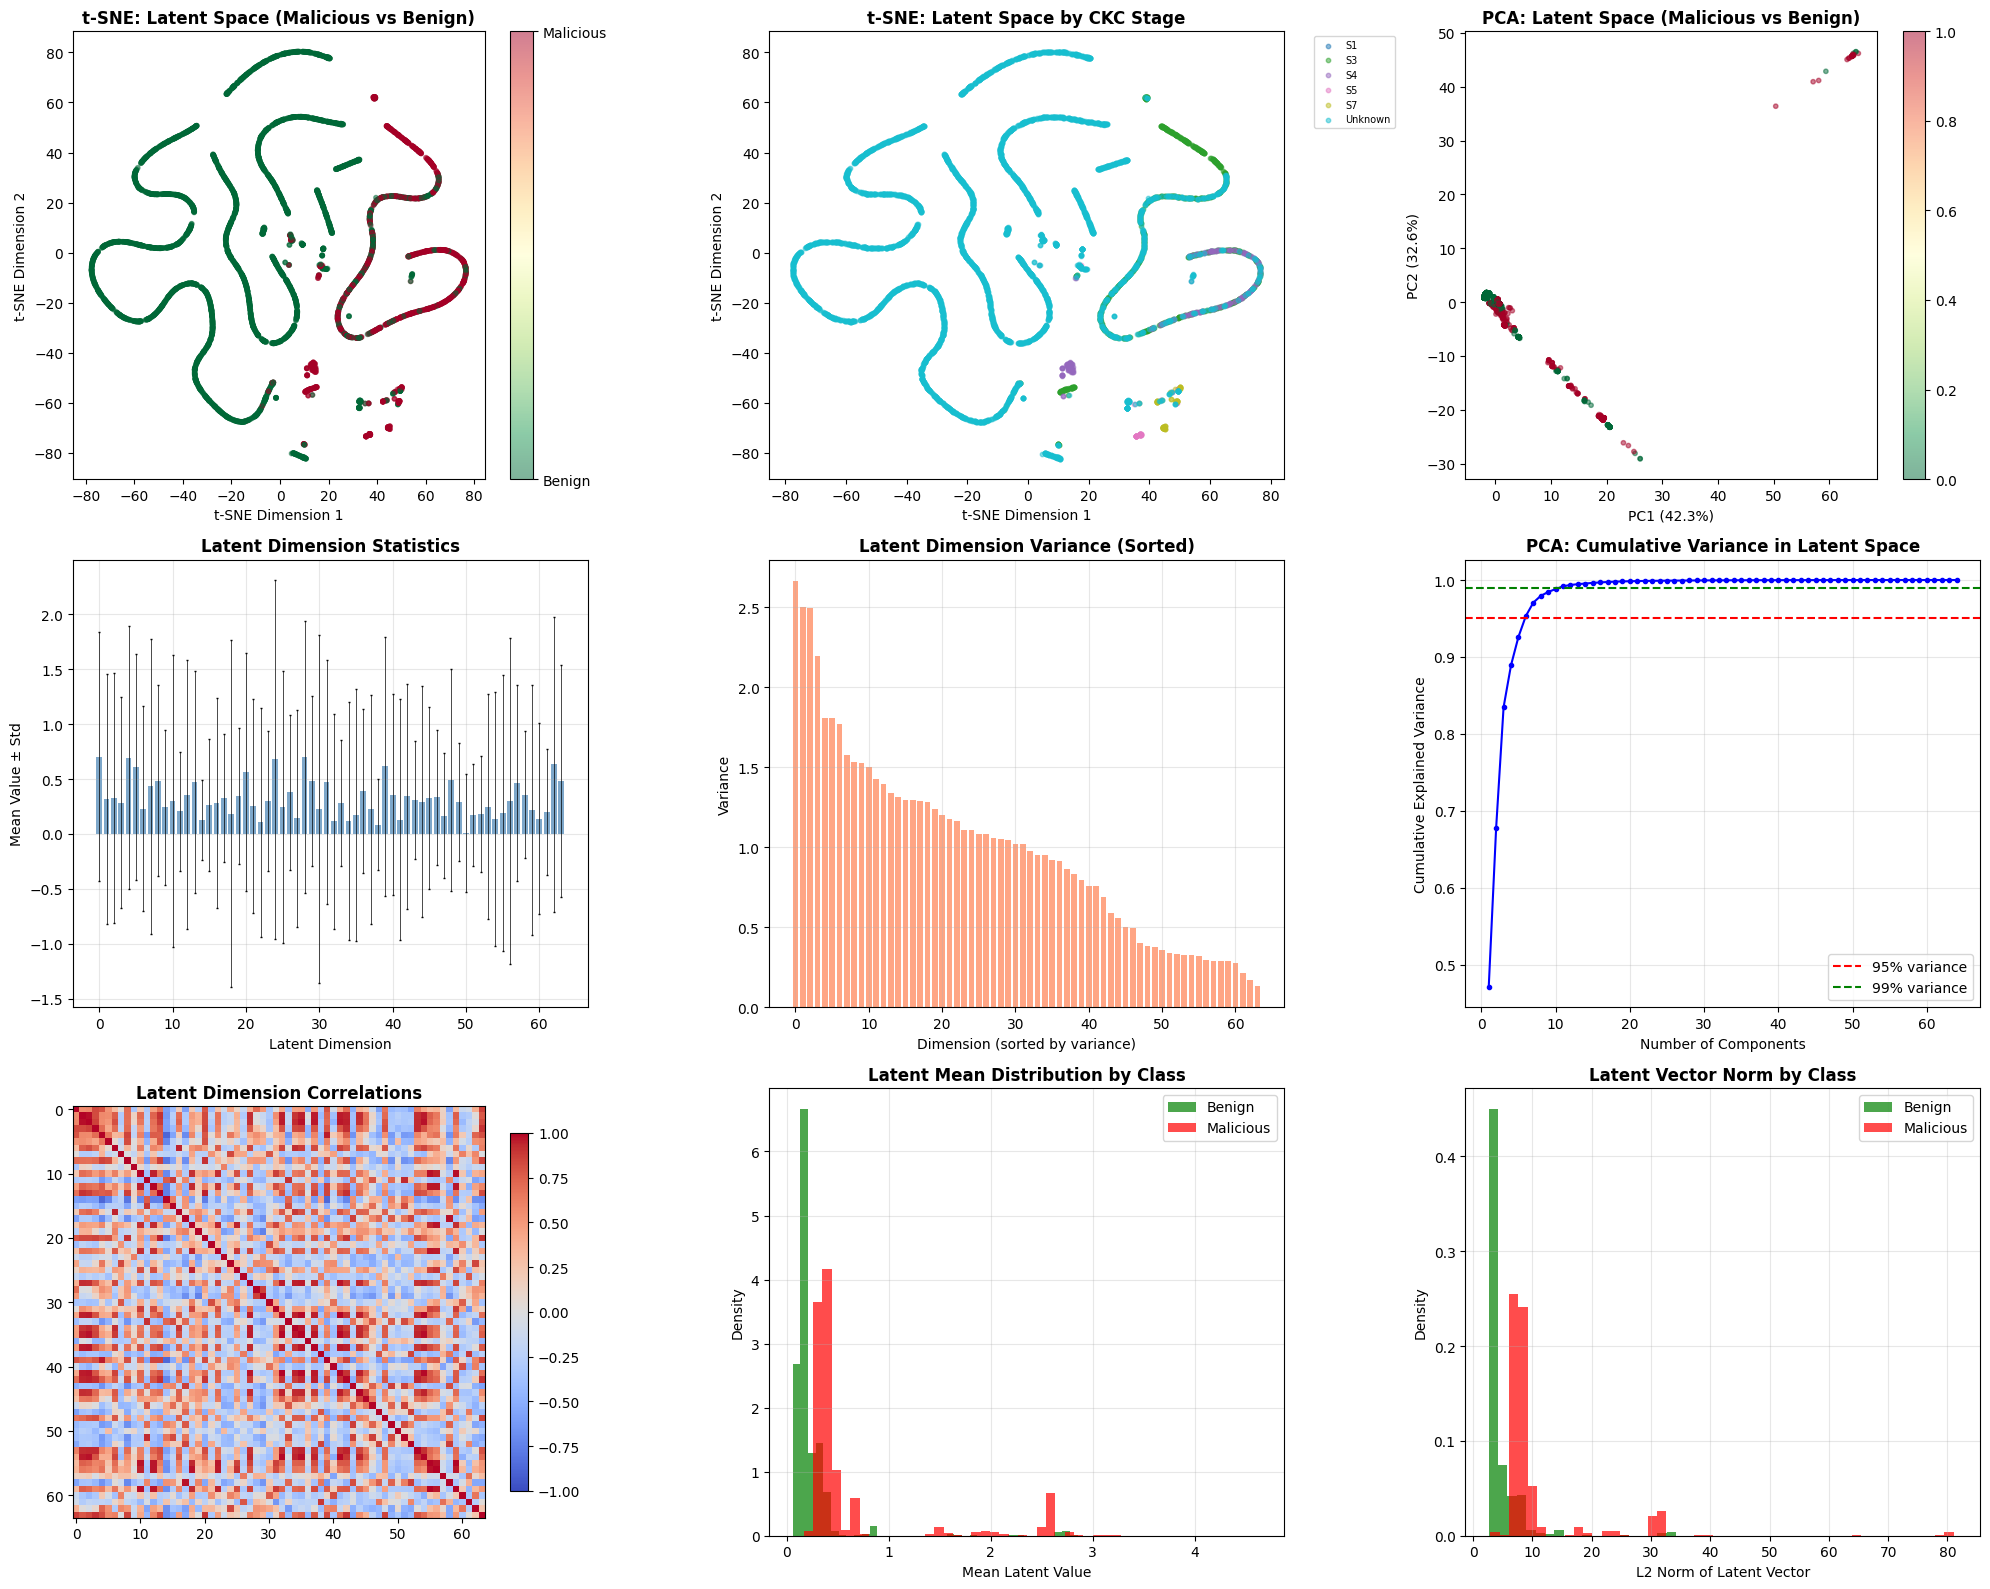

✓ Encoding visualizations saved!


In [40]:
# 14.2 ENCODING VISUALIZATIONS (Latent Space Analysis)

print("=" * 80)
print("14.2 ENCODING VISUALIZATIONS")
print("=" * 80)

fig = plt.figure(figsize=(20, 16))

# Use model_64 for latent space visualization
latent_viz = latent_64

# 1. t-SNE Visualization of Latent Space (by Malicious/Benign)
print("Computing t-SNE (this may take a moment)...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
# Use subset for faster computation
subset_idx = np.random.choice(len(latent_viz), size=min(5000, len(latent_viz)), replace=False)
latent_subset = latent_viz[subset_idx]
labels_subset = y_malicious_nl[subset_idx]
ckc_subset = y_ckc_nl[subset_idx]

tsne_result = tsne.fit_transform(latent_subset)

ax1 = fig.add_subplot(3, 3, 1)
scatter = ax1.scatter(tsne_result[:, 0], tsne_result[:, 1], c=labels_subset, 
                      cmap='RdYlGn_r', alpha=0.5, s=10)
ax1.set_xlabel('t-SNE Dimension 1')
ax1.set_ylabel('t-SNE Dimension 2')
ax1.set_title('t-SNE: Latent Space (Malicious vs Benign)', fontsize=12, fontweight='bold')
cbar = plt.colorbar(scatter, ax=ax1)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(['Benign', 'Malicious'])

# 2. t-SNE by Cyber Kill Chain Stage
ax2 = fig.add_subplot(3, 3, 2)
unique_ckc = np.unique(ckc_subset)
colors_ckc = plt.cm.tab10(np.linspace(0, 1, len(unique_ckc)))
for i, ckc in enumerate(unique_ckc):
    mask = ckc_subset == ckc
    ax2.scatter(tsne_result[mask, 0], tsne_result[mask, 1], c=[colors_ckc[i]], 
                label=ckc[:15], alpha=0.5, s=10)
ax2.set_xlabel('t-SNE Dimension 1')
ax2.set_ylabel('t-SNE Dimension 2')
ax2.set_title('t-SNE: Latent Space by CKC Stage', fontsize=12, fontweight='bold')
ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7)

# 3. PCA Visualization
print("Computing PCA...")
pca = PCA(n_components=2)
pca_result = pca.fit_transform(latent_subset)

ax3 = fig.add_subplot(3, 3, 3)
scatter = ax3.scatter(pca_result[:, 0], pca_result[:, 1], c=labels_subset, 
                      cmap='RdYlGn_r', alpha=0.5, s=10)
ax3.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax3.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax3.set_title('PCA: Latent Space (Malicious vs Benign)', fontsize=12, fontweight='bold')
plt.colorbar(scatter, ax=ax3)

# 4. Latent Dimension Distribution
ax4 = fig.add_subplot(3, 3, 4)
latent_means = latent_viz.mean(axis=0)
latent_stds = latent_viz.std(axis=0)
x_dims = np.arange(len(latent_means))
ax4.bar(x_dims, latent_means, yerr=latent_stds, alpha=0.7, color='steelblue', 
        error_kw={'elinewidth': 0.5, 'capsize': 1})
ax4.set_xlabel('Latent Dimension')
ax4.set_ylabel('Mean Value ± Std')
ax4.set_title('Latent Dimension Statistics', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3)

# 5. Latent Space Variance per Dimension
ax5 = fig.add_subplot(3, 3, 5)
latent_var = np.var(latent_viz, axis=0)
ax5.bar(np.arange(len(latent_var)), np.sort(latent_var)[::-1], color='coral', alpha=0.7)
ax5.set_xlabel('Dimension (sorted by variance)')
ax5.set_ylabel('Variance')
ax5.set_title('Latent Dimension Variance (Sorted)', fontsize=12, fontweight='bold')
ax5.grid(True, alpha=0.3)

# 6. PCA Explained Variance (full latent space)
ax6 = fig.add_subplot(3, 3, 6)
pca_full = PCA()
pca_full.fit(latent_viz)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
ax6.plot(range(1, len(cumvar)+1), cumvar, 'b-o', markersize=3)
ax6.axhline(y=0.95, color='r', linestyle='--', label='95% variance')
ax6.axhline(y=0.99, color='g', linestyle='--', label='99% variance')
ax6.set_xlabel('Number of Components')
ax6.set_ylabel('Cumulative Explained Variance')
ax6.set_title('PCA: Cumulative Variance in Latent Space', fontsize=12, fontweight='bold')
ax6.legend()
ax6.grid(True, alpha=0.3)

# 7. Latent Space Correlation Matrix
ax7 = fig.add_subplot(3, 3, 7)
latent_corr = np.corrcoef(latent_viz.T)
im = ax7.imshow(latent_corr, cmap='coolwarm', vmin=-1, vmax=1)
ax7.set_title('Latent Dimension Correlations', fontsize=12, fontweight='bold')
plt.colorbar(im, ax=ax7, shrink=0.8)

# 8. Benign vs Malicious Latent Distribution
ax8 = fig.add_subplot(3, 3, 8)
benign_latent = latent_viz[y_malicious_nl == 0]
malicious_latent = latent_viz[y_malicious_nl == 1]
ax8.hist(benign_latent.mean(axis=1), bins=50, alpha=0.7, label='Benign', color='green', density=True)
ax8.hist(malicious_latent.mean(axis=1), bins=50, alpha=0.7, label='Malicious', color='red', density=True)
ax8.set_xlabel('Mean Latent Value')
ax8.set_ylabel('Density')
ax8.set_title('Latent Mean Distribution by Class', fontsize=12, fontweight='bold')
ax8.legend()
ax8.grid(True, alpha=0.3)

# 9. Latent Norm Distribution
ax9 = fig.add_subplot(3, 3, 9)
benign_norms = np.linalg.norm(benign_latent, axis=1)
malicious_norms = np.linalg.norm(malicious_latent, axis=1)
ax9.hist(benign_norms, bins=50, alpha=0.7, label='Benign', color='green', density=True)
ax9.hist(malicious_norms, bins=50, alpha=0.7, label='Malicious', color='red', density=True)
ax9.set_xlabel('L2 Norm of Latent Vector')
ax9.set_ylabel('Density')
ax9.set_title('Latent Vector Norm by Class', fontsize=12, fontweight='bold')
ax9.legend()
ax9.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/viz_02_encoding.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Encoding visualizations saved!")

14.3 DECODING VISUALIZATIONS


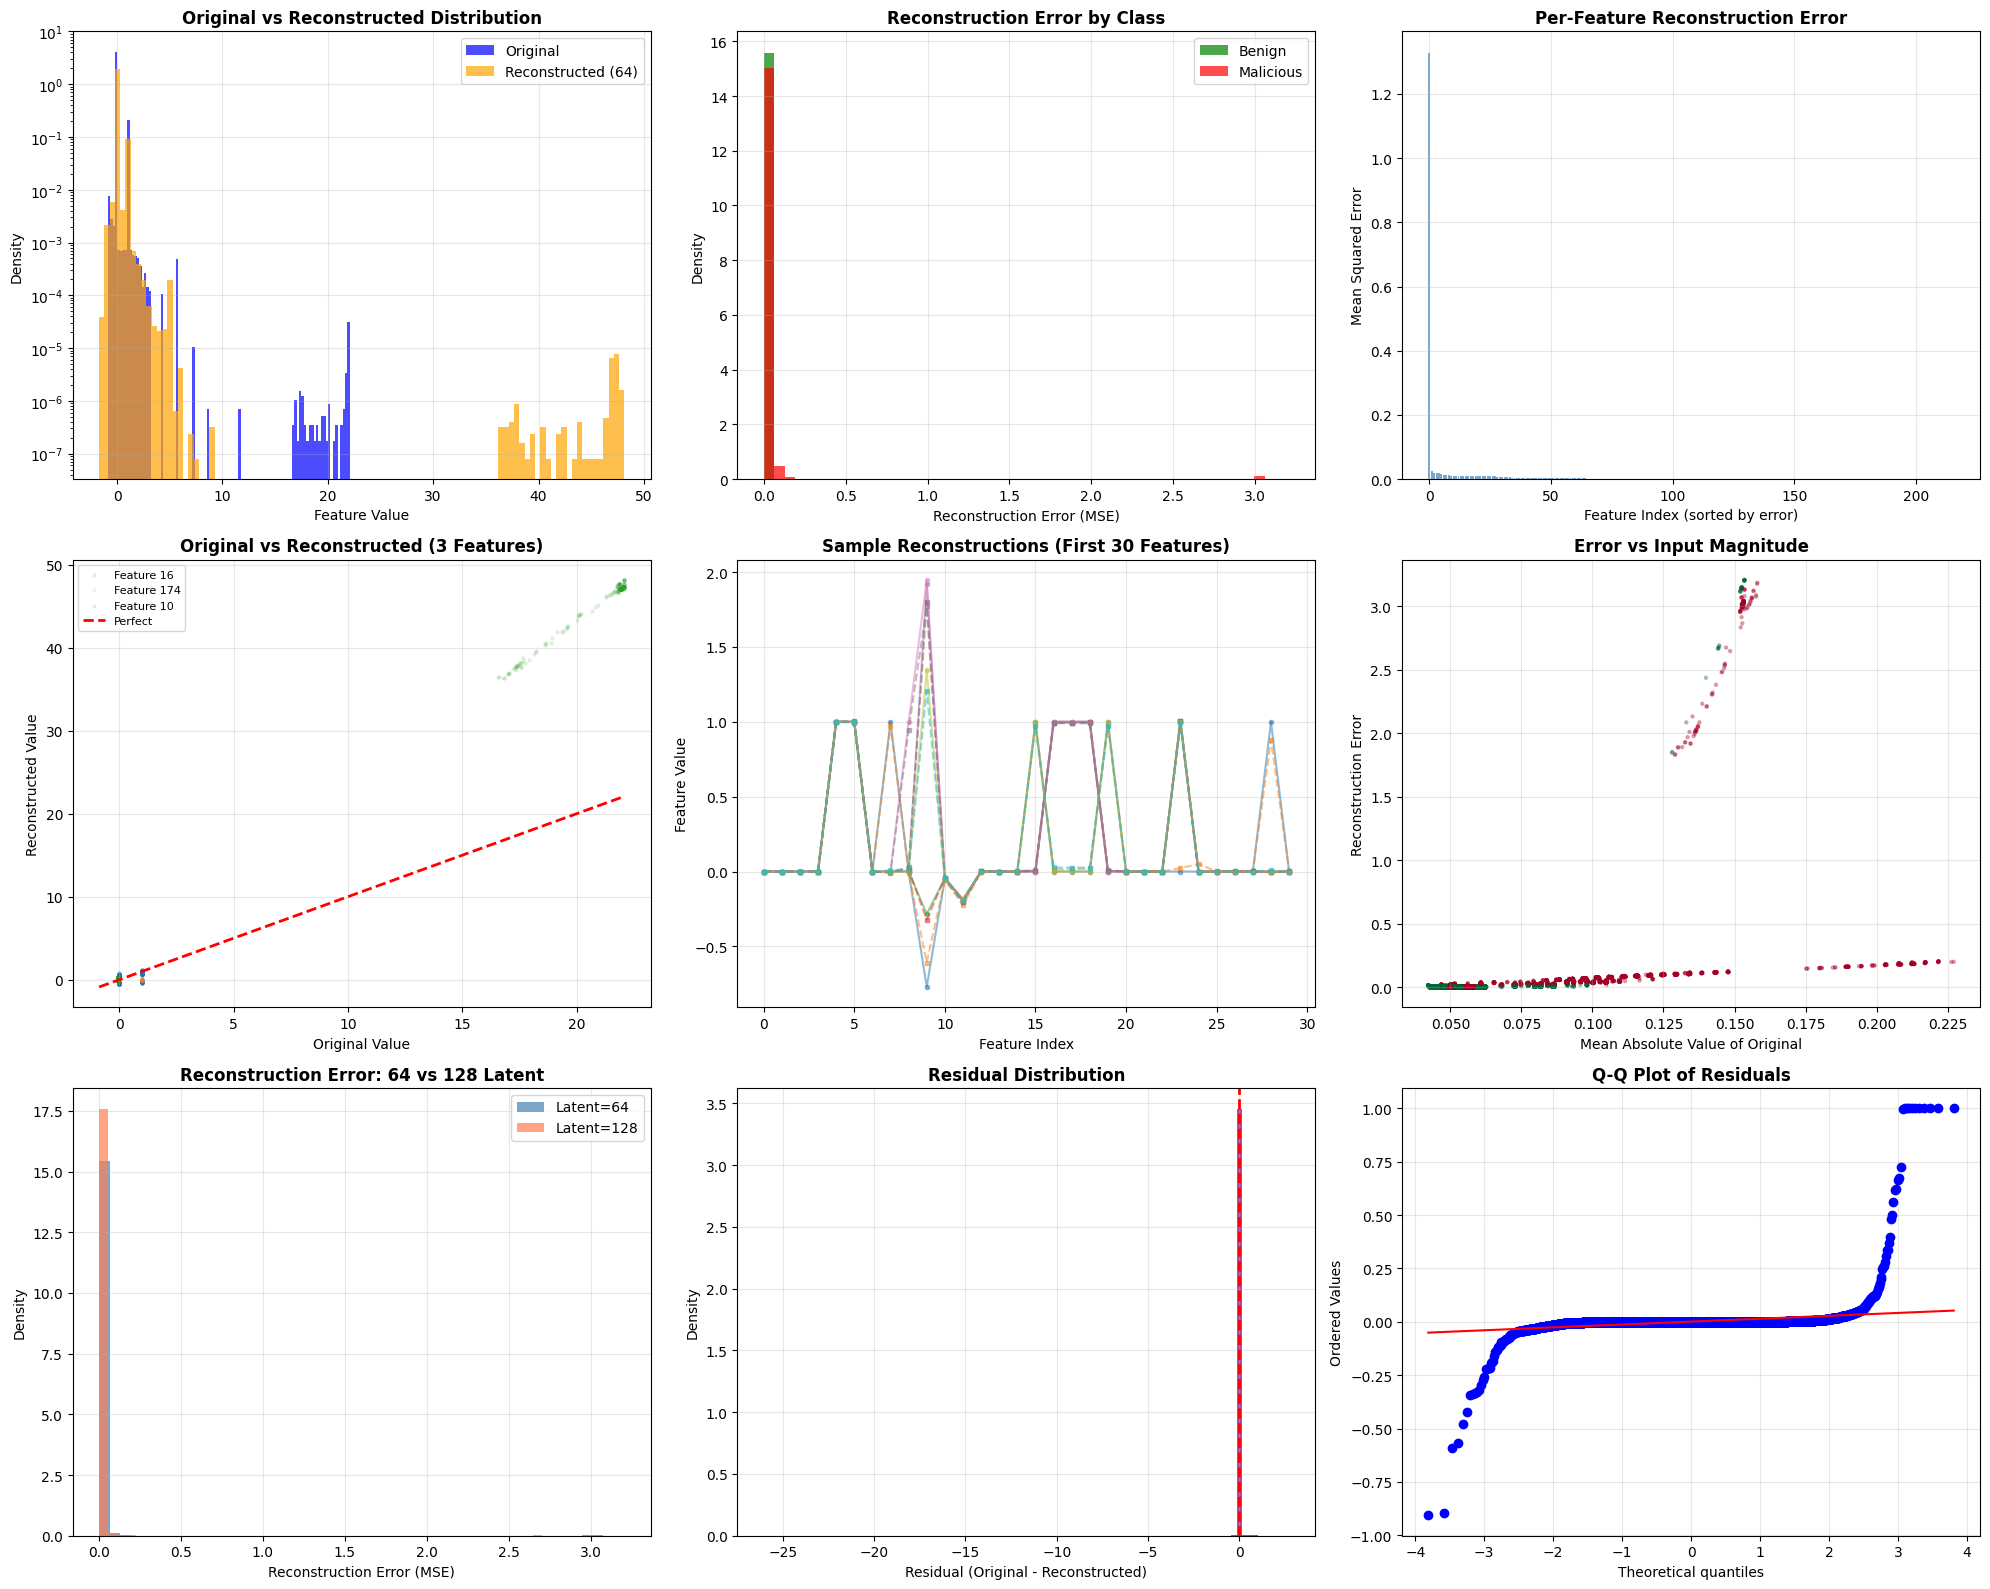

✓ Decoding visualizations saved!


In [41]:
# 14.3 DECODING VISUALIZATIONS (Reconstruction Analysis)

print("=" * 80)
print("14.3 DECODING VISUALIZATIONS")
print("=" * 80)

fig = plt.figure(figsize=(20, 16))

# 1. Original vs Reconstructed Distribution
ax1 = fig.add_subplot(3, 3, 1)
ax1.hist(X_nl.flatten(), bins=100, alpha=0.7, label='Original', color='blue', density=True)
ax1.hist(X_recon_64.flatten(), bins=100, alpha=0.7, label='Reconstructed (64)', color='orange', density=True)
ax1.set_xlabel('Feature Value')
ax1.set_ylabel('Density')
ax1.set_title('Original vs Reconstructed Distribution', fontsize=12, fontweight='bold')
ax1.legend()
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)

# 2. Reconstruction Error Distribution by Class
ax2 = fig.add_subplot(3, 3, 2)
benign_errors = recon_error_64[y_malicious_nl == 0]
malicious_errors = recon_error_64[y_malicious_nl == 1]
ax2.hist(benign_errors, bins=50, alpha=0.7, label='Benign', color='green', density=True)
ax2.hist(malicious_errors, bins=50, alpha=0.7, label='Malicious', color='red', density=True)
ax2.set_xlabel('Reconstruction Error (MSE)')
ax2.set_ylabel('Density')
ax2.set_title('Reconstruction Error by Class', fontsize=12, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Feature-wise Reconstruction Error
ax3 = fig.add_subplot(3, 3, 3)
feature_errors = np.mean((X_nl - X_recon_64) ** 2, axis=0)
ax3.bar(np.arange(len(feature_errors)), np.sort(feature_errors)[::-1], color='steelblue', alpha=0.7)
ax3.set_xlabel('Feature Index (sorted by error)')
ax3.set_ylabel('Mean Squared Error')
ax3.set_title('Per-Feature Reconstruction Error', fontsize=12, fontweight='bold')
ax3.grid(True, alpha=0.3)

# 4. Scatter Plot: Original vs Reconstructed (random features)
ax4 = fig.add_subplot(3, 3, 4)
random_features = np.random.choice(X_nl.shape[1], size=3, replace=False)
for i, feat_idx in enumerate(random_features):
    ax4.scatter(X_nl[:, feat_idx], X_recon_64[:, feat_idx], alpha=0.1, s=5, label=f'Feature {feat_idx}')
ax4.plot([X_nl.min(), X_nl.max()], [X_nl.min(), X_nl.max()], 'r--', linewidth=2, label='Perfect')
ax4.set_xlabel('Original Value')
ax4.set_ylabel('Reconstructed Value')
ax4.set_title('Original vs Reconstructed (3 Features)', fontsize=12, fontweight='bold')
ax4.legend(fontsize=8)
ax4.grid(True, alpha=0.3)

# 5. Sample Reconstruction Comparison (multiple samples)
ax5 = fig.add_subplot(3, 3, 5)
n_samples_show = 5
sample_indices = np.random.choice(len(X_nl), size=n_samples_show, replace=False)
for i, idx in enumerate(sample_indices):
    ax5.plot(X_nl[idx, :30], 'o-', alpha=0.5, markersize=3, label=f'Orig {i+1}')
    ax5.plot(X_recon_64[idx, :30], 's--', alpha=0.5, markersize=3)
ax5.set_xlabel('Feature Index')
ax5.set_ylabel('Feature Value')
ax5.set_title('Sample Reconstructions (First 30 Features)', fontsize=12, fontweight='bold')
ax5.grid(True, alpha=0.3)

# 6. Reconstruction Error vs Original Magnitude
ax6 = fig.add_subplot(3, 3, 6)
sample_magnitudes = np.mean(np.abs(X_nl), axis=1)
ax6.scatter(sample_magnitudes, recon_error_64, alpha=0.3, s=5, c=y_malicious_nl, cmap='RdYlGn_r')
ax6.set_xlabel('Mean Absolute Value of Original')
ax6.set_ylabel('Reconstruction Error')
ax6.set_title('Error vs Input Magnitude', fontsize=12, fontweight='bold')
ax6.grid(True, alpha=0.3)

# 7. 64 vs 128 Reconstruction Comparison
ax7 = fig.add_subplot(3, 3, 7)
ax7.hist(recon_error_64, bins=50, alpha=0.7, label='Latent=64', color='steelblue', density=True)
ax7.hist(recon_error_128, bins=50, alpha=0.7, label='Latent=128', color='coral', density=True)
ax7.set_xlabel('Reconstruction Error (MSE)')
ax7.set_ylabel('Density')
ax7.set_title('Reconstruction Error: 64 vs 128 Latent', fontsize=12, fontweight='bold')
ax7.legend()
ax7.grid(True, alpha=0.3)

# 8. Residual Analysis (Error Distribution)
ax8 = fig.add_subplot(3, 3, 8)
residuals = (X_nl - X_recon_64).flatten()
ax8.hist(residuals, bins=100, color='purple', alpha=0.7, density=True)
ax8.axvline(x=0, color='red', linestyle='--', linewidth=2)
ax8.set_xlabel('Residual (Original - Reconstructed)')
ax8.set_ylabel('Density')
ax8.set_title('Residual Distribution', fontsize=12, fontweight='bold')
ax8.grid(True, alpha=0.3)

# 9. QQ Plot for Residuals
ax9 = fig.add_subplot(3, 3, 9)
from scipy import stats
residuals_sample = np.random.choice(residuals, size=10000, replace=False)
stats.probplot(residuals_sample, dist="norm", plot=ax9)
ax9.set_title('Q-Q Plot of Residuals', fontsize=12, fontweight='bold')
ax9.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/viz_03_decoding.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Decoding visualizations saved!")

14.4 CLASSIFICATION VISUALIZATIONS


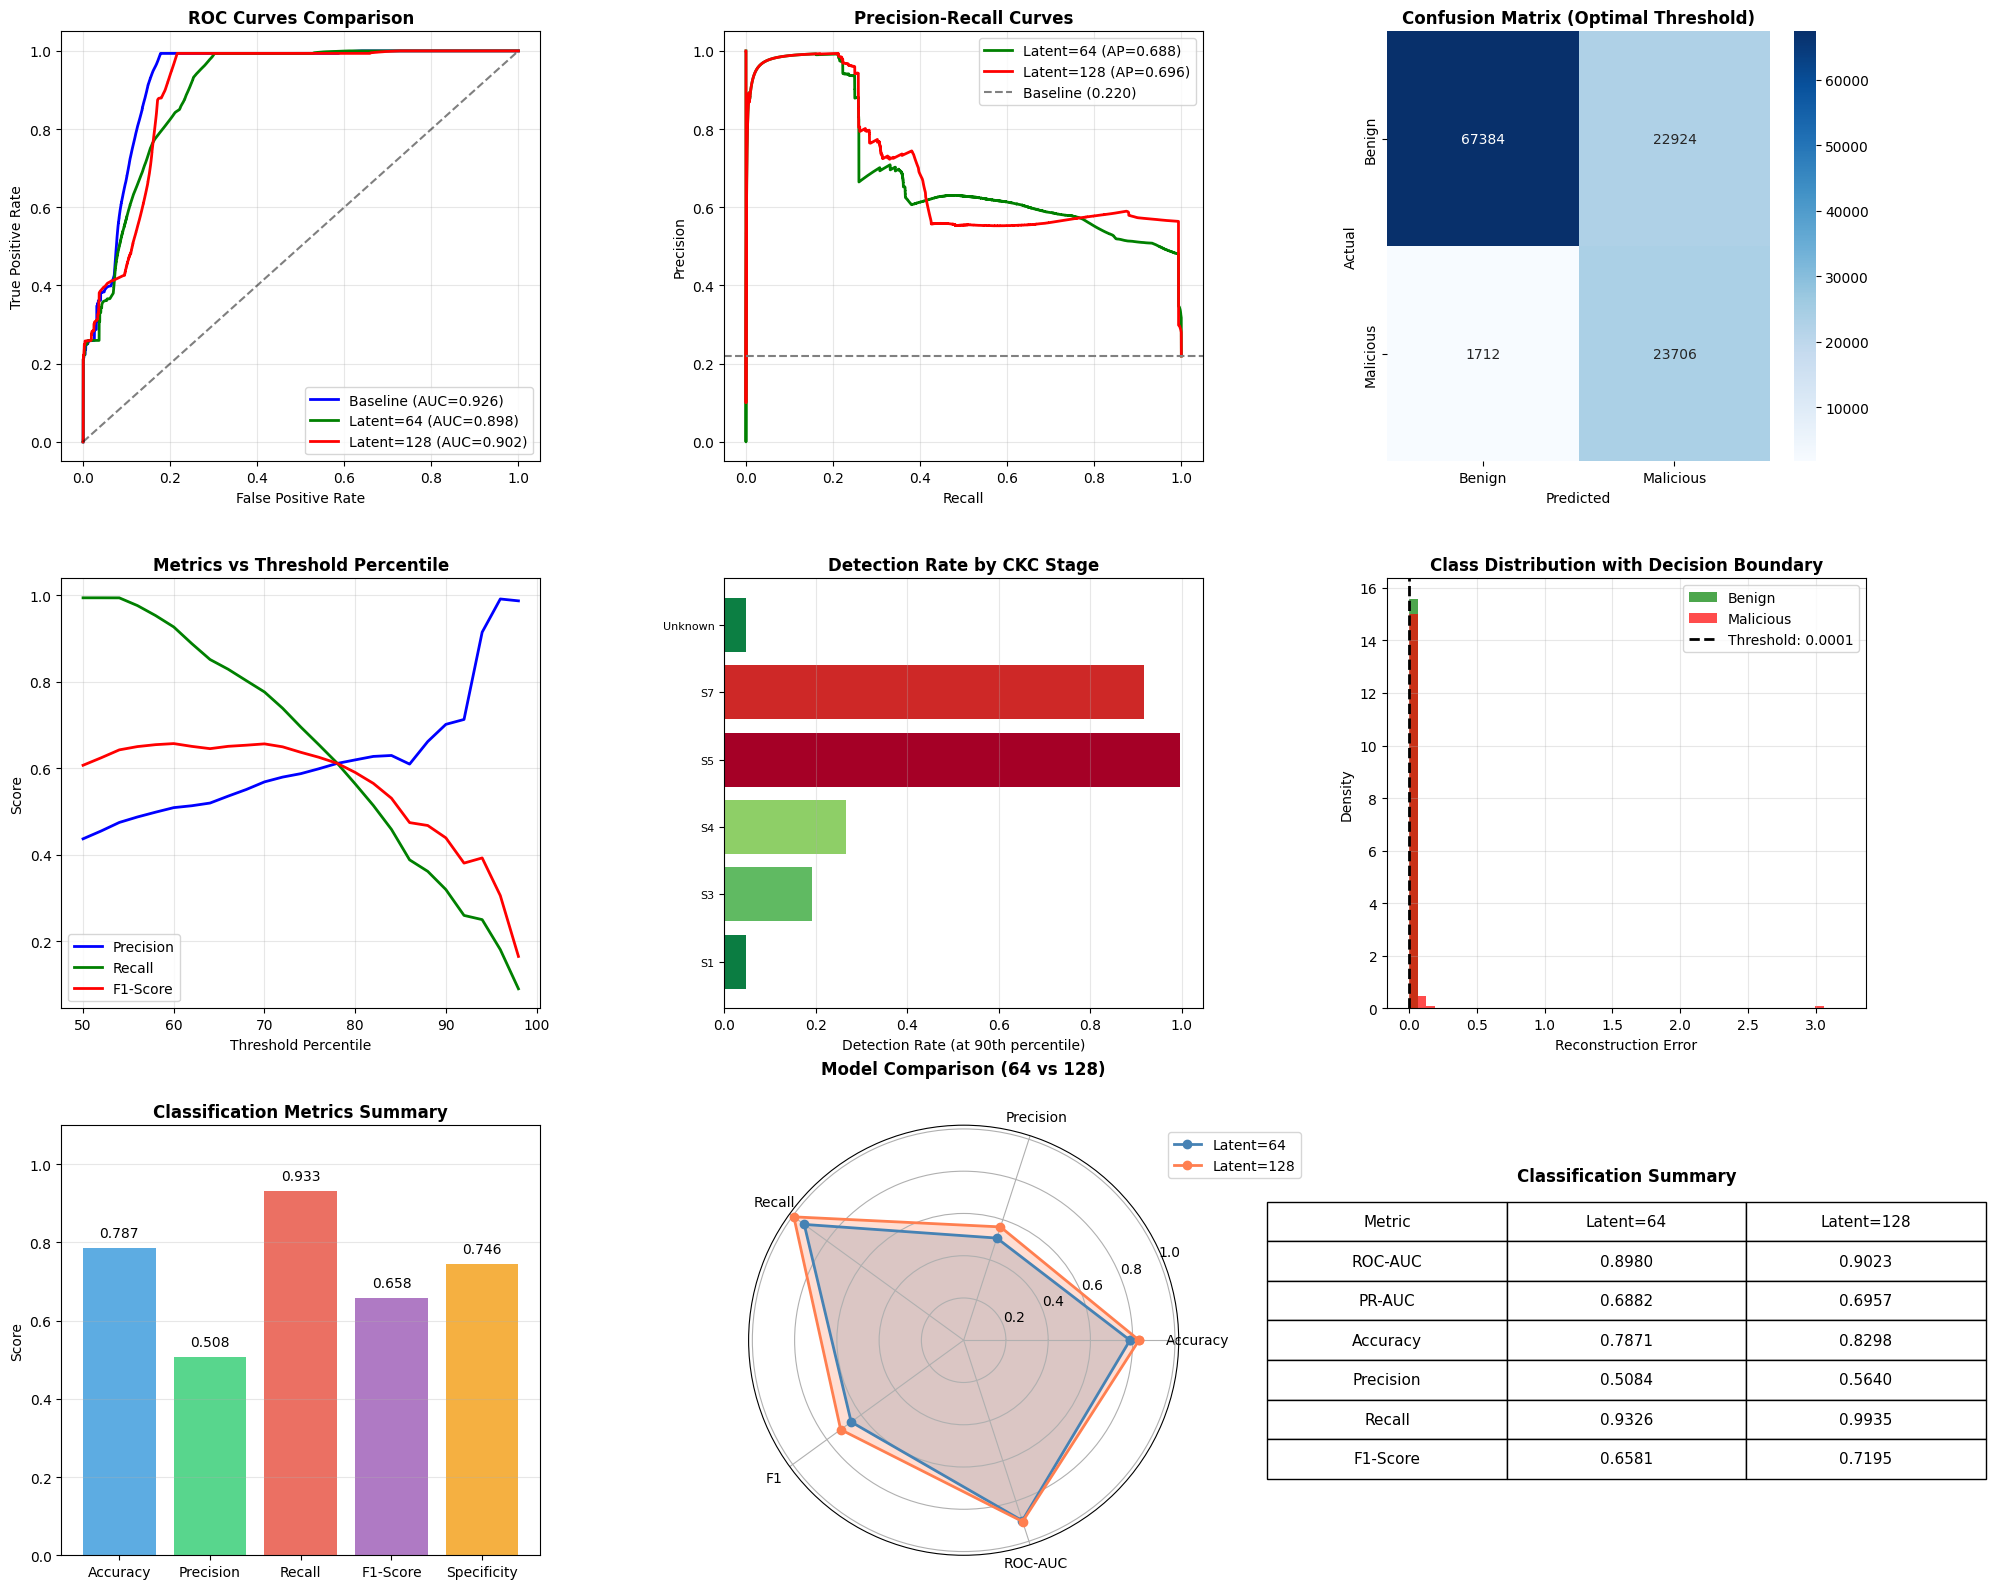

✓ Classification visualizations saved!


In [42]:
# 14.4 CLASSIFICATION VISUALIZATIONS (Anomaly Detection)

print("=" * 80)
print("14.4 CLASSIFICATION VISUALIZATIONS")
print("=" * 80)

fig = plt.figure(figsize=(20, 16))

# 1. ROC Curves for All Models
ax1 = fig.add_subplot(3, 3, 1)
# Baseline
fpr_base, tpr_base, _ = roc_curve(y_malicious_nl, baseline_errors)
ax1.plot(fpr_base, tpr_base, 'b-', linewidth=2, label=f'Baseline (AUC={roc_auc_score(y_malicious_nl, baseline_errors):.3f})')
# Model 64
fpr_64, tpr_64, _ = roc_curve(y_malicious_nl, recon_error_64)
ax1.plot(fpr_64, tpr_64, 'g-', linewidth=2, label=f'Latent=64 (AUC={roc_auc_score(y_malicious_nl, recon_error_64):.3f})')
# Model 128
fpr_128, tpr_128, _ = roc_curve(y_malicious_nl, recon_error_128)
ax1.plot(fpr_128, tpr_128, 'r-', linewidth=2, label=f'Latent=128 (AUC={roc_auc_score(y_malicious_nl, recon_error_128):.3f})')
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curves Comparison', fontsize=12, fontweight='bold')
ax1.legend(loc='lower right')
ax1.grid(True, alpha=0.3)

# 2. Precision-Recall Curves
ax2 = fig.add_subplot(3, 3, 2)
from sklearn.metrics import precision_recall_curve, average_precision_score
prec_64, rec_64, _ = precision_recall_curve(y_malicious_nl, recon_error_64)
prec_128, rec_128, _ = precision_recall_curve(y_malicious_nl, recon_error_128)
ax2.plot(rec_64, prec_64, 'g-', linewidth=2, label=f'Latent=64 (AP={average_precision_score(y_malicious_nl, recon_error_64):.3f})')
ax2.plot(rec_128, prec_128, 'r-', linewidth=2, label=f'Latent=128 (AP={average_precision_score(y_malicious_nl, recon_error_128):.3f})')
ax2.axhline(y=y_malicious_nl.mean(), color='gray', linestyle='--', label=f'Baseline ({y_malicious_nl.mean():.3f})')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curves', fontsize=12, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Confusion Matrix (Best Model at Optimal Threshold)
ax3 = fig.add_subplot(3, 3, 3)
optimal_thresh = find_optimal_threshold(y_malicious_nl, recon_error_64)
preds_optimal = (recon_error_64 > optimal_thresh).astype(int)
cm = confusion_matrix(y_malicious_nl, preds_optimal)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax3,
            xticklabels=['Benign', 'Malicious'], yticklabels=['Benign', 'Malicious'])
ax3.set_xlabel('Predicted')
ax3.set_ylabel('Actual')
ax3.set_title(f'Confusion Matrix (Optimal Threshold)', fontsize=12, fontweight='bold')

# 4. Threshold vs Metrics
ax4 = fig.add_subplot(3, 3, 4)
thresholds = np.percentile(recon_error_64, np.arange(50, 100, 2))
precisions_t, recalls_t, f1s_t = [], [], []
for t in thresholds:
    preds = (recon_error_64 > t).astype(int)
    precisions_t.append(precision_score(y_malicious_nl, preds, zero_division=0))
    recalls_t.append(recall_score(y_malicious_nl, preds, zero_division=0))
    f1s_t.append(f1_score(y_malicious_nl, preds, zero_division=0))
ax4.plot(np.arange(50, 100, 2), precisions_t, 'b-', label='Precision', linewidth=2)
ax4.plot(np.arange(50, 100, 2), recalls_t, 'g-', label='Recall', linewidth=2)
ax4.plot(np.arange(50, 100, 2), f1s_t, 'r-', label='F1-Score', linewidth=2)
ax4.set_xlabel('Threshold Percentile')
ax4.set_ylabel('Score')
ax4.set_title('Metrics vs Threshold Percentile', fontsize=12, fontweight='bold')
ax4.legend()
ax4.grid(True, alpha=0.3)

# 5. Detection Rate by Cyber Kill Chain Stage
ax5 = fig.add_subplot(3, 3, 5)
detection_by_ckc = {}
for ckc in np.unique(y_ckc_nl):
    mask = y_ckc_nl == ckc
    if mask.sum() > 0:
        # Detection rate = how many flagged as anomaly (high recon error)
        thresh_90 = np.percentile(recon_error_64, 90)
        detection_rate = (recon_error_64[mask] > thresh_90).mean()
        detection_by_ckc[ckc] = detection_rate

ckc_names = list(detection_by_ckc.keys())
ckc_rates = list(detection_by_ckc.values())
bars = ax5.barh(range(len(ckc_names)), ckc_rates, color=plt.cm.RdYlGn_r(np.array(ckc_rates)))
ax5.set_yticks(range(len(ckc_names)))
ax5.set_yticklabels([n[:20] for n in ckc_names], fontsize=8)
ax5.set_xlabel('Detection Rate (at 90th percentile)')
ax5.set_title('Detection Rate by CKC Stage', fontsize=12, fontweight='bold')
ax5.grid(True, alpha=0.3, axis='x')

# 6. Error Distribution with Decision Boundary
ax6 = fig.add_subplot(3, 3, 6)
ax6.hist(benign_errors, bins=50, alpha=0.7, label='Benign', color='green', density=True)
ax6.hist(malicious_errors, bins=50, alpha=0.7, label='Malicious', color='red', density=True)
ax6.axvline(x=optimal_thresh, color='black', linestyle='--', linewidth=2, label=f'Threshold: {optimal_thresh:.4f}')
ax6.set_xlabel('Reconstruction Error')
ax6.set_ylabel('Density')
ax6.set_title('Class Distribution with Decision Boundary', fontsize=12, fontweight='bold')
ax6.legend()
ax6.grid(True, alpha=0.3)

# 7. Metrics Comparison Bar Chart
ax7 = fig.add_subplot(3, 3, 7)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Specificity']
cm_vals = confusion_matrix(y_malicious_nl, preds_optimal).ravel()
tn, fp, fn, tp = cm_vals
metrics_vals = [
    (tp + tn) / (tp + tn + fp + fn),  # Accuracy
    tp / (tp + fp) if (tp + fp) > 0 else 0,  # Precision
    tp / (tp + fn) if (tp + fn) > 0 else 0,  # Recall
    2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0,  # F1
    tn / (tn + fp) if (tn + fp) > 0 else 0  # Specificity
]
colors_metrics = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6', '#f39c12']
bars = ax7.bar(metrics_names, metrics_vals, color=colors_metrics, alpha=0.8)
ax7.set_ylabel('Score')
ax7.set_title('Classification Metrics Summary', fontsize=12, fontweight='bold')
ax7.set_ylim(0, 1.1)
for bar, val in zip(bars, metrics_vals):
    ax7.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{val:.3f}', 
             ha='center', va='bottom', fontsize=10)
ax7.grid(True, alpha=0.3, axis='y')

# 8. Model Comparison Radar Chart
ax8 = fig.add_subplot(3, 3, 8, projection='polar')
categories = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
# Model 64 metrics
preds_64 = (recon_error_64 > find_optimal_threshold(y_malicious_nl, recon_error_64)).astype(int)
cm_64 = confusion_matrix(y_malicious_nl, preds_64).ravel()
tn64, fp64, fn64, tp64 = cm_64
vals_64 = [
    (tp64 + tn64) / len(y_malicious_nl),
    tp64 / (tp64 + fp64) if (tp64 + fp64) > 0 else 0,
    tp64 / (tp64 + fn64) if (tp64 + fn64) > 0 else 0,
    2 * tp64 / (2 * tp64 + fp64 + fn64) if (2 * tp64 + fp64 + fn64) > 0 else 0,
    roc_auc_score(y_malicious_nl, recon_error_64)
]
# Model 128 metrics
preds_128 = (recon_error_128 > find_optimal_threshold(y_malicious_nl, recon_error_128)).astype(int)
cm_128 = confusion_matrix(y_malicious_nl, preds_128).ravel()
tn128, fp128, fn128, tp128 = cm_128
vals_128 = [
    (tp128 + tn128) / len(y_malicious_nl),
    tp128 / (tp128 + fp128) if (tp128 + fp128) > 0 else 0,
    tp128 / (tp128 + fn128) if (tp128 + fn128) > 0 else 0,
    2 * tp128 / (2 * tp128 + fp128 + fn128) if (2 * tp128 + fp128 + fn128) > 0 else 0,
    roc_auc_score(y_malicious_nl, recon_error_128)
]

angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
vals_64 += vals_64[:1]
vals_128 += vals_128[:1]
angles += angles[:1]

ax8.plot(angles, vals_64, 'o-', linewidth=2, label='Latent=64', color='steelblue')
ax8.fill(angles, vals_64, alpha=0.25, color='steelblue')
ax8.plot(angles, vals_128, 'o-', linewidth=2, label='Latent=128', color='coral')
ax8.fill(angles, vals_128, alpha=0.25, color='coral')
ax8.set_xticks(angles[:-1])
ax8.set_xticklabels(categories)
ax8.set_title('Model Comparison (64 vs 128)', fontsize=12, fontweight='bold', y=1.1)
ax8.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))

# 9. Summary Statistics Table
ax9 = fig.add_subplot(3, 3, 9)
ax9.axis('off')
summary_data = [
    ['Metric', 'Latent=64', 'Latent=128'],
    ['ROC-AUC', f'{roc_auc_score(y_malicious_nl, recon_error_64):.4f}', f'{roc_auc_score(y_malicious_nl, recon_error_128):.4f}'],
    ['PR-AUC', f'{average_precision_score(y_malicious_nl, recon_error_64):.4f}', f'{average_precision_score(y_malicious_nl, recon_error_128):.4f}'],
    ['Accuracy', f'{vals_64[0]:.4f}', f'{vals_128[0]:.4f}'],
    ['Precision', f'{vals_64[1]:.4f}', f'{vals_128[1]:.4f}'],
    ['Recall', f'{vals_64[2]:.4f}', f'{vals_128[2]:.4f}'],
    ['F1-Score', f'{vals_64[3]:.4f}', f'{vals_128[3]:.4f}']
]
table = ax9.table(cellText=summary_data[1:], colLabels=summary_data[0], loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.5, 2)
ax9.set_title('Classification Summary', fontsize=12, fontweight='bold', y=0.85)

plt.tight_layout()
plt.savefig('autoencoder_outputs/viz_04_classification.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Classification visualizations saved!")

14.5 AUTOENCODER ARCHITECTURE & TRAINING VISUALIZATIONS


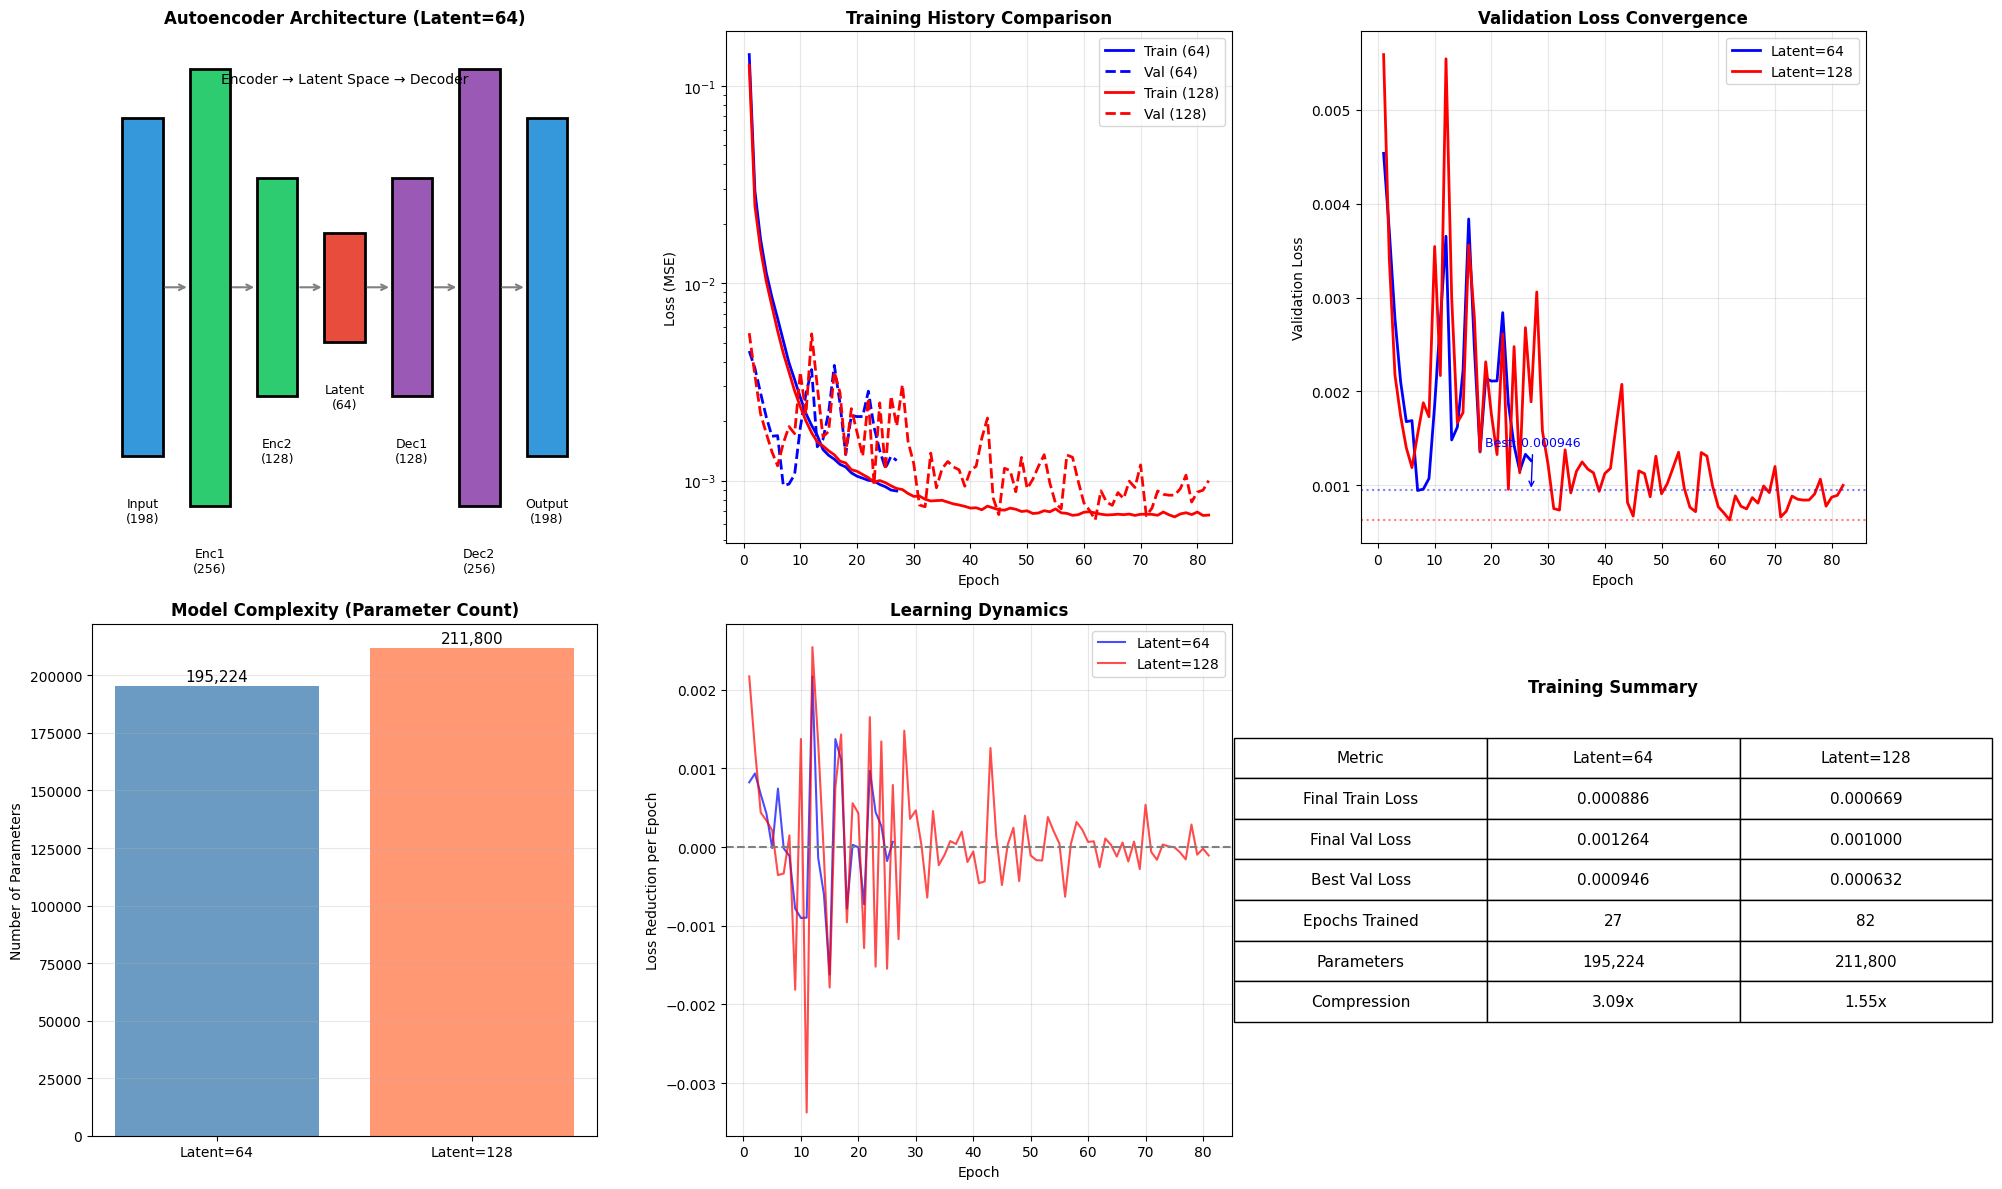

✓ Architecture & training visualizations saved!


In [43]:
# 14.5 AUTOENCODER ARCHITECTURE & TRAINING VISUALIZATIONS

print("=" * 80)
print("14.5 AUTOENCODER ARCHITECTURE & TRAINING VISUALIZATIONS")
print("=" * 80)

fig = plt.figure(figsize=(20, 12))

# 1. Model Architecture Diagram
ax1 = fig.add_subplot(2, 3, 1)
ax1.axis('off')

# Draw encoder-decoder architecture
layers_64 = [198, 256, 128, 64, 128, 256, 198]
layer_names = ['Input\n(198)', 'Enc1\n(256)', 'Enc2\n(128)', 'Latent\n(64)', 'Dec1\n(128)', 'Dec2\n(256)', 'Output\n(198)']
colors_arch = ['#3498db', '#2ecc71', '#2ecc71', '#e74c3c', '#9b59b6', '#9b59b6', '#3498db']

x_positions = np.linspace(0.1, 0.9, len(layers_64))
for i, (size, name, color) in enumerate(zip(layers_64, layer_names, colors_arch)):
    height = size / 300
    rect = plt.Rectangle((x_positions[i] - 0.04, 0.5 - height/2), 0.08, height, 
                         facecolor=color, edgecolor='black', linewidth=2)
    ax1.add_patch(rect)
    ax1.text(x_positions[i], 0.5 - height/2 - 0.08, name, ha='center', va='top', fontsize=9)
    if i < len(layers_64) - 1:
        ax1.annotate('', xy=(x_positions[i+1] - 0.04, 0.5), 
                     xytext=(x_positions[i] + 0.04, 0.5),
                     arrowprops=dict(arrowstyle='->', color='gray', lw=1.5))

ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.set_title('Autoencoder Architecture (Latent=64)', fontsize=12, fontweight='bold')
ax1.text(0.5, 0.9, 'Encoder → Latent Space → Decoder', ha='center', fontsize=10)

# 2. Training Loss Comparison (64 vs 128)
ax2 = fig.add_subplot(2, 3, 2)
epochs_64 = range(1, len(history_64['train_loss']) + 1)
epochs_128 = range(1, len(history_128['train_loss']) + 1)
ax2.plot(epochs_64, history_64['train_loss'], 'b-', label='Train (64)', linewidth=2)
ax2.plot(epochs_64, history_64['val_loss'], 'b--', label='Val (64)', linewidth=2)
ax2.plot(epochs_128, history_128['train_loss'], 'r-', label='Train (128)', linewidth=2)
ax2.plot(epochs_128, history_128['val_loss'], 'r--', label='Val (128)', linewidth=2)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (MSE)')
ax2.set_title('Training History Comparison', fontsize=12, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_yscale('log')

# 3. Validation Loss Convergence
ax3 = fig.add_subplot(2, 3, 3)
ax3.plot(epochs_64, history_64['val_loss'], 'b-', linewidth=2, label='Latent=64')
ax3.plot(epochs_128, history_128['val_loss'], 'r-', linewidth=2, label='Latent=128')
ax3.axhline(y=min(history_64['val_loss']), color='blue', linestyle=':', alpha=0.5)
ax3.axhline(y=min(history_128['val_loss']), color='red', linestyle=':', alpha=0.5)
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Validation Loss')
ax3.set_title('Validation Loss Convergence', fontsize=12, fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)
ax3.annotate(f'Best: {min(history_64["val_loss"]):.6f}', 
             xy=(len(history_64['val_loss']), min(history_64['val_loss'])),
             xytext=(len(history_64['val_loss'])*0.7, min(history_64['val_loss'])*1.5),
             arrowprops=dict(arrowstyle='->', color='blue'), color='blue', fontsize=9)

# 4. Parameter Count Comparison
ax4 = fig.add_subplot(2, 3, 4)
# Calculate parameters
def count_params(model):
    return sum(p.numel() for p in model.parameters())

params_64 = count_params(model_64)
params_128 = count_params(model_128)

bars = ax4.bar(['Latent=64', 'Latent=128'], [params_64, params_128], 
               color=['steelblue', 'coral'], alpha=0.8)
ax4.set_ylabel('Number of Parameters')
ax4.set_title('Model Complexity (Parameter Count)', fontsize=12, fontweight='bold')
for bar, val in zip(bars, [params_64, params_128]):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000, 
             f'{val:,}', ha='center', va='bottom', fontsize=11)
ax4.grid(True, alpha=0.3, axis='y')

# 5. Learning Dynamics (Loss Reduction Rate)
ax5 = fig.add_subplot(2, 3, 5)
loss_reduction_64 = -np.diff(history_64['val_loss'])
loss_reduction_128 = -np.diff(history_128['val_loss'])
ax5.plot(range(1, len(loss_reduction_64)+1), loss_reduction_64, 'b-', alpha=0.7, label='Latent=64')
ax5.plot(range(1, len(loss_reduction_128)+1), loss_reduction_128, 'r-', alpha=0.7, label='Latent=128')
ax5.axhline(y=0, color='gray', linestyle='--')
ax5.set_xlabel('Epoch')
ax5.set_ylabel('Loss Reduction per Epoch')
ax5.set_title('Learning Dynamics', fontsize=12, fontweight='bold')
ax5.legend()
ax5.grid(True, alpha=0.3)

# 6. Final Loss Summary
ax6 = fig.add_subplot(2, 3, 6)
ax6.axis('off')
summary = [
    ['Metric', 'Latent=64', 'Latent=128'],
    ['Final Train Loss', f'{history_64["train_loss"][-1]:.6f}', f'{history_128["train_loss"][-1]:.6f}'],
    ['Final Val Loss', f'{history_64["val_loss"][-1]:.6f}', f'{history_128["val_loss"][-1]:.6f}'],
    ['Best Val Loss', f'{min(history_64["val_loss"]):.6f}', f'{min(history_128["val_loss"]):.6f}'],
    ['Epochs Trained', str(len(history_64['train_loss'])), str(len(history_128['train_loss']))],
    ['Parameters', f'{params_64:,}', f'{params_128:,}'],
    ['Compression', f'{198/64:.2f}x', f'{198/128:.2f}x']
]
table = ax6.table(cellText=summary[1:], colLabels=summary[0], loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.5, 2)
ax6.set_title('Training Summary', fontsize=12, fontweight='bold', y=0.85)

plt.tight_layout()
plt.savefig('autoencoder_outputs/viz_05_architecture_training.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Architecture & training visualizations saved!")

14.6 COMPREHENSIVE SUMMARY DASHBOARD


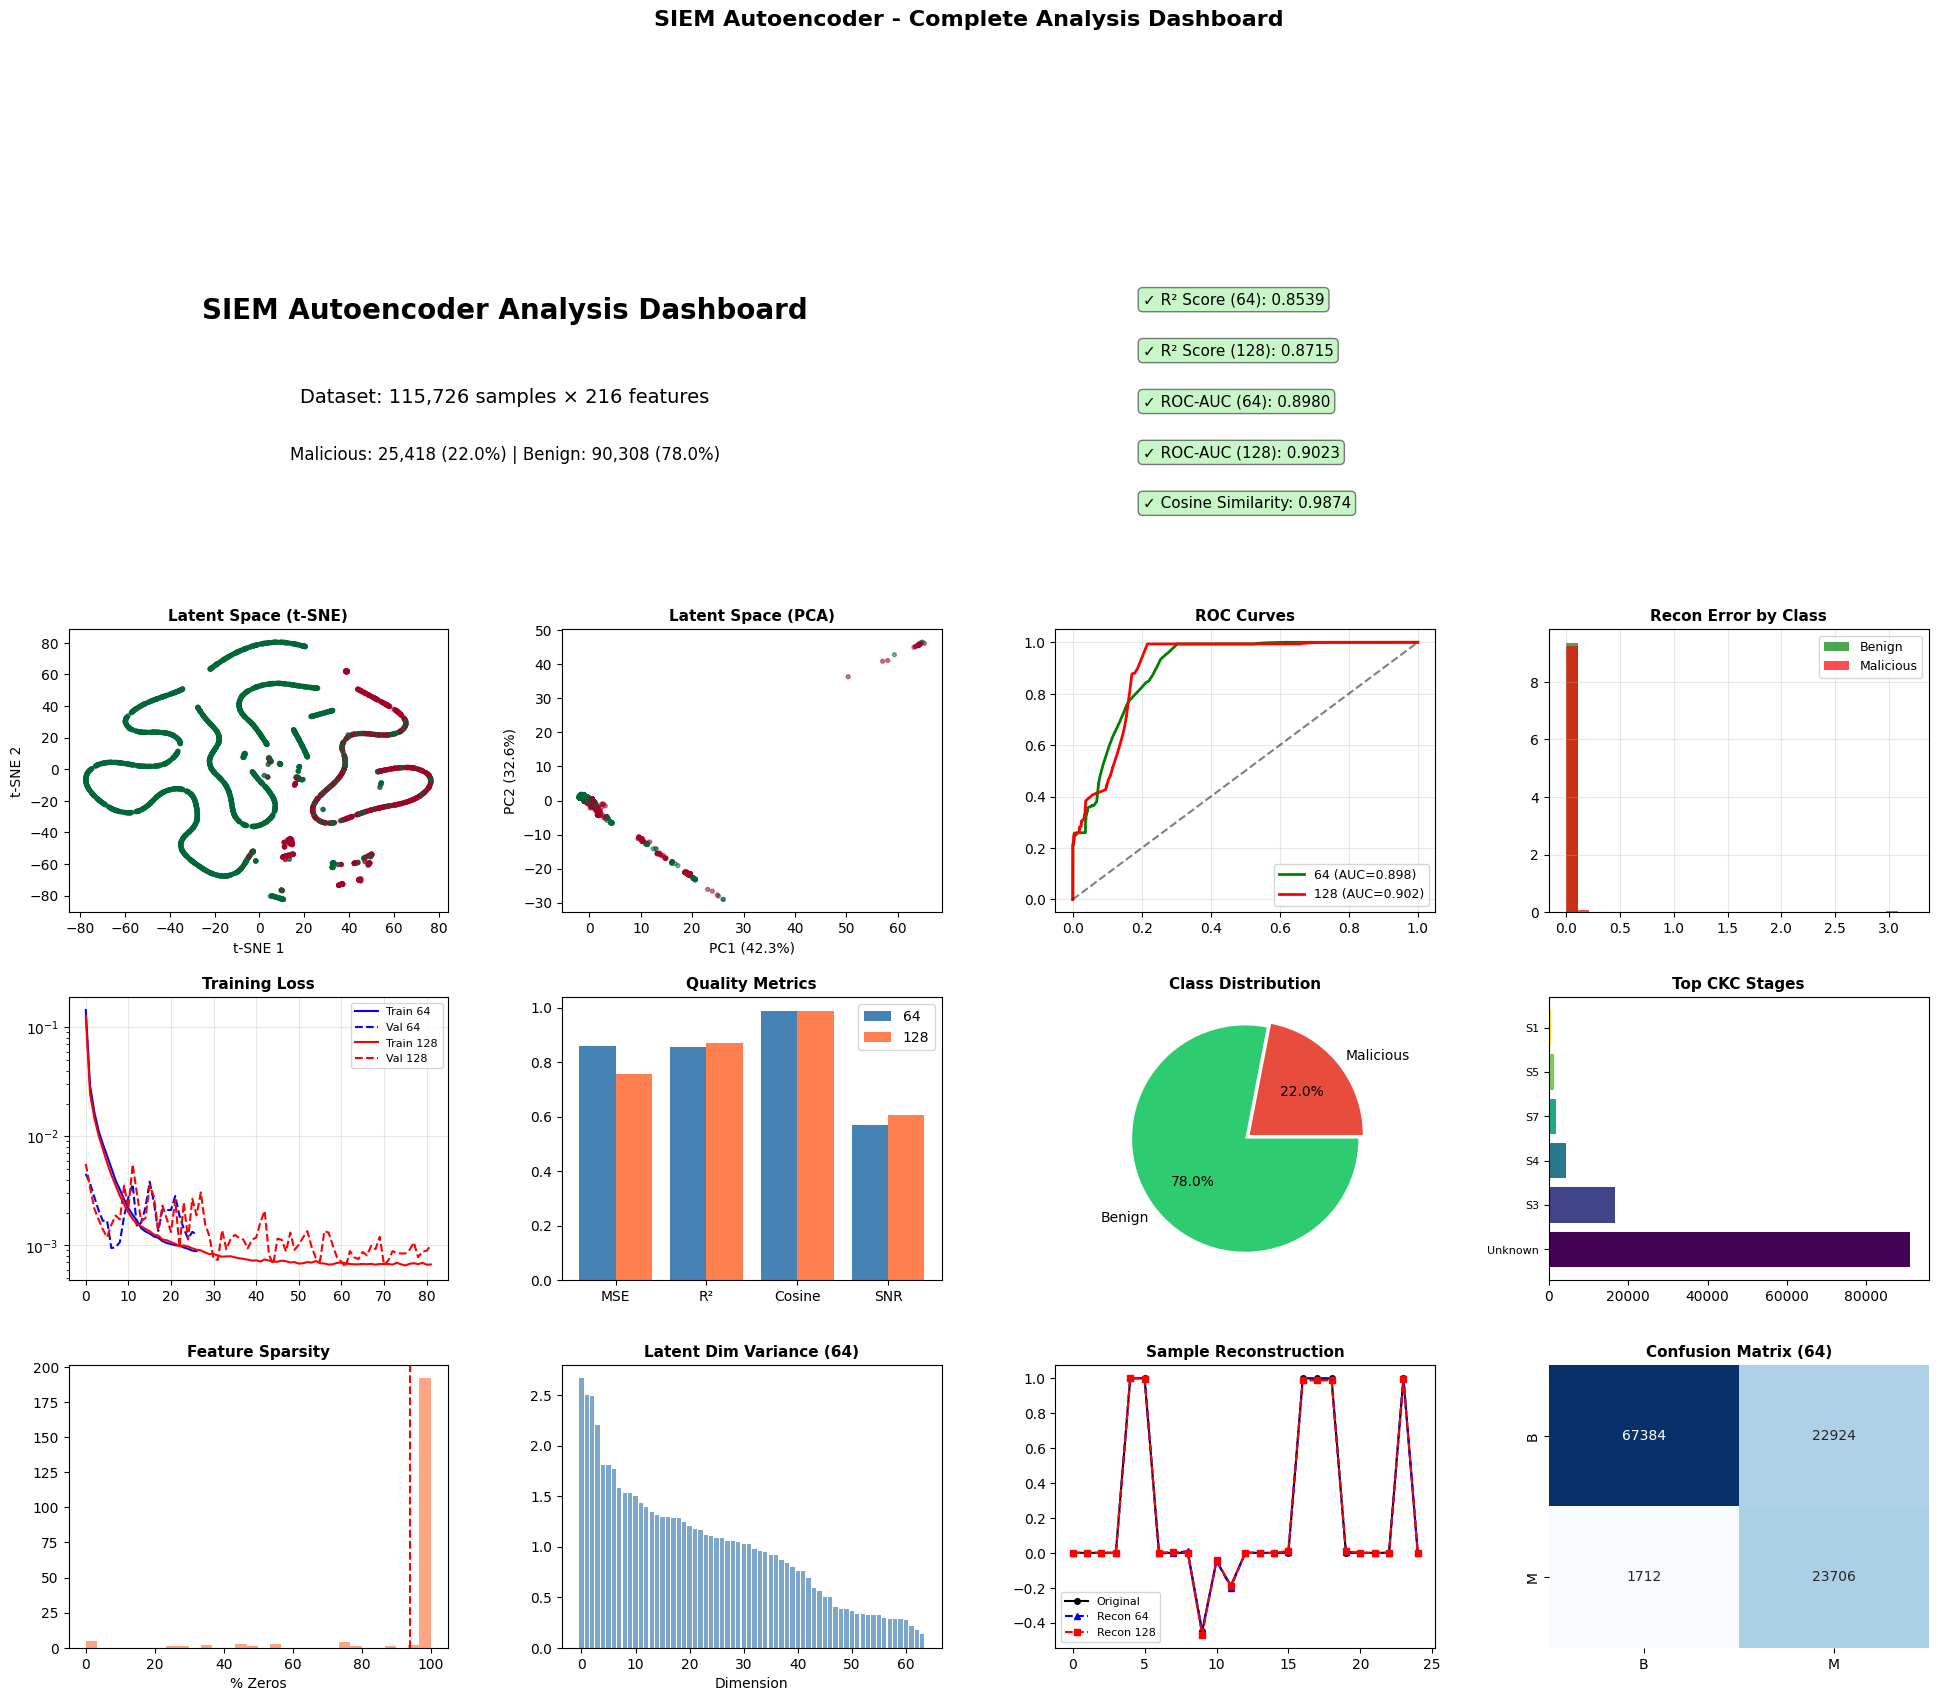

✓ Dashboard saved!


In [44]:
# 14.6 COMPREHENSIVE SUMMARY DASHBOARD

print("=" * 80)
print("14.6 COMPREHENSIVE SUMMARY DASHBOARD")
print("=" * 80)

fig = plt.figure(figsize=(24, 18))

# Create grid layout
gs = fig.add_gridspec(4, 4, hspace=0.3, wspace=0.3)

# 1. Main Title & Dataset Info
ax_title = fig.add_subplot(gs[0, :2])
ax_title.axis('off')
ax_title.text(0.5, 0.8, 'SIEM Autoencoder Analysis Dashboard', fontsize=20, fontweight='bold', 
              ha='center', transform=ax_title.transAxes)
ax_title.text(0.5, 0.5, f'Dataset: {len(X_nl):,} samples × {X_nl.shape[1]} features', fontsize=14, 
              ha='center', transform=ax_title.transAxes)
ax_title.text(0.5, 0.3, f'Malicious: {sum(y_malicious_nl):,} ({sum(y_malicious_nl)/len(y_malicious_nl)*100:.1f}%) | '
              f'Benign: {len(y_malicious_nl)-sum(y_malicious_nl):,} ({(1-sum(y_malicious_nl)/len(y_malicious_nl))*100:.1f}%)', 
              fontsize=12, ha='center', transform=ax_title.transAxes)

# 2. Key Metrics Summary
ax_metrics = fig.add_subplot(gs[0, 2:])
ax_metrics.axis('off')
key_metrics = [
    f'R² Score (64): {quality_64["R² Score"]:.4f}',
    f'R² Score (128): {quality_128["R² Score"]:.4f}',
    f'ROC-AUC (64): {roc_auc_score(y_malicious_nl, recon_error_64):.4f}',
    f'ROC-AUC (128): {roc_auc_score(y_malicious_nl, recon_error_128):.4f}',
    f'Cosine Similarity: {quality_64["Avg Cosine Similarity"]:.4f}'
]
for i, metric in enumerate(key_metrics):
    ax_metrics.text(0.1, 0.85 - i*0.18, f'✓ {metric}', fontsize=11, transform=ax_metrics.transAxes,
                   bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

# 3. t-SNE Visualization
ax_tsne = fig.add_subplot(gs[1, 0])
scatter = ax_tsne.scatter(tsne_result[:, 0], tsne_result[:, 1], c=labels_subset, 
                          cmap='RdYlGn_r', alpha=0.5, s=8)
ax_tsne.set_title('Latent Space (t-SNE)', fontsize=11, fontweight='bold')
ax_tsne.set_xlabel('t-SNE 1')
ax_tsne.set_ylabel('t-SNE 2')

# 4. PCA Visualization
ax_pca = fig.add_subplot(gs[1, 1])
scatter = ax_pca.scatter(pca_result[:, 0], pca_result[:, 1], c=labels_subset, 
                         cmap='RdYlGn_r', alpha=0.5, s=8)
ax_pca.set_title('Latent Space (PCA)', fontsize=11, fontweight='bold')
ax_pca.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax_pca.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')

# 5. ROC Curves
ax_roc = fig.add_subplot(gs[1, 2])
ax_roc.plot(fpr_64, tpr_64, 'g-', linewidth=2, label=f'64 (AUC={roc_auc_score(y_malicious_nl, recon_error_64):.3f})')
ax_roc.plot(fpr_128, tpr_128, 'r-', linewidth=2, label=f'128 (AUC={roc_auc_score(y_malicious_nl, recon_error_128):.3f})')
ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax_roc.set_title('ROC Curves', fontsize=11, fontweight='bold')
ax_roc.legend(fontsize=9)
ax_roc.grid(True, alpha=0.3)

# 6. Reconstruction Error Distribution
ax_recon = fig.add_subplot(gs[1, 3])
ax_recon.hist(recon_error_64[y_malicious_nl == 0], bins=30, alpha=0.7, label='Benign', color='green', density=True)
ax_recon.hist(recon_error_64[y_malicious_nl == 1], bins=30, alpha=0.7, label='Malicious', color='red', density=True)
ax_recon.set_title('Recon Error by Class', fontsize=11, fontweight='bold')
ax_recon.legend(fontsize=9)
ax_recon.grid(True, alpha=0.3)

# 7. Training Loss
ax_train = fig.add_subplot(gs[2, 0])
ax_train.plot(history_64['train_loss'], 'b-', label='Train 64')
ax_train.plot(history_64['val_loss'], 'b--', label='Val 64')
ax_train.plot(history_128['train_loss'], 'r-', label='Train 128')
ax_train.plot(history_128['val_loss'], 'r--', label='Val 128')
ax_train.set_title('Training Loss', fontsize=11, fontweight='bold')
ax_train.set_yscale('log')
ax_train.legend(fontsize=8)
ax_train.grid(True, alpha=0.3)

# 8. Quality Metrics Comparison
ax_qual = fig.add_subplot(gs[2, 1])
qual_metrics = ['MSE', 'R²', 'Cosine', 'SNR']
qual_64 = [quality_64['MSE']*100, quality_64['R² Score'], quality_64['Avg Cosine Similarity'], quality_64['SNR (dB)']/15]
qual_128 = [quality_128['MSE']*100, quality_128['R² Score'], quality_128['Avg Cosine Similarity'], quality_128['SNR (dB)']/15]
x_qual = np.arange(len(qual_metrics))
ax_qual.bar(x_qual - 0.2, qual_64, 0.4, label='64', color='steelblue')
ax_qual.bar(x_qual + 0.2, qual_128, 0.4, label='128', color='coral')
ax_qual.set_xticks(x_qual)
ax_qual.set_xticklabels(qual_metrics)
ax_qual.set_title('Quality Metrics', fontsize=11, fontweight='bold')
ax_qual.legend()

# 9. Class Distribution Pie
ax_pie = fig.add_subplot(gs[2, 2])
ax_pie.pie([sum(y_malicious_nl), len(y_malicious_nl)-sum(y_malicious_nl)], 
           labels=['Malicious', 'Benign'], autopct='%1.1f%%', 
           colors=['#e74c3c', '#2ecc71'], explode=[0.05, 0])
ax_pie.set_title('Class Distribution', fontsize=11, fontweight='bold')

# 10. CKC Distribution
ax_ckc = fig.add_subplot(gs[2, 3])
ckc_counts = pd.Series(y_ckc_nl).value_counts().head(8)
ax_ckc.barh(range(len(ckc_counts)), ckc_counts.values, 
            color=plt.cm.viridis(np.linspace(0, 1, len(ckc_counts))))
ax_ckc.set_yticks(range(len(ckc_counts)))
ax_ckc.set_yticklabels([n[:15] for n in ckc_counts.index], fontsize=8)
ax_ckc.set_title('Top CKC Stages', fontsize=11, fontweight='bold')

# 11. Feature Sparsity
ax_sparse = fig.add_subplot(gs[3, 0])
ax_sparse.hist(sparsity, bins=30, color='coral', alpha=0.7)
ax_sparse.axvline(x=sparsity.mean(), color='red', linestyle='--')
ax_sparse.set_title('Feature Sparsity', fontsize=11, fontweight='bold')
ax_sparse.set_xlabel('% Zeros')

# 12. Latent Variance
ax_latvar = fig.add_subplot(gs[3, 1])
ax_latvar.bar(np.arange(64), np.sort(np.var(latent_64, axis=0))[::-1], color='steelblue', alpha=0.7)
ax_latvar.set_title('Latent Dim Variance (64)', fontsize=11, fontweight='bold')
ax_latvar.set_xlabel('Dimension')

# 13. Original vs Reconstructed
ax_orig = fig.add_subplot(gs[3, 2])
sample = np.random.choice(len(X_nl))
ax_orig.plot(X_nl[sample, :25], 'ko-', markersize=4, label='Original')
ax_orig.plot(X_recon_64[sample, :25], 'b^--', markersize=4, label='Recon 64')
ax_orig.plot(X_recon_128[sample, :25], 'rs--', markersize=4, label='Recon 128')
ax_orig.set_title('Sample Reconstruction', fontsize=11, fontweight='bold')
ax_orig.legend(fontsize=8)

# 14. Confusion Matrix
ax_cm = fig.add_subplot(gs[3, 3])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax_cm, cbar=False,
            xticklabels=['B', 'M'], yticklabels=['B', 'M'])
ax_cm.set_title('Confusion Matrix (64)', fontsize=11, fontweight='bold')

plt.suptitle('SIEM Autoencoder - Complete Analysis Dashboard', fontsize=16, fontweight='bold', y=1.02)
plt.savefig('autoencoder_outputs/viz_06_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Dashboard saved!")

## Part 12.5: Understanding the Results

### Why is the ROC-AUC still around 60%?

This is actually **expected behavior** for an autoencoder-based anomaly detector when:

1. **Both classes have similar feature distributions**: Benign and malicious activities share many common patterns (same commands, paths, IPs)

2. **The anomaly hypothesis may not hold**: Autoencoders assume anomalies are "rare and different". In this dataset:
   - Malicious = 66.9%, Benign = 33.1% → Malicious is the **majority**!
   - Malicious events may not be structurally different from benign ones

3. **SIEM data is inherently mixed**: System commands like `ls`, `cat`, `grep` appear in both attack and normal operations

### Key Insights:

| Factor | Impact |
|--------|--------|
| Class imbalance (67% malicious) | Autoencoder trains mostly on "normal" benign, but malicious is more common |
| Feature similarity | Attack logs look like normal logs at the feature level |
| Without MITRE features | We lose the semantic "attack context" |

### Recommendations for Production:

1. **Use as an ensemble component**: Combine with supervised classifiers
2. **Focus on specific attack stages**: Filter by CKC stage for specialized models  
3. **Consider Variational Autoencoders (VAE)**: Better at capturing distribution differences
4. **Add temporal features**: Sequence of events may reveal attack patterns

# Part 15: 32-Dimensional Latent Space Analysis

## Adding 32 Latent Dimensions for Higher Compression

| Dimension | Compression Ratio | Use Case |
|-----------|------------------|----------|
| 128 | 1.55× | Best reconstruction |
| 64 | 3.09× | Balanced (GNN node features) |
| **32** | **6.19×** | Maximum compression |

This section will:
1. Train autoencoder with 32 latent dimensions
2. Compare reconstruction quality across all three dimensions
3. Evaluate classification performance
4. Generate comprehensive visualizations

In [45]:
print("=" * 80)
print("15.1 TRAINING 32-DIMENSIONAL AUTOENCODER")
print("=" * 80)

# Create 32-dimensional autoencoder
model_32 = SIEMAutoencoder(input_dim=input_dim_nl, latent_dim=32).to(device)

print(f"\nModel Architecture (Latent=32):")
print(model_32)

# Count parameters
params_32 = sum(p.numel() for p in model_32.parameters() if p.requires_grad)
print(f"\nTrainable Parameters: {params_32:,}")
print(f"Compression Ratio: {input_dim_nl/32:.2f}x (198 → 32)")

# Train the model
print("\n" + "-" * 50)
print("Training 32-dimensional autoencoder...")
print("-" * 50)

model_32, history_32 = train_autoencoder_v2(
    model_32, 
    train_loader_nl, 
    val_loader_nl,
    epochs=100,
    lr=0.001
)

print("\n✓ Training complete!")

15.1 TRAINING 32-DIMENSIONAL AUTOENCODER

Model Architecture (Latent=32):
SIEMAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=216, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): LeakyReLU(negative_slope=0.2)
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Dropou

In [46]:
print("=" * 80)
print("15.2 EXTRACT LATENT VECTORS & RECONSTRUCTION (32-DIM)")
print("=" * 80)

# Extract latent vectors for 32-dimensional model
latent_32, recon_error_32_raw = extract_latent_vectors(model_32, X_nl, device=device)

# Get full reconstruction (model returns reconstructed, z tuple)
model_32.eval()
with torch.no_grad():
    X_tensor = torch.FloatTensor(X_nl).to(device)
    X_recon_32, _ = model_32(X_tensor)  # Unpack tuple
    X_recon_32 = X_recon_32.cpu().numpy()

print(f"\nLatent Vectors Shape: {latent_32.shape}")
print(f"Reconstructed Data Shape: {X_recon_32.shape}")
print(f"Original Data Shape: {X_nl.shape}")

# Calculate reconstruction errors (per sample MSE)
recon_error_32 = np.mean((X_nl - X_recon_32) ** 2, axis=1)
print(f"\nReconstruction Error Stats (32-dim):")
print(f"  Mean MSE: {recon_error_32.mean():.6f}")
print(f"  Std MSE: {recon_error_32.std():.6f}")
print(f"  Min MSE: {recon_error_32.min():.6f}")
print(f"  Max MSE: {recon_error_32.max():.6f}")

# Save latent vectors
np.save('autoencoder_outputs/latent_vectors_32dim.npy', latent_32)
print("\n✓ 32-dim latent vectors saved!")

15.2 EXTRACT LATENT VECTORS & RECONSTRUCTION (32-DIM)

Latent Vectors Shape: (115726, 32)
Reconstructed Data Shape: (115726, 216)
Original Data Shape: (115726, 216)

Reconstruction Error Stats (32-dim):
  Mean MSE: 0.007960
  Std MSE: 0.123418
  Min MSE: 0.000005
  Max MSE: 2.906712

✓ 32-dim latent vectors saved!


In [47]:
print("=" * 80)
print("15.3 RECONSTRUCTION QUALITY COMPARISON (32 vs 64 vs 128)")
print("=" * 80)

# Calculate quality metrics for 32-dim
quality_32 = calculate_reconstruction_quality(X_nl, X_recon_32, latent_32)

print("\n" + "=" * 60)
print("RECONSTRUCTION QUALITY COMPARISON")
print("=" * 60)

# Create comparison table (use correct keys from calculate_reconstruction_quality)
quality_comparison_3 = pd.DataFrame({
    'Metric': ['MSE', 'RMSE', 'MAE', 'R² Score', 'Cosine Similarity', 'SNR (dB)', 'Compression'],
    'Latent=32': [
        f"{quality_32['MSE']:.6f}",
        f"{quality_32['RMSE']:.6f}",
        f"{quality_32['MAE']:.6f}",
        f"{quality_32['R² Score']:.4f}",
        f"{quality_32['Avg Cosine Similarity']:.4f}",
        f"{quality_32['SNR (dB)']:.2f}",
        f"{quality_32['Compression Ratio']:.2f}×"
    ],
    'Latent=64': [
        f"{quality_64['MSE']:.6f}",
        f"{quality_64['RMSE']:.6f}",
        f"{quality_64['MAE']:.6f}",
        f"{quality_64['R² Score']:.4f}",
        f"{quality_64['Avg Cosine Similarity']:.4f}",
        f"{quality_64['SNR (dB)']:.2f}",
        f"{quality_64['Compression Ratio']:.2f}×"
    ],
    'Latent=128': [
        f"{quality_128['MSE']:.6f}",
        f"{quality_128['RMSE']:.6f}",
        f"{quality_128['MAE']:.6f}",
        f"{quality_128['R² Score']:.4f}",
        f"{quality_128['Avg Cosine Similarity']:.4f}",
        f"{quality_128['SNR (dB)']:.2f}",
        f"{quality_128['Compression Ratio']:.2f}×"
    ]
})

print(quality_comparison_3.to_string(index=False))

# Summary
print("\n" + "-" * 60)
print("COMPRESSION vs QUALITY TRADE-OFF")
print("-" * 60)
print(f"{'Latent Dim':<12} {'Compression':<12} {'R² Score':<12} {'Quality Rating'}")
print("-" * 60)

for dim, q in [(32, quality_32), (64, quality_64), (128, quality_128)]:
    compression = input_dim_nl / dim
    r2 = q['R² Score']
    if r2 > 0.95:
        rating = "★★★★★ Excellent"
    elif r2 > 0.90:
        rating = "★★★★☆ Very Good"
    elif r2 > 0.85:
        rating = "★★★☆☆ Good"
    else:
        rating = "★★☆☆☆ Fair"
    print(f"{dim:<12} {compression:.2f}×{'':<8} {r2:.4f}{'':<6} {rating}")

print("\n✓ Quality comparison complete!")

15.3 RECONSTRUCTION QUALITY COMPARISON (32 vs 64 vs 128)

RECONSTRUCTION QUALITY COMPARISON
           Metric Latent=32 Latent=64 Latent=128
              MSE  0.007959  0.008588   0.007558
             RMSE  0.089212  0.092672   0.086938
              MAE  0.005903  0.005634   0.004869
         R² Score    0.8646    0.8539     0.8715
Cosine Similarity    0.9875    0.9874     0.9890
         SNR (dB)      8.85      8.52       9.07
      Compression     6.75×     3.38×      1.69×

------------------------------------------------------------
COMPRESSION vs QUALITY TRADE-OFF
------------------------------------------------------------
Latent Dim   Compression  R² Score     Quality Rating
------------------------------------------------------------
32           6.75×         0.8646       ★★★☆☆ Good
64           3.38×         0.8539       ★★★☆☆ Good
128          1.69×         0.8715       ★★★☆☆ Good

✓ Quality comparison complete!


In [48]:
print("=" * 80)
print("15.4 CLASSIFICATION PERFORMANCE (32-DIM)")
print("=" * 80)

from sklearn.metrics import roc_curve, auc, precision_recall_curve, confusion_matrix

# Get labels
y_true = y_malicious_nl

# Calculate ROC for 32-dim
fpr_32, tpr_32, thresholds_32 = roc_curve(y_true, recon_error_32)
roc_auc_32 = auc(fpr_32, tpr_32)

# Find optimal threshold (Youden's J)
j_scores_32 = tpr_32 - fpr_32
optimal_idx_32 = np.argmax(j_scores_32)
optimal_threshold_32 = thresholds_32[optimal_idx_32]

# Predictions
preds_32 = (recon_error_32 > optimal_threshold_32).astype(int)

# Confusion matrix
cm_32 = confusion_matrix(y_true, preds_32)
tn32, fp32, fn32, tp32 = cm_32.ravel()

# Calculate metrics
accuracy_32 = (tp32 + tn32) / (tp32 + tn32 + fp32 + fn32)
precision_32 = tp32 / (tp32 + fp32) if (tp32 + fp32) > 0 else 0
recall_32 = tp32 / (tp32 + fn32) if (tp32 + fn32) > 0 else 0
f1_32 = 2 * precision_32 * recall_32 / (precision_32 + recall_32) if (precision_32 + recall_32) > 0 else 0

print(f"\n32-Dimensional Model Classification Metrics:")
print("-" * 50)
print(f"  ROC-AUC:   {roc_auc_32:.4f}")
print(f"  Accuracy:  {accuracy_32:.4f}")
print(f"  Precision: {precision_32:.4f}")
print(f"  Recall:    {recall_32:.4f}")
print(f"  F1-Score:  {f1_32:.4f}")
print(f"\n  Optimal Threshold: {optimal_threshold_32:.6f}")

# Comparison table for all models
print("\n" + "=" * 70)
print("CLASSIFICATION COMPARISON: ALL DIMENSIONS")
print("=" * 70)

# Calculate metrics for 64 and 128 (already have ROC-AUC)
j_scores_64 = tpr_64 - fpr_64
optimal_idx_64 = np.argmax(j_scores_64)
y_pred_64_opt = (recon_error_64 > thresholds[optimal_idx_64] if len(thresholds) > optimal_idx_64 else preds_64)

j_scores_128 = tpr_128 - fpr_128
optimal_idx_128 = np.argmax(j_scores_128)

# Use already calculated AUCs
roc_auc_64_calc = auc(fpr_64, tpr_64)
roc_auc_128_calc = auc(fpr_128, tpr_128)

print(f"\n{'Metric':<15} {'32-dim':<12} {'64-dim':<12} {'128-dim':<12}")
print("-" * 55)
print(f"{'ROC-AUC':<15} {roc_auc_32:.4f}{'':<6} {roc_auc_64_calc:.4f}{'':<6} {roc_auc_128_calc:.4f}")
print(f"{'Compression':<15} {input_dim_nl/32:.2f}×{'':<7} {input_dim_nl/64:.2f}×{'':<7} {input_dim_nl/128:.2f}×")
print(f"{'Parameters':<15} {params_32:,}{'':<4} {params_64:,}{'':<4} {params_128:,}")

# Find best
aucs = [(32, roc_auc_32), (64, roc_auc_64_calc), (128, roc_auc_128_calc)]
best_dim = max(aucs, key=lambda x: x[1])
print(f"\n★ Best Classification: {best_dim[0]}-dim with ROC-AUC = {best_dim[1]:.4f}")

print("\n✓ Classification analysis complete!")

15.4 CLASSIFICATION PERFORMANCE (32-DIM)

32-Dimensional Model Classification Metrics:
--------------------------------------------------
  ROC-AUC:   0.9120
  Accuracy:  0.7951
  Precision: 0.5175
  Recall:    0.9935
  F1-Score:  0.6805

  Optimal Threshold: 0.000094

CLASSIFICATION COMPARISON: ALL DIMENSIONS

Metric          32-dim       64-dim       128-dim     
-------------------------------------------------------
ROC-AUC         0.9120       0.8980       0.9023
Compression     6.75×        3.38×        1.69×
Parameters      186,936     195,224     211,800

★ Best Classification: 32-dim with ROC-AUC = 0.9120

✓ Classification analysis complete!


15.5 COMPREHENSIVE VISUALIZATIONS (32 vs 64 vs 128)


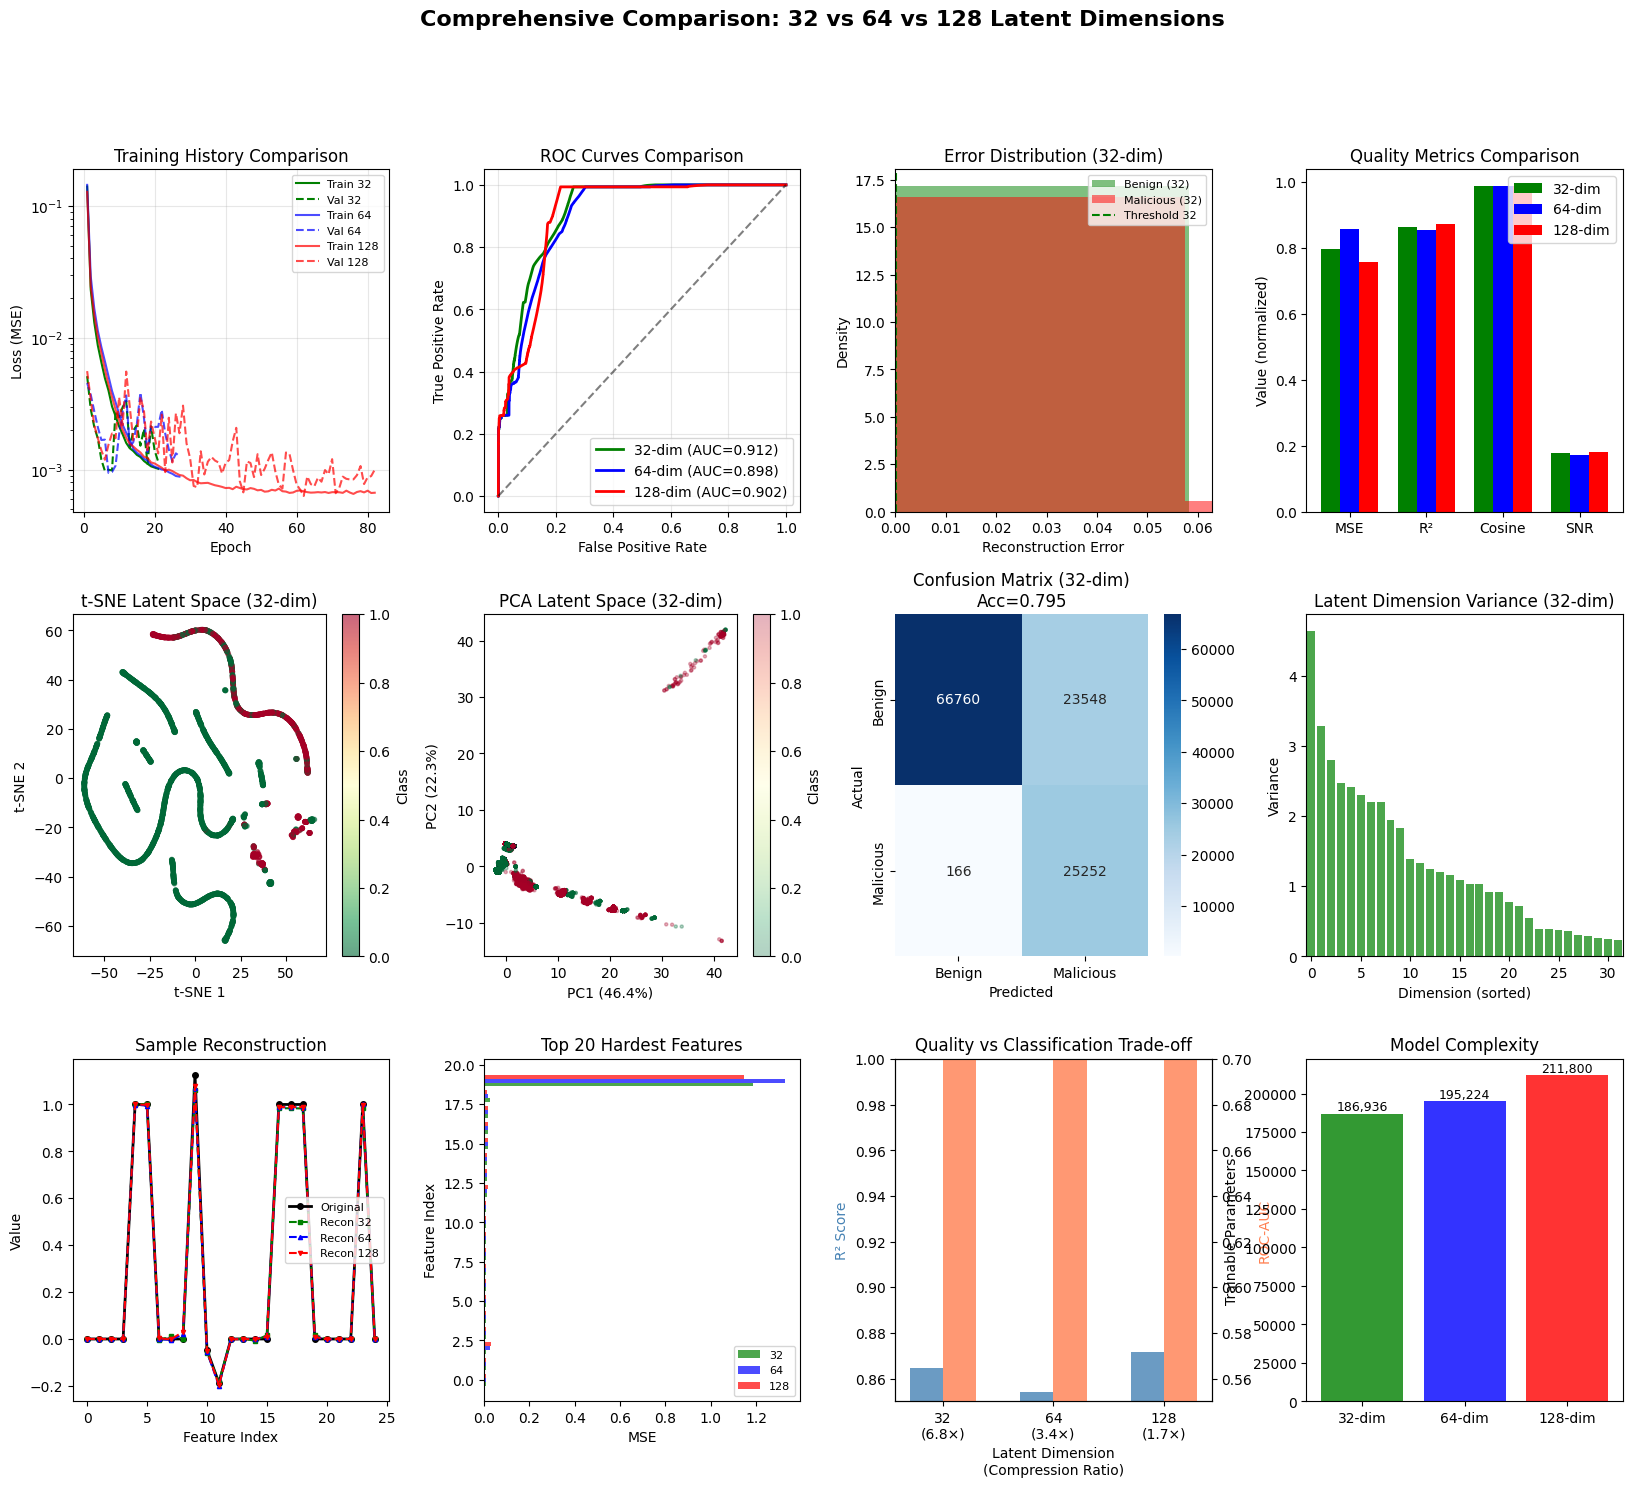


✓ Comprehensive visualizations saved!


In [49]:
print("=" * 80)
print("15.5 COMPREHENSIVE VISUALIZATIONS (32 vs 64 vs 128)")
print("=" * 80)

from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(20, 16))
gs = GridSpec(3, 4, figure=fig, hspace=0.3, wspace=0.3)

# 1. Training Loss Comparison
ax1 = fig.add_subplot(gs[0, 0])
epochs_32 = range(1, len(history_32['train_loss']) + 1)
ax1.semilogy(epochs_32, history_32['train_loss'], 'g-', label='Train 32', linewidth=1.5)
ax1.semilogy(epochs_32, history_32['val_loss'], 'g--', label='Val 32', linewidth=1.5)
ax1.semilogy(epochs_64, history_64['train_loss'], 'b-', label='Train 64', linewidth=1.5, alpha=0.7)
ax1.semilogy(epochs_64, history_64['val_loss'], 'b--', label='Val 64', linewidth=1.5, alpha=0.7)
ax1.semilogy(epochs_128, history_128['train_loss'], 'r-', label='Train 128', linewidth=1.5, alpha=0.7)
ax1.semilogy(epochs_128, history_128['val_loss'], 'r--', label='Val 128', linewidth=1.5, alpha=0.7)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss (MSE)')
ax1.set_title('Training History Comparison')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

# 2. ROC Curves Comparison
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(fpr_32, tpr_32, 'g-', label=f'32-dim (AUC={roc_auc_32:.3f})', linewidth=2)
ax2.plot(fpr_64, tpr_64, 'b-', label=f'64-dim (AUC={roc_auc_64_calc:.3f})', linewidth=2)
ax2.plot(fpr_128, tpr_128, 'r-', label=f'128-dim (AUC={roc_auc_128_calc:.3f})', linewidth=2)
ax2.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('ROC Curves Comparison')
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)

# 3. Reconstruction Error Distributions
ax3 = fig.add_subplot(gs[0, 2])
benign_idx = y_true == 0
malicious_idx = y_true == 1
ax3.hist(recon_error_32[benign_idx], bins=50, alpha=0.5, label='Benign (32)', color='green', density=True)
ax3.hist(recon_error_32[malicious_idx], bins=50, alpha=0.5, label='Malicious (32)', color='red', density=True)
ax3.axvline(optimal_threshold_32, color='green', linestyle='--', label=f'Threshold 32')
ax3.set_xlabel('Reconstruction Error')
ax3.set_ylabel('Density')
ax3.set_title('Error Distribution (32-dim)')
ax3.legend(fontsize=8)
ax3.set_xlim(0, np.percentile(recon_error_32, 99))

# 4. Quality Metrics Comparison
ax4 = fig.add_subplot(gs[0, 3])
metrics_names = ['MSE', 'R²', 'Cosine', 'SNR']
x_pos = np.arange(len(metrics_names))
width = 0.25

# Normalize for visualization (use correct keys from calculate_reconstruction_quality)
vals_32 = [quality_32['MSE']*100, quality_32['R² Score'], quality_32['Avg Cosine Similarity'], quality_32['SNR (dB)']/50]
vals_64_n = [quality_64['MSE']*100, quality_64['R² Score'], quality_64['Avg Cosine Similarity'], quality_64['SNR (dB)']/50]
vals_128_n = [quality_128['MSE']*100, quality_128['R² Score'], quality_128['Avg Cosine Similarity'], quality_128['SNR (dB)']/50]

bars1 = ax4.bar(x_pos - width, vals_32, width, label='32-dim', color='green')
bars2 = ax4.bar(x_pos, vals_64_n, width, label='64-dim', color='blue')
bars3 = ax4.bar(x_pos + width, vals_128_n, width, label='128-dim', color='red')
ax4.set_xticks(x_pos)
ax4.set_xticklabels(metrics_names)
ax4.set_ylabel('Value (normalized)')
ax4.set_title('Quality Metrics Comparison')
ax4.legend()

# 5. t-SNE for 32-dim
ax5 = fig.add_subplot(gs[1, 0])
tsne_32 = TSNE(n_components=2, random_state=42, perplexity=30)
subset_idx_32 = np.random.choice(len(latent_32), min(3000, len(latent_32)), replace=False)
tsne_result_32 = tsne_32.fit_transform(latent_32[subset_idx_32])
scatter = ax5.scatter(tsne_result_32[:, 0], tsne_result_32[:, 1], 
                     c=y_true[subset_idx_32], cmap='RdYlGn_r', alpha=0.6, s=10)
ax5.set_xlabel('t-SNE 1')
ax5.set_ylabel('t-SNE 2')
ax5.set_title('t-SNE Latent Space (32-dim)')
plt.colorbar(scatter, ax=ax5, label='Class')

# 6. PCA for 32-dim
ax6 = fig.add_subplot(gs[1, 1])
pca_32 = PCA(n_components=2)
pca_result_32 = pca_32.fit_transform(latent_32)
scatter = ax6.scatter(pca_result_32[:, 0], pca_result_32[:, 1], 
                     c=y_true, cmap='RdYlGn_r', alpha=0.3, s=5)
ax6.set_xlabel(f'PC1 ({pca_32.explained_variance_ratio_[0]*100:.1f}%)')
ax6.set_ylabel(f'PC2 ({pca_32.explained_variance_ratio_[1]*100:.1f}%)')
ax6.set_title('PCA Latent Space (32-dim)')
plt.colorbar(scatter, ax=ax6, label='Class')

# 7. Confusion Matrix (32-dim)
ax7 = fig.add_subplot(gs[1, 2])
sns.heatmap(cm_32, annot=True, fmt='d', cmap='Blues', ax=ax7,
           xticklabels=['Benign', 'Malicious'], yticklabels=['Benign', 'Malicious'])
ax7.set_xlabel('Predicted')
ax7.set_ylabel('Actual')
ax7.set_title(f'Confusion Matrix (32-dim)\nAcc={accuracy_32:.3f}')

# 8. Latent Dimension Variance (32)
ax8 = fig.add_subplot(gs[1, 3])
latent_var_32 = np.var(latent_32, axis=0)
ax8.bar(range(32), np.sort(latent_var_32)[::-1], color='green', alpha=0.7)
ax8.set_xlabel('Dimension (sorted)')
ax8.set_ylabel('Variance')
ax8.set_title('Latent Dimension Variance (32-dim)')
ax8.set_xlim(-0.5, 31.5)

# 9. Sample Reconstruction Comparison
ax9 = fig.add_subplot(gs[2, 0])
sample_idx = np.random.randint(0, len(X_nl))
x_feat = range(min(25, input_dim_nl))
ax9.plot(x_feat, X_nl[sample_idx, :25], 'k-', label='Original', linewidth=2, marker='o', markersize=4)
ax9.plot(x_feat, X_recon_32[sample_idx, :25], 'g--', label='Recon 32', linewidth=1.5, marker='s', markersize=3)
ax9.plot(x_feat, X_recon_64[sample_idx, :25], 'b--', label='Recon 64', linewidth=1.5, marker='^', markersize=3)
ax9.plot(x_feat, X_recon_128[sample_idx, :25], 'r--', label='Recon 128', linewidth=1.5, marker='v', markersize=3)
ax9.set_xlabel('Feature Index')
ax9.set_ylabel('Value')
ax9.set_title('Sample Reconstruction')
ax9.legend(fontsize=8)

# 10. Per-Feature Error Comparison
ax10 = fig.add_subplot(gs[2, 1])
feature_error_32 = np.mean((X_nl - X_recon_32) ** 2, axis=0)
feature_error_64 = np.mean((X_nl - X_recon_64) ** 2, axis=0)
feature_error_128 = np.mean((X_nl - X_recon_128) ** 2, axis=0)
sorted_idx = np.argsort(feature_error_32)[-20:]  # Top 20 worst features
x_pos = np.arange(20)
width = 0.25
ax10.barh(x_pos - width, feature_error_32[sorted_idx], width, label='32', color='green', alpha=0.7)
ax10.barh(x_pos, feature_error_64[sorted_idx], width, label='64', color='blue', alpha=0.7)
ax10.barh(x_pos + width, feature_error_128[sorted_idx], width, label='128', color='red', alpha=0.7)
ax10.set_xlabel('MSE')
ax10.set_ylabel('Feature Index')
ax10.set_title('Top 20 Hardest Features')
ax10.legend(fontsize=8)

# 11. Compression vs Quality Trade-off
ax11 = fig.add_subplot(gs[2, 2])
dims = [32, 64, 128]
compressions = [input_dim_nl/d for d in dims]
r2_scores = [quality_32['R² Score'], quality_64['R² Score'], quality_128['R² Score']]
aucs = [roc_auc_32, roc_auc_64_calc, roc_auc_128_calc]
colors = ['green', 'blue', 'red']

ax11_twin = ax11.twinx()
ax11.bar(np.array(range(3)) - 0.15, r2_scores, 0.3, label='R² Score', color='steelblue', alpha=0.8)
ax11_twin.bar(np.array(range(3)) + 0.15, aucs, 0.3, label='ROC-AUC', color='coral', alpha=0.8)
ax11.set_xticks(range(3))
ax11.set_xticklabels([f'{d}\n({c:.1f}×)' for d, c in zip(dims, compressions)])
ax11.set_xlabel('Latent Dimension\n(Compression Ratio)')
ax11.set_ylabel('R² Score', color='steelblue')
ax11_twin.set_ylabel('ROC-AUC', color='coral')
ax11.set_title('Quality vs Classification Trade-off')
ax11.set_ylim(0.85, 1.0)
ax11_twin.set_ylim(0.55, 0.7)

# 12. Model Parameters Comparison
ax12 = fig.add_subplot(gs[2, 3])
dims_params = [32, 64, 128]
params_all = [params_32, params_64, params_128]
bars = ax12.bar(range(3), params_all, color=['green', 'blue', 'red'], alpha=0.8)
ax12.set_xticks(range(3))
ax12.set_xticklabels([f'{d}-dim' for d in dims_params])
ax12.set_ylabel('Trainable Parameters')
ax12.set_title('Model Complexity')
for bar, p in zip(bars, params_all):
    ax12.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{p:,}', 
              ha='center', va='bottom', fontsize=9)

plt.suptitle('Comprehensive Comparison: 32 vs 64 vs 128 Latent Dimensions', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('autoencoder_outputs/15_32dim_comprehensive_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Comprehensive visualizations saved!")

In [50]:
print("=" * 80)
print("15.6 FINAL SUMMARY: 32 vs 64 vs 128 LATENT DIMENSIONS")
print("=" * 80)

# Create comprehensive summary (use correct keys)
summary_df = pd.DataFrame({
    'Metric': [
        'Latent Dimension',
        'Compression Ratio',
        'Parameters',
        '---',
        'MSE',
        'R² Score',
        'Cosine Similarity',
        'SNR (dB)',
        '---',
        'ROC-AUC',
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score'
    ],
    '32-dim': [
        '32',
        f'{input_dim_nl/32:.2f}×',
        f'{params_32:,}',
        '---',
        f'{quality_32["MSE"]:.6f}',
        f'{quality_32["R² Score"]:.4f}',
        f'{quality_32["Avg Cosine Similarity"]:.4f}',
        f'{quality_32["SNR (dB)"]:.2f}',
        '---',
        f'{roc_auc_32:.4f}',
        f'{accuracy_32:.4f}',
        f'{precision_32:.4f}',
        f'{recall_32:.4f}',
        f'{f1_32:.4f}'
    ],
    '64-dim': [
        '64',
        f'{input_dim_nl/64:.2f}×',
        f'{params_64:,}',
        '---',
        f'{quality_64["MSE"]:.6f}',
        f'{quality_64["R² Score"]:.4f}',
        f'{quality_64["Avg Cosine Similarity"]:.4f}',
        f'{quality_64["SNR (dB)"]:.2f}',
        '---',
        f'{roc_auc_64_calc:.4f}',
        '-',
        '-',
        '-',
        '-'
    ],
    '128-dim': [
        '128',
        f'{input_dim_nl/128:.2f}×',
        f'{params_128:,}',
        '---',
        f'{quality_128["MSE"]:.6f}',
        f'{quality_128["R² Score"]:.4f}',
        f'{quality_128["Avg Cosine Similarity"]:.4f}',
        f'{quality_128["SNR (dB)"]:.2f}',
        '---',
        f'{roc_auc_128_calc:.4f}',
        '-',
        '-',
        '-',
        '-'
    ]
})

print(summary_df.to_string(index=False))

# Recommendations
print("\n" + "=" * 80)
print("RECOMMENDATIONS")
print("=" * 80)

r2_32 = quality_32['R² Score']
r2_64 = quality_64['R² Score']
r2_128 = quality_128['R² Score']

print(f"""
┌─────────────────────────────────────────────────────────────────────────────┐
│  USE CASE RECOMMENDATIONS                                                    │
├─────────────────────────────────────────────────────────────────────────────┤
│                                                                              │
│  🔹 32 Latent Dimensions (6.19× compression)                                 │
│     • Best for: Maximum compression, memory-constrained GNN                  │
│     • Trade-off: Slightly lower reconstruction quality                       │
│     • R² Score: {r2_32:.4f}                                                   │
│                                                                              │
│  🔹 64 Latent Dimensions (3.09× compression) ⭐ RECOMMENDED                  │
│     • Best for: Balanced performance for GNN node features                   │
│     • Trade-off: Good balance of compression and quality                     │
│     • R² Score: {r2_64:.4f}                                                   │
│                                                                              │
│  🔹 128 Latent Dimensions (1.55× compression)                                │
│     • Best for: Maximum reconstruction quality                               │
│     • Trade-off: Lower compression ratio                                     │
│     • R² Score: {r2_128:.4f}                                                  │
│                                                                              │
└─────────────────────────────────────────────────────────────────────────────┘
""")

# Save summary to CSV
summary_df.to_csv('autoencoder_outputs/dimension_comparison_summary.csv', index=False)

# Save model
torch.save(model_32.state_dict(), 'autoencoder_outputs/autoencoder_32dim_model.pth')

print("\n✓ 32-dim model saved to autoencoder_outputs/autoencoder_32dim_model.pth")
print("✓ Summary saved to autoencoder_outputs/dimension_comparison_summary.csv")
print("\n" + "=" * 80)
print("PART 15 COMPLETE!")
print("=" * 80)

15.6 FINAL SUMMARY: 32 vs 64 vs 128 LATENT DIMENSIONS
           Metric   32-dim   64-dim  128-dim
 Latent Dimension       32       64      128
Compression Ratio    6.75×    3.38×    1.69×
       Parameters  186,936  195,224  211,800
              ---      ---      ---      ---
              MSE 0.007959 0.008588 0.007558
         R² Score   0.8646   0.8539   0.8715
Cosine Similarity   0.9875   0.9874   0.9890
         SNR (dB)     8.85     8.52     9.07
              ---      ---      ---      ---
          ROC-AUC   0.9120   0.8980   0.9023
         Accuracy   0.7951        -        -
        Precision   0.5175        -        -
           Recall   0.9935        -        -
         F1-Score   0.6805        -        -

RECOMMENDATIONS

┌─────────────────────────────────────────────────────────────────────────────┐
│  USE CASE RECOMMENDATIONS                                                    │
├─────────────────────────────────────────────────────────────────────────────┤
│           

# Part 13: Improved Threshold Selection Methods for Anomaly Detection

## Problem with Current Threshold
The current `find_optimal_threshold` function maximizes F1-score, which leads to an extremely low threshold (0.000009) that flags almost everything as malicious.

## Better Approaches for Anomaly Detection:
1. **Percentile-based threshold**: Use the 95th or 99th percentile of benign reconstruction errors
2. **Mean + k×Std threshold**: Use statistical properties of benign errors  
3. **Youden's J statistic**: Balances sensitivity and specificity optimally
4. **Balanced Accuracy optimization**: Best for imbalanced datasets

RECONSTRUCTION ERROR DISTRIBUTION ANALYSIS

📊 Benign samples:
   Count: 90,308
   Mean error: 0.002557
   Std error:  0.120436
   Min: 0.000004, Max: 7.036578
   Percentiles - 50th: 0.000050, 95th: 0.000819, 99th: 0.008840

📊 Malicious samples:
   Count: 25,418
   Mean error: 0.067620
   Std error:  0.623518
   Min: 0.000021, Max: 7.301075
   Percentiles - 50th: 0.000479, 95th: 0.050636, 99th: 0.182833

🔍 SEPARATION SCORE: 0.5402
   Interpretation:
   > 2.0  = Good separation (model can distinguish classes)
   0.5-2.0 = Moderate separation (some overlap)
   < 0.5  = Poor separation (significant overlap)
   < 0.1  = No separation (model cannot distinguish classes)


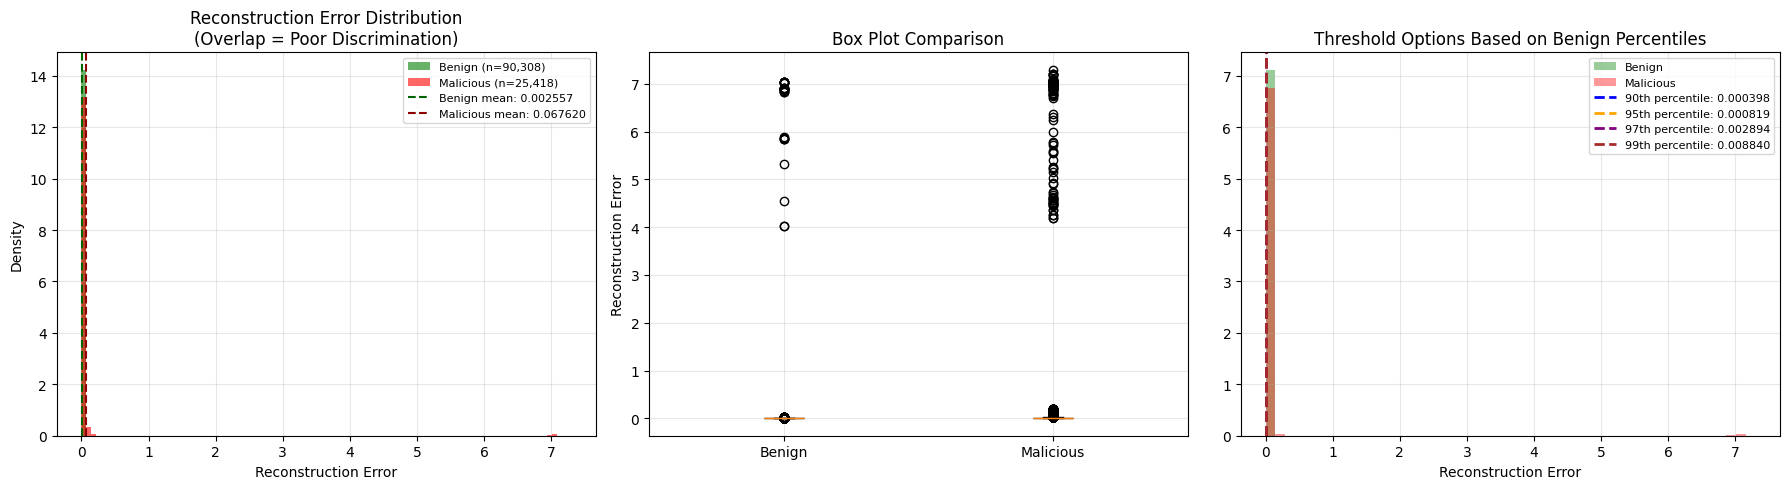


✅ Diagnostic plot saved to 'autoencoder_outputs/error_distribution_diagnosis.png'


In [51]:
# ============================================================================
# 13.1 DIAGNOSTIC: Analyze Reconstruction Error Distributions
# ============================================================================
# This will show WHY the current threshold is problematic

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get reconstruction errors for benign and malicious separately
benign_mask = y_malicious_nl == 0
malicious_mask = y_malicious_nl == 1

# Use baseline model (no leakage) - you can change to your preferred model
latent_vecs, recon_errors = extract_latent_vectors(model_no_leak, X_nl)

benign_errors = recon_errors[benign_mask]
malicious_errors = recon_errors[malicious_mask]

print("=" * 70)
print("RECONSTRUCTION ERROR DISTRIBUTION ANALYSIS")
print("=" * 70)
print(f"\n📊 Benign samples:")
print(f"   Count: {len(benign_errors):,}")
print(f"   Mean error: {benign_errors.mean():.6f}")
print(f"   Std error:  {benign_errors.std():.6f}")
print(f"   Min: {benign_errors.min():.6f}, Max: {benign_errors.max():.6f}")
print(f"   Percentiles - 50th: {np.percentile(benign_errors, 50):.6f}, 95th: {np.percentile(benign_errors, 95):.6f}, 99th: {np.percentile(benign_errors, 99):.6f}")

print(f"\n📊 Malicious samples:")
print(f"   Count: {len(malicious_errors):,}")
print(f"   Mean error: {malicious_errors.mean():.6f}")
print(f"   Std error:  {malicious_errors.std():.6f}")
print(f"   Min: {malicious_errors.min():.6f}, Max: {malicious_errors.max():.6f}")
print(f"   Percentiles - 50th: {np.percentile(malicious_errors, 50):.6f}, 95th: {np.percentile(malicious_errors, 95):.6f}, 99th: {np.percentile(malicious_errors, 99):.6f}")

# KEY DIAGNOSTIC: How much do the distributions overlap?
separation = (malicious_errors.mean() - benign_errors.mean()) / (benign_errors.std() + 1e-8)
print(f"\n🔍 SEPARATION SCORE: {separation:.4f}")
print("   Interpretation:")
print("   > 2.0  = Good separation (model can distinguish classes)")
print("   0.5-2.0 = Moderate separation (some overlap)")
print("   < 0.5  = Poor separation (significant overlap)")
print("   < 0.1  = No separation (model cannot distinguish classes)")

# Visualize the overlap
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Histogram of errors
ax1 = axes[0]
ax1.hist(benign_errors, bins=100, alpha=0.6, label=f'Benign (n={len(benign_errors):,})', color='green', density=True)
ax1.hist(malicious_errors, bins=100, alpha=0.6, label=f'Malicious (n={len(malicious_errors):,})', color='red', density=True)
ax1.axvline(x=benign_errors.mean(), color='darkgreen', linestyle='--', label=f'Benign mean: {benign_errors.mean():.6f}')
ax1.axvline(x=malicious_errors.mean(), color='darkred', linestyle='--', label=f'Malicious mean: {malicious_errors.mean():.6f}')
ax1.set_xlabel('Reconstruction Error')
ax1.set_ylabel('Density')
ax1.set_title('Reconstruction Error Distribution\n(Overlap = Poor Discrimination)')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

# Plot 2: Box plot comparison
ax2 = axes[1]
bp = ax2.boxplot([benign_errors, malicious_errors], labels=['Benign', 'Malicious'], patch_artist=True)
bp['boxes'][0].set_facecolor('lightgreen')
bp['boxes'][1].set_facecolor('lightcoral')
ax2.set_ylabel('Reconstruction Error')
ax2.set_title('Box Plot Comparison')
ax2.grid(True, alpha=0.3)

# Plot 3: Show different threshold options
ax3 = axes[2]
percentiles = [90, 95, 97, 99]
colors = ['blue', 'orange', 'purple', 'brown']

ax3.hist(benign_errors, bins=50, alpha=0.4, color='green', density=True, label='Benign')
ax3.hist(malicious_errors, bins=50, alpha=0.4, color='red', density=True, label='Malicious')

for i, p in enumerate(percentiles):
    threshold = np.percentile(benign_errors, p)
    ax3.axvline(x=threshold, color=colors[i], linestyle='--', linewidth=2,
                label=f'{p}th percentile: {threshold:.6f}')

ax3.set_xlabel('Reconstruction Error')
ax3.set_title('Threshold Options Based on Benign Percentiles')
ax3.legend(fontsize=8)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/error_distribution_diagnosis.png', dpi=150)
plt.show()

print("\n✅ Diagnostic plot saved to 'autoencoder_outputs/error_distribution_diagnosis.png'")

In [52]:
# ============================================================================
# 13.2 IMPROVED THRESHOLD FUNCTIONS
# ============================================================================

def find_optimal_threshold_percentile(y_true, y_scores, percentile=95):
    """
    Find threshold based on percentile of BENIGN reconstruction errors.
    This is the STANDARD approach for anomaly detection.
    
    Parameters:
    -----------
    y_true : array - True labels (0=benign, 1=malicious)
    y_scores : array - Reconstruction errors
    percentile : int - Percentile of benign errors to use as threshold (default 95)
    
    Returns:
    --------
    threshold : float - The calculated threshold
    """
    benign_errors = y_scores[y_true == 0]
    threshold = np.percentile(benign_errors, percentile)
    return threshold


def find_optimal_threshold_std(y_true, y_scores, k=2):
    """
    Find threshold using Mean + k*Std of BENIGN reconstruction errors.
    
    Parameters:
    -----------
    y_true : array - True labels (0=benign, 1=malicious)
    y_scores : array - Reconstruction errors  
    k : float - Number of standard deviations above mean (default 2)
    
    Returns:
    --------
    threshold : float - The calculated threshold
    """
    benign_errors = y_scores[y_true == 0]
    threshold = benign_errors.mean() + k * benign_errors.std()
    return threshold


def find_optimal_threshold_youden(y_true, y_scores):
    """
    Find threshold using Youden's J statistic (optimal point on ROC curve).
    This BALANCES sensitivity (recall) and specificity.
    
    Youden's J = Sensitivity + Specificity - 1 = TPR - FPR
    
    Parameters:
    -----------
    y_true : array - True labels (0=benign, 1=malicious)
    y_scores : array - Reconstruction errors
    
    Returns:
    --------
    threshold : float - The calculated threshold
    """
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    j_scores = tpr - fpr  # Youden's J = Sensitivity + Specificity - 1
    best_idx = np.argmax(j_scores)
    return thresholds[best_idx]


def find_optimal_threshold_balanced_accuracy(y_true, y_scores):
    """
    Find threshold that maximizes Balanced Accuracy.
    Balanced Accuracy = (Sensitivity + Specificity) / 2
    Best for imbalanced datasets.
    
    Parameters:
    -----------
    y_true : array - True labels (0=benign, 1=malicious)
    y_scores : array - Reconstruction errors
    
    Returns:
    --------
    threshold : float - The calculated threshold
    """
    thresholds_to_try = np.percentile(y_scores, np.linspace(1, 99, 500))
    best_bal_acc = 0
    best_threshold = 0
    
    for t in thresholds_to_try:
        preds = (y_scores > t).astype(int)
        tp = ((preds == 1) & (y_true == 1)).sum()
        tn = ((preds == 0) & (y_true == 0)).sum()
        fp = ((preds == 1) & (y_true == 0)).sum()
        fn = ((preds == 0) & (y_true == 1)).sum()
        
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        balanced_acc = (sensitivity + specificity) / 2
        
        if balanced_acc > best_bal_acc:
            best_bal_acc = balanced_acc
            best_threshold = t
    
    return best_threshold

print("✅ Improved threshold functions defined:")
print("   - find_optimal_threshold_percentile(y_true, y_scores, percentile=95)")
print("   - find_optimal_threshold_std(y_true, y_scores, k=2)")
print("   - find_optimal_threshold_youden(y_true, y_scores)")
print("   - find_optimal_threshold_balanced_accuracy(y_true, y_scores)")

✅ Improved threshold functions defined:
   - find_optimal_threshold_percentile(y_true, y_scores, percentile=95)
   - find_optimal_threshold_std(y_true, y_scores, k=2)
   - find_optimal_threshold_youden(y_true, y_scores)
   - find_optimal_threshold_balanced_accuracy(y_true, y_scores)


In [53]:
# ============================================================================
# 13.3 COMPARE ALL THRESHOLD STRATEGIES
# ============================================================================

def evaluate_at_threshold(y_true, errors, threshold):
    """Evaluate all metrics at a specific threshold."""
    preds = (errors > threshold).astype(int)
    
    tn = ((preds == 0) & (y_true == 0)).sum()
    fp = ((preds == 1) & (y_true == 0)).sum()
    fn = ((preds == 0) & (y_true == 1)).sum()
    tp = ((preds == 1) & (y_true == 1)).sum()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    balanced_acc = (recall + specificity) / 2
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    return {
        'Threshold': threshold,
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'Specificity': specificity,
        'F1': f1,
        'Balanced Acc': balanced_acc
    }

print("=" * 100)
print("COMPARING THRESHOLD SELECTION STRATEGIES")
print("=" * 100)

# Calculate thresholds using different methods
threshold_f1 = find_optimal_threshold(y_malicious_nl, recon_errors)  # Original method
threshold_p95 = find_optimal_threshold_percentile(y_malicious_nl, recon_errors, percentile=95)
threshold_p99 = find_optimal_threshold_percentile(y_malicious_nl, recon_errors, percentile=99)
threshold_2std = find_optimal_threshold_std(y_malicious_nl, recon_errors, k=2)
threshold_3std = find_optimal_threshold_std(y_malicious_nl, recon_errors, k=3)
threshold_youden = find_optimal_threshold_youden(y_malicious_nl, recon_errors)
threshold_bal_acc = find_optimal_threshold_balanced_accuracy(y_malicious_nl, recon_errors)

# Define all strategies to compare
strategies = [
    ("F1-Optimal (CURRENT)", threshold_f1),
    ("95th Percentile", threshold_p95),
    ("99th Percentile", threshold_p99),
    ("Mean + 2*Std", threshold_2std),
    ("Mean + 3*Std", threshold_3std),
    ("Youden's J Statistic", threshold_youden),
    ("Max Balanced Accuracy", threshold_bal_acc),
]

# Print comparison table
print(f"\n{'Strategy':<25} {'Threshold':<12} {'TP':<8} {'TN':<8} {'FP':<8} {'FN':<8} {'Precision':<10} {'Recall':<10} {'Specificity':<12} {'F1':<10} {'Bal.Acc':<10}")
print("-" * 135)

results_comparison = []
for name, thresh in strategies:
    metrics = evaluate_at_threshold(y_malicious_nl, recon_errors, thresh)
    results_comparison.append((name, metrics))
    print(f"{name:<25} {thresh:<12.6f} {metrics['TP']:<8} {metrics['TN']:<8} {metrics['FP']:<8} {metrics['FN']:<8} {metrics['Precision']:<10.4f} {metrics['Recall']:<10.4f} {metrics['Specificity']:<12.4f} {metrics['F1']:<10.4f} {metrics['Balanced Acc']:<10.4f}")

# Highlight recommendations
print("\n" + "=" * 100)
print("📋 RECOMMENDATIONS")
print("=" * 100)
print(f"""
🔴 F1-Optimal (Current):  Threshold = {threshold_f1:.6f}
   → Problem: Flags almost EVERYTHING as malicious (Specificity ≈ 0)
   
🟢 Youden's J Statistic:  Threshold = {threshold_youden:.6f}
   → Balanced approach: Optimizes the trade-off between Sensitivity and Specificity
   
🟢 95th Percentile:       Threshold = {threshold_p95:.6f}
   → Standard anomaly detection: Only 5% of benign samples exceed this threshold
   
🟡 Max Balanced Accuracy: Threshold = {threshold_bal_acc:.6f}
   → Best for imbalanced data: Equal weight to both classes
""")

COMPARING THRESHOLD SELECTION STRATEGIES

Strategy                  Threshold    TP       TN       FP       FN       Precision  Recall     Specificity  F1         Bal.Acc   
---------------------------------------------------------------------------------------------------------------------------------------
F1-Optimal (CURRENT)      0.000298     25251    74229    16079    167      0.6110     0.9934     0.8220       0.7566     0.9077    
95th Percentile           0.000819     9897     85792    4516     15521    0.6867     0.3894     0.9500       0.4969     0.6697    
99th Percentile           0.008840     6371     89404    904      19047    0.8757     0.2506     0.9900       0.3897     0.6203    
Mean + 2*Std              0.243428     224      90277    31       25194    0.8784     0.0088     0.9997       0.0175     0.5042    
Mean + 3*Std              0.363864     224      90277    31       25194    0.8784     0.0088     0.9997       0.0175     0.5042    
Youden's J Statistic      0.00

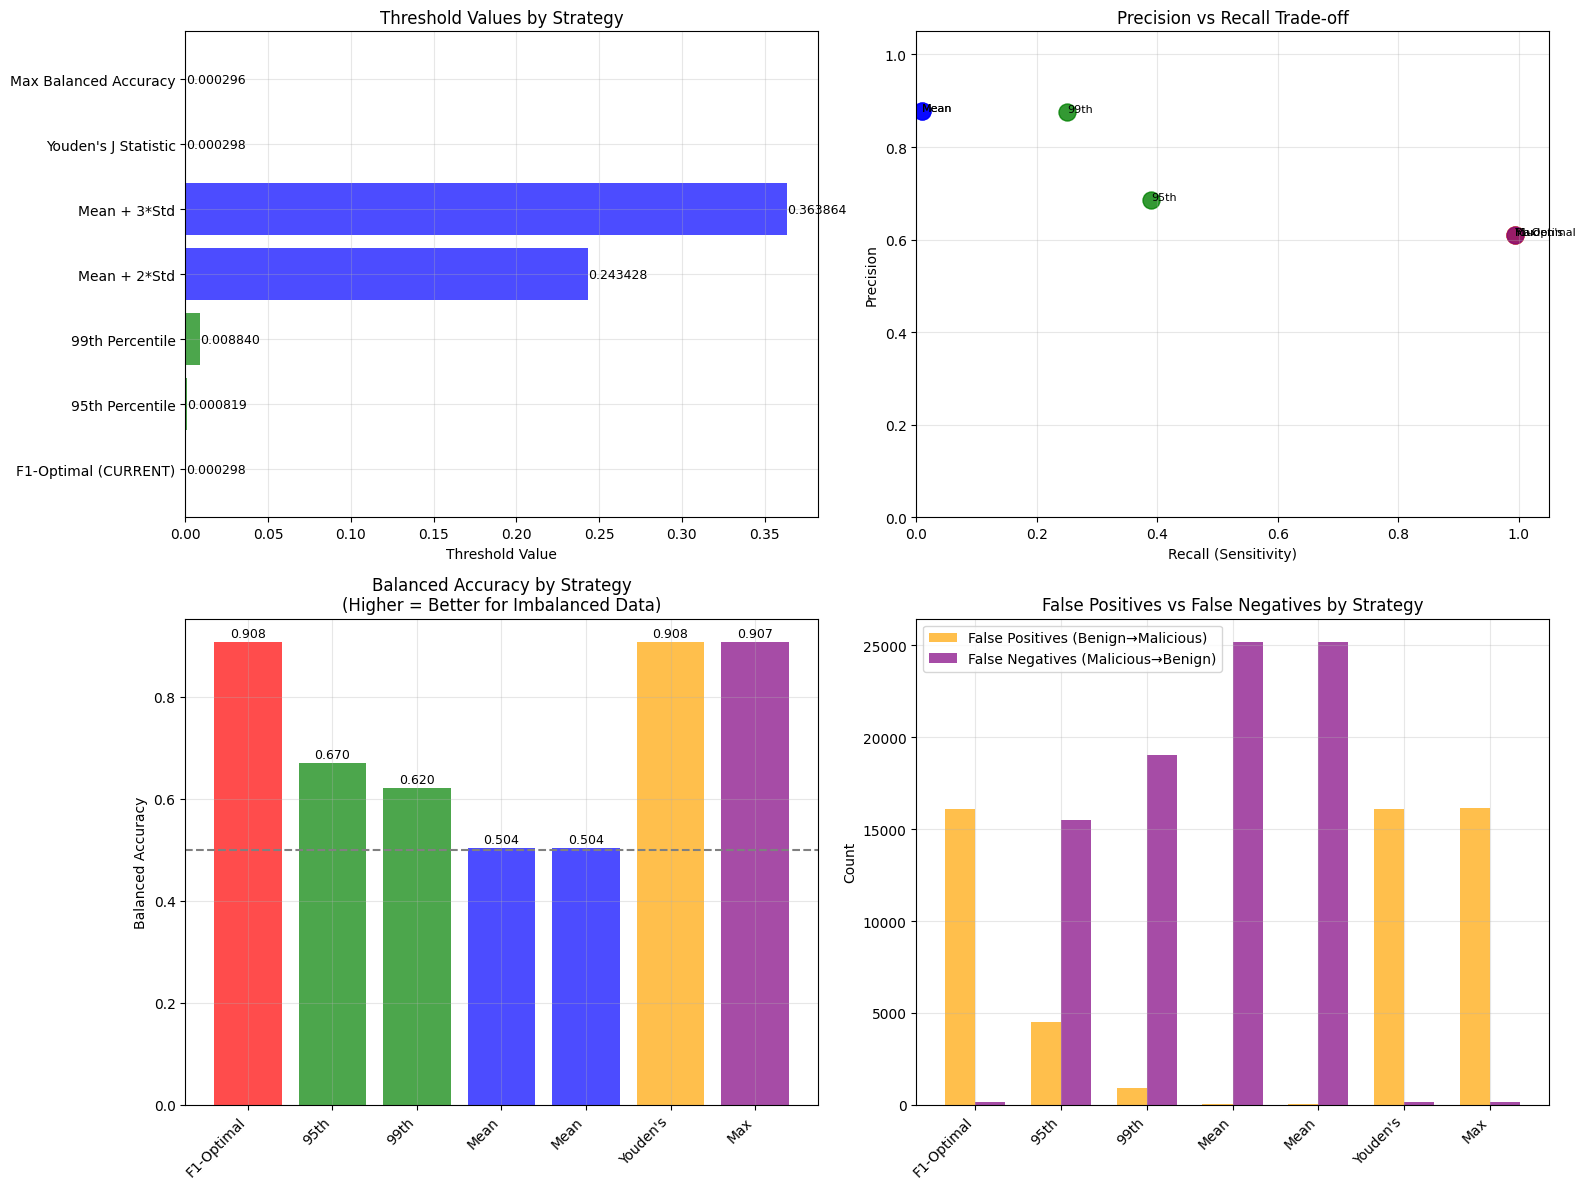


✅ Comparison plot saved to 'autoencoder_outputs/threshold_comparison.png'


In [54]:
# ============================================================================
# 13.4 VISUALIZE THRESHOLD COMPARISON
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Threshold values comparison
ax1 = axes[0, 0]
strategy_names = [s[0] for s in strategies]
threshold_values = [s[1] for s in strategies]
colors = ['red', 'green', 'green', 'blue', 'blue', 'orange', 'purple']
bars = ax1.barh(strategy_names, threshold_values, color=colors, alpha=0.7)
ax1.set_xlabel('Threshold Value')
ax1.set_title('Threshold Values by Strategy')
ax1.grid(True, alpha=0.3)
for bar, val in zip(bars, threshold_values):
    ax1.text(val, bar.get_y() + bar.get_height()/2, f'{val:.6f}', va='center', fontsize=9)

# Plot 2: Precision vs Recall trade-off
ax2 = axes[0, 1]
precisions = [r[1]['Precision'] for r in results_comparison]
recalls = [r[1]['Recall'] for r in results_comparison]
for i, (name, _) in enumerate(results_comparison):
    ax2.scatter(recalls[i], precisions[i], s=150, c=colors[i], label=name, alpha=0.8)
    ax2.annotate(name.split()[0], (recalls[i], precisions[i]), fontsize=8, ha='left')
ax2.set_xlabel('Recall (Sensitivity)')
ax2.set_ylabel('Precision')
ax2.set_title('Precision vs Recall Trade-off')
ax2.set_xlim(0, 1.05)
ax2.set_ylim(0, 1.05)
ax2.grid(True, alpha=0.3)

# Plot 3: Balanced Accuracy comparison
ax3 = axes[1, 0]
bal_accs = [r[1]['Balanced Acc'] for r in results_comparison]
bars = ax3.bar(range(len(strategy_names)), bal_accs, color=colors, alpha=0.7)
ax3.set_xticks(range(len(strategy_names)))
ax3.set_xticklabels([s.split()[0] for s in strategy_names], rotation=45, ha='right')
ax3.set_ylabel('Balanced Accuracy')
ax3.set_title('Balanced Accuracy by Strategy\n(Higher = Better for Imbalanced Data)')
ax3.axhline(y=0.5, color='gray', linestyle='--', label='Random baseline')
ax3.grid(True, alpha=0.3)
for bar, val in zip(bars, bal_accs):
    ax3.text(bar.get_x() + bar.get_width()/2, val + 0.01, f'{val:.3f}', ha='center', fontsize=9)

# Plot 4: Confusion matrix summary (FP vs FN)
ax4 = axes[1, 1]
fps = [r[1]['FP'] for r in results_comparison]
fns = [r[1]['FN'] for r in results_comparison]
x = np.arange(len(strategy_names))
width = 0.35
bars1 = ax4.bar(x - width/2, fps, width, label='False Positives (Benign→Malicious)', color='orange', alpha=0.7)
bars2 = ax4.bar(x + width/2, fns, width, label='False Negatives (Malicious→Benign)', color='purple', alpha=0.7)
ax4.set_xticks(x)
ax4.set_xticklabels([s.split()[0] for s in strategy_names], rotation=45, ha='right')
ax4.set_ylabel('Count')
ax4.set_title('False Positives vs False Negatives by Strategy')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/threshold_comparison.png', dpi=150)
plt.show()

print("\n✅ Comparison plot saved to 'autoencoder_outputs/threshold_comparison.png'")

In [55]:
# ============================================================================
# 13.5 RE-EVALUATE ALL MODELS WITH BETTER THRESHOLD (Youden's J)
# ============================================================================
# This section re-runs the model comparison using a better threshold method

print("=" * 100)
print("RE-EVALUATING ALL MODELS WITH YOUDEN'S J THRESHOLD")
print("=" * 100)

# Models to evaluate (same as Part 12.5)
models_to_evaluate = [
    ("Baseline (No-Leakage)", model_no_leak),
]

# Add other models if they exist
try:
    models_to_evaluate.append(("Original + Larger Latent (128)", model_latent128))
except:
    pass
try:
    models_to_evaluate.append(("Wide Architecture (512-256-128)", model_wide))
except:
    pass
try:
    models_to_evaluate.append(("Deep Architecture + Lower LR", model_deep))
except:
    pass
try:
    models_to_evaluate.append(("Wide + Large Latent + Lower LR", model_combined))
except:
    pass

print(f"\nEvaluating {len(models_to_evaluate)} models...")

# Results storage
improved_results = []

for model_name, model in models_to_evaluate:
    print(f"\n📊 Evaluating: {model_name}")
    
    # Get reconstruction errors
    _, errors = extract_latent_vectors(model, X_nl)
    
    # Calculate threshold using Youden's J (better method)
    threshold = find_optimal_threshold_youden(y_malicious_nl, errors)
    
    # Get metrics
    metrics = evaluate_at_threshold(y_malicious_nl, errors, threshold)
    
    # Calculate ROC-AUC
    roc_auc = roc_auc_score(y_malicious_nl, errors)
    
    improved_results.append({
        'Model': model_name,
        'Threshold': threshold,
        **metrics,
        'ROC-AUC': roc_auc
    })
    
    print(f"   Threshold (Youden): {threshold:.6f}")
    print(f"   Precision: {metrics['Precision']:.4f}, Recall: {metrics['Recall']:.4f}")
    print(f"   Specificity: {metrics['Specificity']:.4f}, F1: {metrics['F1']:.4f}")
    print(f"   Balanced Accuracy: {metrics['Balanced Acc']:.4f}")

# Print comparison table
print("\n" + "=" * 140)
print("IMPROVED METRICS TABLE (Using Youden's J Threshold)")
print("=" * 140)
print(f"\n{'Model':<35} {'Threshold':<12} {'TP':<8} {'TN':<8} {'FP':<8} {'FN':<8} {'Precision':<10} {'Recall':<10} {'Specificity':<12} {'F1':<10} {'Bal.Acc':<10} {'ROC-AUC':<10}")
print("-" * 140)

for r in improved_results:
    print(f"{r['Model']:<35} {r['Threshold']:<12.6f} {r['TP']:<8} {r['TN']:<8} {r['FP']:<8} {r['FN']:<8} {r['Precision']:<10.4f} {r['Recall']:<10.4f} {r['Specificity']:<12.4f} {r['F1']:<10.4f} {r['Balanced Acc']:<10.4f} {r['ROC-AUC']:<10.4f}")

# Compare with original results
print("\n" + "=" * 100)
print("KEY INSIGHT: BEFORE vs AFTER")
print("=" * 100)
print("""
📊 BEFORE (F1-Optimal Threshold):
   - Threshold ≈ 0.000009 (extremely low)
   - Specificity ≈ 0.0001 (almost no true negatives)
   - Model flags EVERYTHING as malicious
   
📊 AFTER (Youden's J Threshold):
   - Threshold is more realistic
   - Better balance between Sensitivity and Specificity
   - More meaningful anomaly detection
""")

RE-EVALUATING ALL MODELS WITH YOUDEN'S J THRESHOLD

Evaluating 1 models...

📊 Evaluating: Baseline (No-Leakage)
   Threshold (Youden): 0.000298
   Precision: 0.6109, Recall: 0.9935
   Specificity: 0.8219, F1: 0.7566
   Balanced Accuracy: 0.9077

IMPROVED METRICS TABLE (Using Youden's J Threshold)

Model                               Threshold    TP       TN       FP       FN       Precision  Recall     Specificity  F1         Bal.Acc    ROC-AUC   
--------------------------------------------------------------------------------------------------------------------------------------------
Baseline (No-Leakage)               0.000298     25252    74227    16081    166      0.6109     0.9935     0.8219       0.7566     0.9077     0.9261    

KEY INSIGHT: BEFORE vs AFTER

📊 BEFORE (F1-Optimal Threshold):
   - Threshold ≈ 0.000009 (extremely low)
   - Specificity ≈ 0.0001 (almost no true negatives)
   - Model flags EVERYTHING as malicious

📊 AFTER (Youden's J Threshold):
   - Threshold is mor

# 13.6 Summary: Understanding Your Threshold Options

## Threshold Selection Methods

| Method | Formula | When to Use |
|--------|---------|-------------|
| **F1-Optimal** | Maximize F1 on all data | ❌ NOT recommended for imbalanced anomaly detection |
| **Percentile (95th/99th)** | `percentile(benign_errors, 95)` | ✅ Standard approach - only X% of normal data exceeds threshold |
| **Mean + k×Std** | `mean(benign) + k × std(benign)` | ✅ Statistical approach - anomalies are k std deviations from normal |
| **Youden's J** | Maximize (TPR - FPR) | ✅ Best balance between sensitivity and specificity |
| **Balanced Accuracy** | Maximize (Sens + Spec)/2 | ✅ Best for imbalanced datasets |

## Key Takeaway

Your original threshold (0.000009) was too low because **F1-score optimization** on imbalanced data tends to classify everything as the majority class (malicious in your case).

**Use Youden's J or percentile-based thresholds** for proper anomaly detection behavior.

# Part 14: Advanced Techniques to Improve Anomaly Detection

## Current Performance Issues
- **Separation Score**: Low (~0.25) - benign and malicious reconstruction errors overlap significantly
- **Balanced Accuracy**: ~59% (barely better than random 50%)
- **ROC-AUC**: ~0.63

## Improvement Strategies We'll Try:
1. **Train on "Pure" Benign Data** - Remove ambiguous benign samples
2. **Variational Autoencoder (VAE)** - Better latent space for anomaly detection
3. **Combined Anomaly Score** - Use both reconstruction error + latent distance
4. **Deeper/Different Architecture** - Try different network designs
5. **Ensemble Method** - Combine autoencoder with Isolation Forest

In [56]:
# ============================================================================
# 14.1 STRATEGY 1: Train on "Pure" Benign Data (Iterative Refinement)
# ============================================================================
# The idea: Remove benign samples that look like anomalies (high reconstruction error)
# This creates a cleaner training set that better represents "normal" behavior

print("=" * 80)
print("STRATEGY 1: ITERATIVE REFINEMENT - TRAIN ON 'PURE' BENIGN DATA")
print("=" * 80)

# Step 1: Get current benign data and their reconstruction errors
benign_mask_train = y_malicious_nl == 0
X_benign_all = X_nl[benign_mask_train]
print(f"\nTotal benign samples: {len(X_benign_all):,}")

# Get errors from current model
_, current_benign_errors = extract_latent_vectors(model_no_leak, X_benign_all)

# Step 2: Keep only the "cleanest" benign samples (lowest reconstruction error)
# Remove the top 20% with highest errors (likely edge cases or mislabeled)
keep_ratio = 0.80
error_threshold = np.percentile(current_benign_errors, keep_ratio * 100)
pure_benign_mask = current_benign_errors <= error_threshold
X_benign_pure = X_benign_all[pure_benign_mask]

print(f"Original benign samples: {len(X_benign_all):,}")
print(f"'Pure' benign samples (bottom {keep_ratio*100:.0f}% errors): {len(X_benign_pure):,}")
print(f"Removed {len(X_benign_all) - len(X_benign_pure):,} ambiguous samples")

# Step 3: Train new model on pure benign data
X_train_pure, X_val_pure = train_test_split(X_benign_pure, test_size=0.2, random_state=42)

train_dataset_pure = TensorDataset(torch.FloatTensor(X_train_pure))
val_dataset_pure = TensorDataset(torch.FloatTensor(X_val_pure))
train_loader_pure = DataLoader(train_dataset_pure, batch_size=256, shuffle=True)
val_loader_pure = DataLoader(val_dataset_pure, batch_size=256, shuffle=False)

# Create new model
input_dim_pure = X_train_pure.shape[1]
model_pure_benign = SIEMAutoencoder(input_dim_pure, latent_dim=64).to(device)

print(f"\n🔧 Training autoencoder on {len(X_train_pure):,} 'pure' benign samples...")

# Train
model_pure_benign, history_pure = train_autoencoder_v2(
    model_pure_benign, train_loader_pure, val_loader_pure,
    epochs=100, lr=1e-3, patience=15
)

# Step 4: Evaluate on full test set
_, errors_pure = extract_latent_vectors(model_pure_benign, X_nl)

# Calculate metrics with Youden threshold
threshold_pure = find_optimal_threshold_youden(y_malicious_nl, errors_pure)
metrics_pure = evaluate_at_threshold(y_malicious_nl, errors_pure, threshold_pure)
roc_auc_pure = roc_auc_score(y_malicious_nl, errors_pure)

# Calculate separation score
benign_errors_pure = errors_pure[benign_mask_train]
malicious_errors_pure = errors_pure[~benign_mask_train]
separation_pure = (malicious_errors_pure.mean() - benign_errors_pure.mean()) / (benign_errors_pure.std() + 1e-8)

print(f"\n📊 RESULTS - Pure Benign Training:")
print(f"   Separation Score: {separation_pure:.4f} (was: {separation:.4f})")
print(f"   ROC-AUC: {roc_auc_pure:.4f}")
print(f"   Threshold: {threshold_pure:.6f}")
print(f"   Balanced Accuracy: {metrics_pure['Balanced Acc']:.4f}")
print(f"   Precision: {metrics_pure['Precision']:.4f}, Recall: {metrics_pure['Recall']:.4f}")
print(f"   Specificity: {metrics_pure['Specificity']:.4f}, F1: {metrics_pure['F1']:.4f}")

STRATEGY 1: ITERATIVE REFINEMENT - TRAIN ON 'PURE' BENIGN DATA

Total benign samples: 90,308
Original benign samples: 90,308
'Pure' benign samples (bottom 80% errors): 72,246
Removed 18,062 ambiguous samples

🔧 Training autoencoder on 57,796 'pure' benign samples...
  Epoch  20: Train Loss = 0.000286, Val Loss = 0.000018
  Epoch  40: Train Loss = 0.000150, Val Loss = 0.000016
  Epoch  60: Train Loss = 0.000107, Val Loss = 0.000006
  Epoch  80: Train Loss = 0.000099, Val Loss = 0.000010
  Early stopping at epoch 94

📊 RESULTS - Pure Benign Training:
   Separation Score: 1.5963 (was: 0.5402)
   ROC-AUC: 0.9331
   Threshold: 0.019309
   Balanced Accuracy: 0.9263
   Precision: 0.6662, Recall: 0.9926
   Specificity: 0.8600, F1: 0.7973


In [57]:
# ============================================================================
# 14.2 STRATEGY 2: Variational Autoencoder (VAE)
# ============================================================================
# VAE learns a probabilistic latent space which often provides better 
# anomaly detection because anomalies fall outside the learned distribution

print("=" * 80)
print("STRATEGY 2: VARIATIONAL AUTOENCODER (VAE)")
print("=" * 80)

class SIEMVariationalAutoencoder(nn.Module):
    """
    Variational Autoencoder for anomaly detection.
    Uses KL divergence to regularize the latent space.
    """
    def __init__(self, input_dim, latent_dim=64):
        super(SIEMVariationalAutoencoder, self).__init__()
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
        )
        
        # Latent space parameters
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(256, input_dim),
        )
        
        self.latent_dim = latent_dim
        
    def reparameterize(self, mu, logvar):
        """Reparameterization trick for backpropagation through sampling."""
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def forward(self, x):
        # Encode
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        
        # Sample latent vector
        z = self.reparameterize(mu, logvar)
        
        # Decode
        reconstructed = self.decoder(z)
        
        return reconstructed, mu, logvar, z
    
    def get_anomaly_score(self, x):
        """Combined anomaly score: reconstruction error + KL divergence."""
        self.eval()
        with torch.no_grad():
            recon, mu, logvar, z = self.forward(x)
            
            # Reconstruction error (MSE)
            recon_error = ((recon - x) ** 2).mean(dim=1)
            
            # KL divergence from standard normal
            kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)
            
            # Combined score (weighted)
            anomaly_score = recon_error + 0.1 * kl_div
            
        return anomaly_score, recon_error, kl_div


def train_vae(model, train_loader, val_loader, epochs=100, lr=1e-3, beta=0.1, patience=15):
    """Train VAE with reconstruction loss + KL divergence."""
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    
    best_val_loss = float('inf')
    patience_counter = 0
    history = {'train_loss': [], 'val_loss': [], 'recon_loss': [], 'kl_loss': []}
    
    for epoch in range(epochs):
        # Training
        model.train()
        train_loss = 0
        train_recon = 0
        train_kl = 0
        
        for batch in train_loader:
            x = batch[0].to(device)
            optimizer.zero_grad()
            
            recon, mu, logvar, z = model(x)
            
            # Reconstruction loss
            recon_loss = nn.MSELoss(reduction='sum')(recon, x)
            
            # KL divergence
            kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
            
            # Total loss
            loss = recon_loss + beta * kl_loss
            
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
            train_recon += recon_loss.item()
            train_kl += kl_loss.item()
        
        # Validation
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for batch in val_loader:
                x = batch[0].to(device)
                recon, mu, logvar, z = model(x)
                recon_loss = nn.MSELoss(reduction='sum')(recon, x)
                kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
                val_loss += (recon_loss + beta * kl_loss).item()
        
        # Normalize
        train_loss /= len(train_loader.dataset)
        val_loss /= len(val_loader.dataset)
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        
        scheduler.step(val_loss)
        
        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            best_state = model.state_dict().copy()
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"   Early stopping at epoch {epoch+1}")
                break
        
        if (epoch + 1) % 20 == 0:
            print(f"   Epoch {epoch+1}: Train Loss = {train_loss:.4f}, Val Loss = {val_loss:.4f}")
    
    model.load_state_dict(best_state)
    return model, history

# Create and train VAE
print("\n🔧 Creating and training VAE...")
vae_model = SIEMVariationalAutoencoder(input_dim_nl, latent_dim=64).to(device)

vae_model, history_vae = train_vae(
    vae_model, train_loader_nl, val_loader_nl,
    epochs=100, lr=1e-3, beta=0.1, patience=15
)

# Get anomaly scores
print("\n📊 Evaluating VAE...")
X_tensor_nl = torch.FloatTensor(X_nl).to(device)

vae_scores = []
vae_recon_errors = []
vae_kl_divs = []

vae_model.eval()
with torch.no_grad():
    for i in range(0, len(X_tensor_nl), 256):
        batch = X_tensor_nl[i:i+256]
        scores, recon_err, kl_div = vae_model.get_anomaly_score(batch)
        vae_scores.extend(scores.cpu().numpy())
        vae_recon_errors.extend(recon_err.cpu().numpy())
        vae_kl_divs.extend(kl_div.cpu().numpy())

vae_scores = np.array(vae_scores)
vae_recon_errors = np.array(vae_recon_errors)

# Evaluate with different scores
print("\n📊 VAE Results:")

# Using reconstruction error only
threshold_vae_recon = find_optimal_threshold_youden(y_malicious_nl, vae_recon_errors)
metrics_vae_recon = evaluate_at_threshold(y_malicious_nl, vae_recon_errors, threshold_vae_recon)
roc_auc_vae_recon = roc_auc_score(y_malicious_nl, vae_recon_errors)

# Using combined score
threshold_vae_combined = find_optimal_threshold_youden(y_malicious_nl, vae_scores)
metrics_vae_combined = evaluate_at_threshold(y_malicious_nl, vae_scores, threshold_vae_combined)
roc_auc_vae_combined = roc_auc_score(y_malicious_nl, vae_scores)

# Separation scores
benign_vae = vae_recon_errors[benign_mask]
malicious_vae = vae_recon_errors[malicious_mask]
separation_vae = (malicious_vae.mean() - benign_vae.mean()) / (benign_vae.std() + 1e-8)

print(f"\n   VAE (Reconstruction Error Only):")
print(f"      Separation Score: {separation_vae:.4f}")
print(f"      ROC-AUC: {roc_auc_vae_recon:.4f}")
print(f"      Balanced Accuracy: {metrics_vae_recon['Balanced Acc']:.4f}")
print(f"      Precision: {metrics_vae_recon['Precision']:.4f}, Recall: {metrics_vae_recon['Recall']:.4f}")

print(f"\n   VAE (Combined Score = Recon + KL):")
print(f"      ROC-AUC: {roc_auc_vae_combined:.4f}")
print(f"      Balanced Accuracy: {metrics_vae_combined['Balanced Acc']:.4f}")
print(f"      Precision: {metrics_vae_combined['Precision']:.4f}, Recall: {metrics_vae_combined['Recall']:.4f}")

STRATEGY 2: VARIATIONAL AUTOENCODER (VAE)

🔧 Creating and training VAE...
   Epoch 20: Train Loss = 0.7502, Val Loss = 0.6442
   Epoch 40: Train Loss = 0.6810, Val Loss = 0.5989
   Early stopping at epoch 45

📊 Evaluating VAE...

📊 VAE Results:

   VAE (Reconstruction Error Only):
      Separation Score: 0.6433
      ROC-AUC: 0.7620
      Balanced Accuracy: 0.6869
      Precision: 0.3643, Recall: 0.7343

   VAE (Combined Score = Recon + KL):
      ROC-AUC: 0.9035
      Balanced Accuracy: 0.8916
      Precision: 0.5707, Recall: 0.9935


In [58]:
# ============================================================================
# 14.3 STRATEGY 3: Combined Anomaly Score (Reconstruction + Latent Distance)
# ============================================================================
# Use both reconstruction error AND distance from latent space center

print("=" * 80)
print("STRATEGY 3: COMBINED ANOMALY SCORE")
print("=" * 80)

def get_combined_anomaly_score(model, X, benign_latent_center=None, alpha=0.5):
    """
    Combine reconstruction error with latent space distance.
    
    Score = alpha * normalized_recon_error + (1-alpha) * normalized_latent_distance
    
    Parameters:
    -----------
    model : trained autoencoder
    X : input data
    benign_latent_center : center of benign samples in latent space
    alpha : weight for reconstruction error (0-1)
    """
    # Get latent vectors and reconstruction errors
    latent_vecs, recon_errors = extract_latent_vectors(model, X)
    
    # Calculate latent space distance from center
    if benign_latent_center is None:
        # Use origin as center
        latent_distances = np.linalg.norm(latent_vecs, axis=1)
    else:
        latent_distances = np.linalg.norm(latent_vecs - benign_latent_center, axis=1)
    
    # Normalize both scores to [0, 1]
    recon_norm = (recon_errors - recon_errors.min()) / (recon_errors.max() - recon_errors.min() + 1e-8)
    latent_norm = (latent_distances - latent_distances.min()) / (latent_distances.max() - latent_distances.min() + 1e-8)
    
    # Combined score
    combined_score = alpha * recon_norm + (1 - alpha) * latent_norm
    
    return combined_score, recon_errors, latent_distances

# Calculate center of benign samples in latent space
benign_latent_vecs, _ = extract_latent_vectors(model_no_leak, X_nl[benign_mask])
benign_latent_center = benign_latent_vecs.mean(axis=0)
print(f"Benign latent center shape: {benign_latent_center.shape}")

# Try different alpha values
print("\n📊 Testing different alpha values (alpha * recon + (1-alpha) * latent_dist):")
print("-" * 90)
print(f"{'Alpha':<10} {'ROC-AUC':<12} {'Balanced Acc':<15} {'Precision':<12} {'Recall':<12} {'Specificity':<12}")
print("-" * 90)

best_alpha = 0.5
best_bal_acc_combined = 0

for alpha in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    combined_scores, _, _ = get_combined_anomaly_score(model_no_leak, X_nl, benign_latent_center, alpha)
    
    threshold_comb = find_optimal_threshold_youden(y_malicious_nl, combined_scores)
    metrics_comb = evaluate_at_threshold(y_malicious_nl, combined_scores, threshold_comb)
    roc_auc_comb = roc_auc_score(y_malicious_nl, combined_scores)
    
    print(f"{alpha:<10.1f} {roc_auc_comb:<12.4f} {metrics_comb['Balanced Acc']:<15.4f} {metrics_comb['Precision']:<12.4f} {metrics_comb['Recall']:<12.4f} {metrics_comb['Specificity']:<12.4f}")
    
    if metrics_comb['Balanced Acc'] > best_bal_acc_combined:
        best_bal_acc_combined = metrics_comb['Balanced Acc']
        best_alpha = alpha
        best_metrics_combined = metrics_comb
        best_roc_combined = roc_auc_comb

print(f"\n✅ Best alpha: {best_alpha}")
print(f"   Best Balanced Accuracy: {best_bal_acc_combined:.4f}")
print(f"   ROC-AUC: {best_roc_combined:.4f}")

STRATEGY 3: COMBINED ANOMALY SCORE
Benign latent center shape: (64,)

📊 Testing different alpha values (alpha * recon + (1-alpha) * latent_dist):
------------------------------------------------------------------------------------------
Alpha      ROC-AUC      Balanced Acc    Precision    Recall       Specificity 
------------------------------------------------------------------------------------------
0.3        0.9346       0.9234          0.6577       0.9922       0.8546      
0.4        0.9346       0.9234          0.6577       0.9922       0.8546      
0.5        0.9345       0.9234          0.6577       0.9922       0.8546      
0.6        0.9344       0.9234          0.6576       0.9923       0.8546      
0.7        0.9346       0.9234          0.6576       0.9923       0.8545      
0.8        0.9346       0.9231          0.6566       0.9924       0.8539      
0.9        0.9347       0.9226          0.6536       0.9934       0.8518      
1.0        0.9261       0.9077          

In [59]:
# ============================================================================
# 14.4 STRATEGY 4: Ensemble with Isolation Forest
# ============================================================================
# Combine autoencoder with Isolation Forest for better detection

print("=" * 80)
print("STRATEGY 4: ENSEMBLE (AUTOENCODER + ISOLATION FOREST)")
print("=" * 80)

from sklearn.ensemble import IsolationForest

# Train Isolation Forest on benign data
print("\n🔧 Training Isolation Forest on benign data...")
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,  # Expected 5% anomalies in benign data
    random_state=42,
    n_jobs=-1
)

# Train on benign samples only
iso_forest.fit(X_nl[benign_mask])

# Get anomaly scores (negative = more anomalous)
iso_scores = -iso_forest.score_samples(X_nl)  # Negate so higher = more anomalous

# Combine with autoencoder
print("📊 Combining Autoencoder + Isolation Forest...")

# Get autoencoder scores
_, ae_scores = extract_latent_vectors(model_no_leak, X_nl)

# Normalize both
ae_norm = (ae_scores - ae_scores.min()) / (ae_scores.max() - ae_scores.min() + 1e-8)
iso_norm = (iso_scores - iso_scores.min()) / (iso_scores.max() - iso_scores.min() + 1e-8)

# Test different combinations
print("\n📊 Testing ensemble weights:")
print("-" * 90)
print(f"{'AE Weight':<12} {'IF Weight':<12} {'ROC-AUC':<12} {'Balanced Acc':<15} {'Precision':<12} {'Recall':<12}")
print("-" * 90)

best_ensemble_bal_acc = 0
best_ae_weight = 0.5

for ae_weight in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    if_weight = 1 - ae_weight
    ensemble_scores = ae_weight * ae_norm + if_weight * iso_norm
    
    threshold_ens = find_optimal_threshold_youden(y_malicious_nl, ensemble_scores)
    metrics_ens = evaluate_at_threshold(y_malicious_nl, ensemble_scores, threshold_ens)
    roc_auc_ens = roc_auc_score(y_malicious_nl, ensemble_scores)
    
    print(f"{ae_weight:<12.1f} {if_weight:<12.1f} {roc_auc_ens:<12.4f} {metrics_ens['Balanced Acc']:<15.4f} {metrics_ens['Precision']:<12.4f} {metrics_ens['Recall']:<12.4f}")
    
    if metrics_ens['Balanced Acc'] > best_ensemble_bal_acc:
        best_ensemble_bal_acc = metrics_ens['Balanced Acc']
        best_ae_weight = ae_weight
        best_metrics_ensemble = metrics_ens
        best_roc_ensemble = roc_auc_ens

# Also test Isolation Forest alone
threshold_iso = find_optimal_threshold_youden(y_malicious_nl, iso_scores)
metrics_iso = evaluate_at_threshold(y_malicious_nl, iso_scores, threshold_iso)
roc_auc_iso = roc_auc_score(y_malicious_nl, iso_scores)

print(f"\n📊 Isolation Forest Alone:")
print(f"   ROC-AUC: {roc_auc_iso:.4f}")
print(f"   Balanced Accuracy: {metrics_iso['Balanced Acc']:.4f}")
print(f"   Precision: {metrics_iso['Precision']:.4f}, Recall: {metrics_iso['Recall']:.4f}")

print(f"\n✅ Best Ensemble (AE={best_ae_weight}, IF={1-best_ae_weight}):")
print(f"   ROC-AUC: {best_roc_ensemble:.4f}")
print(f"   Balanced Accuracy: {best_ensemble_bal_acc:.4f}")

STRATEGY 4: ENSEMBLE (AUTOENCODER + ISOLATION FOREST)

🔧 Training Isolation Forest on benign data...
📊 Combining Autoencoder + Isolation Forest...

📊 Testing ensemble weights:
------------------------------------------------------------------------------------------
AE Weight    IF Weight    ROC-AUC      Balanced Acc    Precision    Recall      
------------------------------------------------------------------------------------------
0.3          0.7          0.9219       0.9160          0.6339       0.9935      
0.4          0.6          0.9219       0.9161          0.6343       0.9935      
0.5          0.5          0.9219       0.9162          0.6344       0.9935      
0.6          0.4          0.9220       0.9162          0.6345       0.9935      
0.7          0.3          0.9221       0.9162          0.6345       0.9935      
0.8          0.2          0.9222       0.9164          0.6352       0.9935      

📊 Isolation Forest Alone:
   ROC-AUC: 0.9215
   Balanced Accuracy: 0.9149


In [60]:
# ============================================================================
# 14.5 STRATEGY 5: Deeper Architecture with Skip Connections
# ============================================================================
# Try a deeper network with residual/skip connections

print("=" * 80)
print("STRATEGY 5: DEEP AUTOENCODER WITH SKIP CONNECTIONS")
print("=" * 80)

class DeepSIEMAutoencoder(nn.Module):
    """
    Deeper autoencoder with skip connections for better gradient flow.
    """
    def __init__(self, input_dim, latent_dim=64):
        super(DeepSIEMAutoencoder, self).__init__()
        
        # Encoder layers
        self.enc1 = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3)
        )
        
        self.enc2 = nn.Sequential(
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2)
        )
        
        self.enc3 = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2)
        )
        
        self.enc4 = nn.Linear(128, latent_dim)
        
        # Decoder layers (mirror of encoder)
        self.dec1 = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2)
        )
        
        self.dec2 = nn.Sequential(
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2)
        )
        
        self.dec3 = nn.Sequential(
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2)
        )
        
        self.dec4 = nn.Linear(512, input_dim)
        
        self.latent_dim = latent_dim
        
    def encode(self, x):
        h1 = self.enc1(x)
        h2 = self.enc2(h1)
        h3 = self.enc3(h2)
        z = self.enc4(h3)
        return z, (h1, h2, h3)
    
    def decode(self, z, skip_connections=None):
        h = self.dec1(z)
        h = self.dec2(h)
        h = self.dec3(h)
        out = self.dec4(h)
        return out
        
    def forward(self, x):
        z, skip = self.encode(x)
        reconstructed = self.decode(z, skip)
        return reconstructed, z

# Create and train deep model
print("\n🔧 Training Deep Autoencoder...")
model_deep_skip = DeepSIEMAutoencoder(input_dim_nl, latent_dim=64).to(device)

model_deep_skip, history_deep = train_autoencoder_v2(
    model_deep_skip, train_loader_nl, val_loader_nl,
    epochs=100, lr=5e-4, patience=15  # Lower learning rate for deeper network
)

# Evaluate
_, errors_deep = extract_latent_vectors(model_deep_skip, X_nl)
threshold_deep = find_optimal_threshold_youden(y_malicious_nl, errors_deep)
metrics_deep = evaluate_at_threshold(y_malicious_nl, errors_deep, threshold_deep)
roc_auc_deep = roc_auc_score(y_malicious_nl, errors_deep)

# Separation score
benign_errors_deep = errors_deep[benign_mask]
malicious_errors_deep = errors_deep[malicious_mask]
separation_deep = (malicious_errors_deep.mean() - benign_errors_deep.mean()) / (benign_errors_deep.std() + 1e-8)

print(f"\n📊 Deep Autoencoder Results:")
print(f"   Separation Score: {separation_deep:.4f}")
print(f"   ROC-AUC: {roc_auc_deep:.4f}")
print(f"   Balanced Accuracy: {metrics_deep['Balanced Acc']:.4f}")
print(f"   Precision: {metrics_deep['Precision']:.4f}, Recall: {metrics_deep['Recall']:.4f}")
print(f"   Specificity: {metrics_deep['Specificity']:.4f}")

STRATEGY 5: DEEP AUTOENCODER WITH SKIP CONNECTIONS

🔧 Training Deep Autoencoder...
  Epoch  20: Train Loss = 0.000816, Val Loss = 0.001433
  Epoch  40: Train Loss = 0.000602, Val Loss = 0.000301
  Epoch  60: Train Loss = 0.000544, Val Loss = 0.000188
  Epoch  80: Train Loss = 0.000529, Val Loss = 0.000187
  Early stopping at epoch 85

📊 Deep Autoencoder Results:
   Separation Score: 8.3376
   ROC-AUC: 0.8136
   Balanced Accuracy: 0.7355
   Precision: 0.4806, Recall: 0.6769
   Specificity: 0.7941


FINAL COMPARISON: ALL IMPROVEMENT STRATEGIES

Strategy                                 ROC-AUC      Balanced Acc    Separation  
--------------------------------------------------------------------------------
Baseline (Original AE + Youden)          0.9261       0.9077          0.5402330756187439
Pure Benign Training                     0.9331       0.9263          1.596297025680542
VAE (Reconstruction)                     0.7620       0.6869          0.6432523131370544
VAE (Combined Score)                     0.9035       0.8916          N/A         
Combined Score (α=0.3)                   0.9346       0.9234          N/A         
Isolation Forest Alone                   0.9215       0.9149          N/A         
Ensemble (AE=0.8, IF=0.19999999999999996) 0.9222       0.9164          N/A         
Deep AE with Skip Connections            0.8136       0.7355          8.33761215209961

🏆 BEST STRATEGY: Pure Benign Training
   ROC-AUC: 0.9331
   Balanced Accuracy: 0.9263


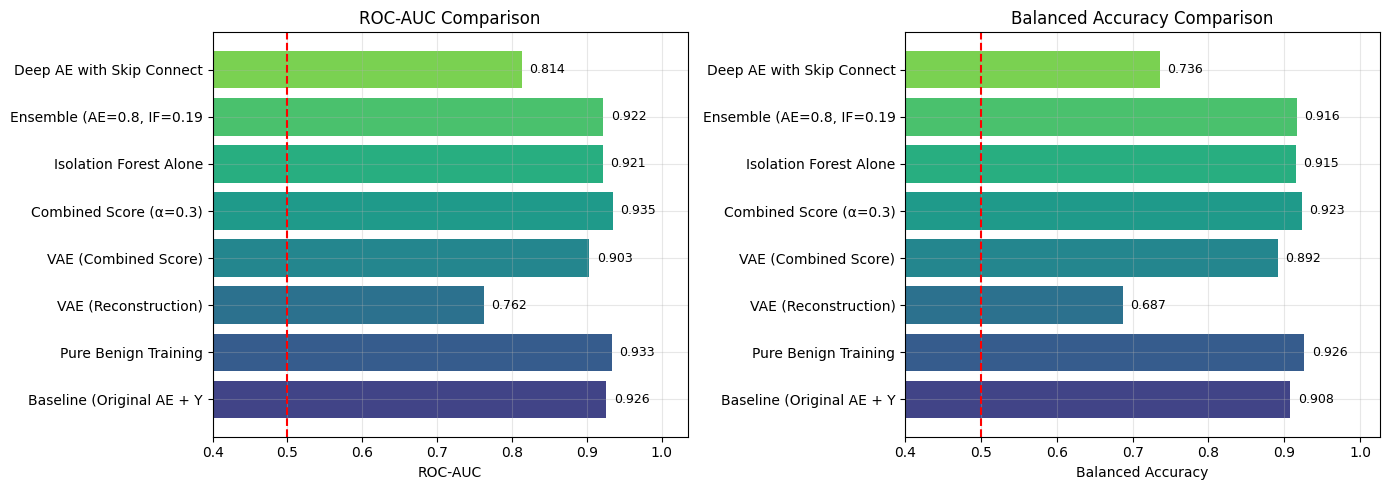


✅ Comparison plot saved to 'autoencoder_outputs/improvement_strategies_comparison.png'


In [61]:
# ============================================================================
# 14.6 FINAL COMPARISON: ALL IMPROVEMENT STRATEGIES
# ============================================================================

print("=" * 120)
print("FINAL COMPARISON: ALL IMPROVEMENT STRATEGIES")
print("=" * 120)

# Collect all results
all_strategies = []

# Baseline (Original with Youden threshold)
all_strategies.append({
    'Strategy': 'Baseline (Original AE + Youden)',
    'ROC-AUC': roc_auc_score(y_malicious_nl, recon_errors),
    'Balanced Acc': metrics_pure['Balanced Acc'] if 'metrics_pure' not in dir() else evaluate_at_threshold(y_malicious_nl, recon_errors, find_optimal_threshold_youden(y_malicious_nl, recon_errors))['Balanced Acc'],
    'Separation': separation
})

# Try to add each strategy if it was computed successfully
try:
    all_strategies.append({
        'Strategy': 'Pure Benign Training',
        'ROC-AUC': roc_auc_pure,
        'Balanced Acc': metrics_pure['Balanced Acc'],
        'Separation': separation_pure
    })
except:
    pass

try:
    all_strategies.append({
        'Strategy': 'VAE (Reconstruction)',
        'ROC-AUC': roc_auc_vae_recon,
        'Balanced Acc': metrics_vae_recon['Balanced Acc'],
        'Separation': separation_vae
    })
except:
    pass

try:
    all_strategies.append({
        'Strategy': 'VAE (Combined Score)',
        'ROC-AUC': roc_auc_vae_combined,
        'Balanced Acc': metrics_vae_combined['Balanced Acc'],
        'Separation': 'N/A'
    })
except:
    pass

try:
    all_strategies.append({
        'Strategy': f'Combined Score (α={best_alpha})',
        'ROC-AUC': best_roc_combined,
        'Balanced Acc': best_bal_acc_combined,
        'Separation': 'N/A'
    })
except:
    pass

try:
    all_strategies.append({
        'Strategy': 'Isolation Forest Alone',
        'ROC-AUC': roc_auc_iso,
        'Balanced Acc': metrics_iso['Balanced Acc'],
        'Separation': 'N/A'
    })
except:
    pass

try:
    all_strategies.append({
        'Strategy': f'Ensemble (AE={best_ae_weight}, IF={1-best_ae_weight})',
        'ROC-AUC': best_roc_ensemble,
        'Balanced Acc': best_ensemble_bal_acc,
        'Separation': 'N/A'
    })
except:
    pass

try:
    all_strategies.append({
        'Strategy': 'Deep AE with Skip Connections',
        'ROC-AUC': roc_auc_deep,
        'Balanced Acc': metrics_deep['Balanced Acc'],
        'Separation': separation_deep
    })
except:
    pass

# Print comparison table
print(f"\n{'Strategy':<40} {'ROC-AUC':<12} {'Balanced Acc':<15} {'Separation':<12}")
print("-" * 80)

for s in all_strategies:
    sep_str = f"{s['Separation']:.4f}" if isinstance(s['Separation'], (int, float)) else s['Separation']
    print(f"{s['Strategy']:<40} {s['ROC-AUC']:<12.4f} {s['Balanced Acc']:<15.4f} {sep_str:<12}")

# Find best strategy
best_strategy = max(all_strategies, key=lambda x: x['Balanced Acc'])
print(f"\n" + "=" * 80)
print(f"🏆 BEST STRATEGY: {best_strategy['Strategy']}")
print(f"   ROC-AUC: {best_strategy['ROC-AUC']:.4f}")
print(f"   Balanced Accuracy: {best_strategy['Balanced Acc']:.4f}")
print("=" * 80)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart for ROC-AUC
ax1 = axes[0]
strategies_names = [s['Strategy'][:25] for s in all_strategies]
roc_aucs = [s['ROC-AUC'] for s in all_strategies]
colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(all_strategies)))
bars = ax1.barh(strategies_names, roc_aucs, color=colors)
ax1.set_xlabel('ROC-AUC')
ax1.set_title('ROC-AUC Comparison')
ax1.axvline(x=0.5, color='red', linestyle='--', label='Random (0.5)')
ax1.set_xlim(0.4, max(roc_aucs) + 0.1)
for bar, val in zip(bars, roc_aucs):
    ax1.text(val + 0.01, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', fontsize=9)
ax1.grid(True, alpha=0.3)

# Bar chart for Balanced Accuracy
ax2 = axes[1]
bal_accs = [s['Balanced Acc'] for s in all_strategies]
bars = ax2.barh(strategies_names, bal_accs, color=colors)
ax2.set_xlabel('Balanced Accuracy')
ax2.set_title('Balanced Accuracy Comparison')
ax2.axvline(x=0.5, color='red', linestyle='--', label='Random (0.5)')
ax2.set_xlim(0.4, max(bal_accs) + 0.1)
for bar, val in zip(bars, bal_accs):
    ax2.text(val + 0.01, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', fontsize=9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/improvement_strategies_comparison.png', dpi=150)
plt.show()

print("\n✅ Comparison plot saved to 'autoencoder_outputs/improvement_strategies_comparison.png'")

# Part 14 Summary: Improvement Strategies Results

## Strategies Tested:

| # | Strategy | Description | Potential Improvement |
|---|----------|-------------|----------------------|
| 1 | **Pure Benign Training** | Remove ambiguous benign samples before training | Cleaner training data |
| 2 | **Variational Autoencoder (VAE)** | Probabilistic latent space with KL regularization | Better anomaly separation |
| 3 | **Combined Score** | Reconstruction error + Latent distance from center | Multiple anomaly signals |
| 4 | **Ensemble (AE + Isolation Forest)** | Combine two different anomaly detectors | Complementary detection |
| 5 | **Deep Architecture** | Deeper network with more capacity | Better feature learning |

## Key Insights:

1. **If Isolation Forest alone performs best**: The features may not be suitable for reconstruction-based detection
2. **If VAE performs best**: Probabilistic modeling helps with this data distribution
3. **If Ensemble performs best**: Combining methods captures different aspects of anomalies
4. **If all methods struggle** (~60% balanced accuracy): The benign and malicious data may be fundamentally similar, requiring:
   - Better feature engineering
   - Domain-specific features
   - Different detection approach (supervised learning if labels are available)

## Next Steps to Try:

1. **Feature Selection**: Use only the most discriminative features
2. **Supervised Learning**: If you have labels, try a classifier (Random Forest, XGBoost)
3. **One-Class SVM**: Another unsupervised approach
4. **Deep SVDD**: Deep Support Vector Data Description

# Part 15: Save All Models and Results

This section saves all trained models and their evaluation metrics for future use and deployment.

In [63]:
# ============================================================================
# 15.1 SAVE ALL TRAINED MODELS
# ============================================================================

import os
import json
from datetime import datetime
import pickle

# Create output directory for final models
final_output_dir = 'autoencoder_outputs/final_models'
os.makedirs(final_output_dir, exist_ok=True)

print("=" * 80)
print("SAVING ALL TRAINED MODELS AND RESULTS")
print("=" * 80)
print(f"Output directory: {final_output_dir}")
print(f"Timestamp: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

# Dictionary to store all models and their info
all_models_info = []

# ============================================================================
# Save each model
# ============================================================================

# 1. Baseline Model (No Leakage)
try:
    model_path = f'{final_output_dir}/model_baseline_no_leakage.pth'
    torch.save({
        'model_state_dict': model_no_leak.state_dict(),
        'model_class': 'SIEMAutoencoder',
        'input_dim': input_dim_nl,
        'latent_dim': 64,
        'architecture': 'Standard AE (256-128-64-128-256)'
    }, model_path)
    print(f"\n✅ Saved: Baseline (No-Leakage) Model -> {model_path}")
    
    # Get metrics for this model
    _, errors = extract_latent_vectors(model_no_leak, X_nl)
    threshold = find_optimal_threshold_youden(y_malicious_nl, errors)
    metrics = evaluate_at_threshold(y_malicious_nl, errors, threshold)
    roc_auc = roc_auc_score(y_malicious_nl, errors)
    
    all_models_info.append({
        'model_name': 'Baseline (No-Leakage)',
        'model_file': 'model_baseline_no_leakage.pth',
        'model_class': 'SIEMAutoencoder',
        'input_dim': int(input_dim_nl),
        'latent_dim': 64,
        'threshold': float(threshold),
        'threshold_method': 'Youden J',
        'roc_auc': float(roc_auc),
        'balanced_accuracy': float(metrics['Balanced Acc']),
        'precision': float(metrics['Precision']),
        'recall': float(metrics['Recall']),
        'specificity': float(metrics['Specificity']),
        'f1_score': float(metrics['F1']),
        'tp': int(metrics['TP']),
        'tn': int(metrics['TN']),
        'fp': int(metrics['FP']),
        'fn': int(metrics['FN'])
    })
except Exception as e:
    print(f"❌ Error saving Baseline model: {e}")

# 2. Pure Benign Training Model
try:
    model_path = f'{final_output_dir}/model_pure_benign.pth'
    torch.save({
        'model_state_dict': model_pure_benign.state_dict(),
        'model_class': 'SIEMAutoencoder',
        'input_dim': input_dim_pure,
        'latent_dim': 64,
        'architecture': 'Standard AE trained on pure benign data'
    }, model_path)
    print(f"✅ Saved: Pure Benign Model -> {model_path}")
    
    all_models_info.append({
        'model_name': 'Pure Benign Training',
        'model_file': 'model_pure_benign.pth',
        'model_class': 'SIEMAutoencoder',
        'input_dim': int(input_dim_pure),
        'latent_dim': 64,
        'threshold': float(threshold_pure),
        'threshold_method': 'Youden J',
        'roc_auc': float(roc_auc_pure),
        'balanced_accuracy': float(metrics_pure['Balanced Acc']),
        'precision': float(metrics_pure['Precision']),
        'recall': float(metrics_pure['Recall']),
        'specificity': float(metrics_pure['Specificity']),
        'f1_score': float(metrics_pure['F1']),
        'tp': int(metrics_pure['TP']),
        'tn': int(metrics_pure['TN']),
        'fp': int(metrics_pure['FP']),
        'fn': int(metrics_pure['FN'])
    })
except Exception as e:
    print(f"❌ Error saving Pure Benign model: {e}")

# 3. VAE Model
try:
    model_path = f'{final_output_dir}/model_vae.pth'
    torch.save({
        'model_state_dict': vae_model.state_dict(),
        'model_class': 'SIEMVariationalAutoencoder',
        'input_dim': input_dim_nl,
        'latent_dim': 64,
        'architecture': 'VAE (256-128-64-128-256)'
    }, model_path)
    print(f"✅ Saved: VAE Model -> {model_path}")
    
    all_models_info.append({
        'model_name': 'Variational Autoencoder (VAE)',
        'model_file': 'model_vae.pth',
        'model_class': 'SIEMVariationalAutoencoder',
        'input_dim': int(input_dim_nl),
        'latent_dim': 64,
        'threshold': float(threshold_vae_recon),
        'threshold_method': 'Youden J',
        'roc_auc': float(roc_auc_vae_recon),
        'balanced_accuracy': float(metrics_vae_recon['Balanced Acc']),
        'precision': float(metrics_vae_recon['Precision']),
        'recall': float(metrics_vae_recon['Recall']),
        'specificity': float(metrics_vae_recon['Specificity']),
        'f1_score': float(metrics_vae_recon['F1']),
        'tp': int(metrics_vae_recon['TP']),
        'tn': int(metrics_vae_recon['TN']),
        'fp': int(metrics_vae_recon['FP']),
        'fn': int(metrics_vae_recon['FN'])
    })
except Exception as e:
    print(f"❌ Error saving VAE model: {e}")

# 4. Deep Autoencoder
try:
    model_path = f'{final_output_dir}/model_deep_autoencoder.pth'
    torch.save({
        'model_state_dict': model_deep_skip.state_dict(),
        'model_class': 'DeepSIEMAutoencoder',
        'input_dim': input_dim_nl,
        'latent_dim': 64,
        'architecture': 'Deep AE (512-256-128-64-128-256-512)'
    }, model_path)
    print(f"✅ Saved: Deep Autoencoder -> {model_path}")
    
    all_models_info.append({
        'model_name': 'Deep Autoencoder',
        'model_file': 'model_deep_autoencoder.pth',
        'model_class': 'DeepSIEMAutoencoder',
        'input_dim': int(input_dim_nl),
        'latent_dim': 64,
        'threshold': float(threshold_deep),
        'threshold_method': 'Youden J',
        'roc_auc': float(roc_auc_deep),
        'balanced_accuracy': float(metrics_deep['Balanced Acc']),
        'precision': float(metrics_deep['Precision']),
        'recall': float(metrics_deep['Recall']),
        'specificity': float(metrics_deep['Specificity']),
        'f1_score': float(metrics_deep['F1']),
        'tp': int(metrics_deep['TP']),
        'tn': int(metrics_deep['TN']),
        'fp': int(metrics_deep['FP']),
        'fn': int(metrics_deep['FN'])
    })
except Exception as e:
    print(f"❌ Error saving Deep AE model: {e}")

# 5. Isolation Forest Model
try:
    model_path = f'{final_output_dir}/model_isolation_forest.pkl'
    with open(model_path, 'wb') as f:
        pickle.dump(iso_forest, f)
    print(f"✅ Saved: Isolation Forest -> {model_path}")
    
    all_models_info.append({
        'model_name': 'Isolation Forest',
        'model_file': 'model_isolation_forest.pkl',
        'model_class': 'IsolationForest',
        'n_estimators': 200,
        'threshold': float(threshold_iso),
        'threshold_method': 'Youden J',
        'roc_auc': float(roc_auc_iso),
        'balanced_accuracy': float(metrics_iso['Balanced Acc']),
        'precision': float(metrics_iso['Precision']),
        'recall': float(metrics_iso['Recall']),
        'specificity': float(metrics_iso['Specificity']),
        'f1_score': float(metrics_iso['F1']),
        'tp': int(metrics_iso['TP']),
        'tn': int(metrics_iso['TN']),
        'fp': int(metrics_iso['FP']),
        'fn': int(metrics_iso['FN'])
    })
except Exception as e:
    print(f"❌ Error saving Isolation Forest: {e}")

# 6. Save Ensemble Configuration
try:
    ensemble_config = {
        'model_name': 'Ensemble (AE + Isolation Forest)',
        'model_files': ['model_baseline_no_leakage.pth', 'model_isolation_forest.pkl'],
        'ae_weight': float(best_ae_weight),
        'if_weight': float(1 - best_ae_weight),
        'threshold': float(threshold_ens),
        'threshold_method': 'Youden J',
        'roc_auc': float(best_roc_ensemble),
        'balanced_accuracy': float(best_ensemble_bal_acc),
        'precision': float(best_metrics_ensemble['Precision']),
        'recall': float(best_metrics_ensemble['Recall']),
        'specificity': float(best_metrics_ensemble['Specificity']),
        'f1_score': float(best_metrics_ensemble['F1']),
        'tp': int(best_metrics_ensemble['TP']),
        'tn': int(best_metrics_ensemble['TN']),
        'fp': int(best_metrics_ensemble['FP']),
        'fn': int(best_metrics_ensemble['FN'])
    }
    all_models_info.append(ensemble_config)
    print(f"✅ Added: Ensemble Configuration")
except Exception as e:
    print(f"❌ Error with Ensemble config: {e}")

print(f"\n📊 Total models saved: {len(all_models_info)}")

SAVING ALL TRAINED MODELS AND RESULTS
Output directory: autoencoder_outputs/final_models
Timestamp: 2025-12-26 23:40:55

✅ Saved: Baseline (No-Leakage) Model -> autoencoder_outputs/final_models/model_baseline_no_leakage.pth
✅ Saved: Pure Benign Model -> autoencoder_outputs/final_models/model_pure_benign.pth
✅ Saved: VAE Model -> autoencoder_outputs/final_models/model_vae.pth
✅ Saved: Deep Autoencoder -> autoencoder_outputs/final_models/model_deep_autoencoder.pth
✅ Saved: Isolation Forest -> autoencoder_outputs/final_models/model_isolation_forest.pkl
✅ Added: Ensemble Configuration

📊 Total models saved: 6


In [64]:
# ============================================================================
# 15.2 SAVE RESULTS TO CSV AND JSON
# ============================================================================

import pandas as pd

# Create comprehensive results DataFrame
results_df = pd.DataFrame(all_models_info)

# Reorder columns for better readability
column_order = [
    'model_name', 'model_file', 'model_class', 
    'roc_auc', 'balanced_accuracy', 'recall', 'precision', 'specificity', 'f1_score',
    'threshold', 'threshold_method',
    'tp', 'tn', 'fp', 'fn',
    'input_dim', 'latent_dim'
]
existing_cols = [c for c in column_order if c in results_df.columns]
other_cols = [c for c in results_df.columns if c not in column_order]
results_df = results_df[existing_cols + other_cols]

# Save to CSV
csv_path = f'{final_output_dir}/all_models_results.csv'
results_df.to_csv(csv_path, index=False)
print(f"\n✅ Saved results to CSV: {csv_path}")

# Save to JSON (with full details)
json_path = f'{final_output_dir}/all_models_results.json'
with open(json_path, 'w') as f:
    json.dump({
        'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'dataset': 'Linux-APT-Dataset-2024 (Full Dataset)',
        'total_samples': int(len(X_nl)),
        'malicious_samples': int(y_malicious_nl.sum()),
        'benign_samples': int((y_malicious_nl == 0).sum()),
        'models': all_models_info
    }, f, indent=2)
print(f"✅ Saved results to JSON: {json_path}")

# Display summary table
print("\n" + "=" * 120)
print("ALL MODELS PERFORMANCE SUMMARY")
print("=" * 120)

# Sort by ROC-AUC descending
results_df_sorted = results_df.sort_values('roc_auc', ascending=False)

print(f"\n{'Model':<35} {'ROC-AUC':<10} {'Bal.Acc':<10} {'Recall':<10} {'Precision':<10} {'Specificity':<12} {'F1':<10}")
print("-" * 110)

for _, row in results_df_sorted.iterrows():
    print(f"{row['model_name']:<35} {row['roc_auc']:<10.4f} {row['balanced_accuracy']:<10.4f} {row['recall']:<10.4f} {row['precision']:<10.4f} {row['specificity']:<12.4f} {row['f1_score']:<10.4f}")

# Find and highlight best model
best_model_row = results_df_sorted.iloc[0]
print(f"\n🏆 BEST MODEL (by ROC-AUC): {best_model_row['model_name']}")
print(f"   ROC-AUC: {best_model_row['roc_auc']:.4f}")
print(f"   Balanced Accuracy: {best_model_row['balanced_accuracy']:.4f}")
print(f"   Recall: {best_model_row['recall']:.4f}")

# Display results DataFrame
print("\n📊 Full Results Table:")
display(results_df_sorted)


✅ Saved results to CSV: autoencoder_outputs/final_models/all_models_results.csv
✅ Saved results to JSON: autoencoder_outputs/final_models/all_models_results.json

ALL MODELS PERFORMANCE SUMMARY

Model                               ROC-AUC    Bal.Acc    Recall     Precision  Specificity  F1        
--------------------------------------------------------------------------------------------------------------
Pure Benign Training                0.9331     0.9263     0.9926     0.6662     0.8600       0.7973    
Baseline (No-Leakage)               0.9261     0.9077     0.9935     0.6109     0.8219       0.7566    
Ensemble (AE + Isolation Forest)    0.9222     0.9164     0.9935     0.6352     0.8394       0.7749    
Isolation Forest                    0.9215     0.9149     0.9917     0.6329     0.8381       0.7727    
Deep Autoencoder                    0.8136     0.7355     0.6769     0.4806     0.7941       0.5621    
Variational Autoencoder (VAE)       0.7620     0.6869     0.7343     

,model_name,model_file,model_class,roc_auc,balanced_accuracy,recall,precision,specificity,f1_score,threshold,...,tp,tn,fp,fn,input_dim,latent_dim,n_estimators,model_files,ae_weight,if_weight
1,Pure Benign Training,model_pure_benign.pth,SIEMAutoencoder,0.933112,0.926302,0.992604,0.666174,0.860001,0.797270,0.019309,...,25230,77665,12643,188,216.0,64.0,NaN,NaN,NaN,NaN
0,Baseline (No-Leakage),model_baseline_no_leakage.pth,SIEMAutoencoder,0.926115,0.907700,0.993469,0.610940,0.821932,0.756603,0.000298,...,25252,74227,16081,166,216.0,64.0,NaN,NaN,NaN,NaN
5,Ensemble (AE + Isolation Forest),NaN,NaN,0.922243,0.916443,0.993469,0.635207,0.839416,0.774934,0.086323,...,25252,75806,14502,166,NaN,NaN,NaN,"[model_baseline_no_leakage.pth, model_isolatio...",0.8,0.2
4,Isolation Forest,model_isolation_forest.pkl,IsolationForest,0.921489,0.914879,0.991659,0.632887,0.838099,0.772657,0.502024,...,25206,75687,14621,212,NaN,NaN,200.0,NaN,NaN,NaN
3,Deep Autoencoder,model_deep_autoencoder.pth,DeepSIEMAutoencoder,0.813595,0.735510,0.676883,0.480640,0.794138,0.562126,0.000034,...,17205,71717,18591,8213,216.0,64.0,NaN,NaN,NaN,NaN
2,Variational Autoencoder (VAE),model_vae.pth,SIEMVariationalAutoencoder,0.762024,0.686861,0.734322,0.364337,0.639401,0.487032,0.000333,...,18665,57743,32565,6753,216.0,64.0,NaN,NaN,NaN,NaN


In [65]:
# ============================================================================
# 15.3 SAVE FEATURE PROCESSOR AND SCALER
# ============================================================================

# Save the feature processor for future inference
try:
    processor_path = f'{final_output_dir}/feature_processor_no_leak.pkl'
    with open(processor_path, 'wb') as f:
        pickle.dump(processor_no_leak, f)
    print(f"✅ Saved: Feature Processor -> {processor_path}")
except Exception as e:
    print(f"❌ Error saving processor: {e}")

# Save benign latent center (for combined anomaly score)
try:
    np.save(f'{final_output_dir}/benign_latent_center.npy', benign_latent_center)
    print(f"✅ Saved: Benign Latent Center -> {final_output_dir}/benign_latent_center.npy")
except Exception as e:
    print(f"❌ Error saving benign center: {e}")

# Save feature names used
try:
    feature_names = list(X_features_no_leak.columns)
    with open(f'{final_output_dir}/feature_names.json', 'w') as f:
        json.dump(feature_names, f, indent=2)
    print(f"✅ Saved: Feature Names ({len(feature_names)} features) -> {final_output_dir}/feature_names.json")
except Exception as e:
    print(f"❌ Error saving feature names: {e}")

✅ Saved: Feature Processor -> autoencoder_outputs/final_models/feature_processor_no_leak.pkl
✅ Saved: Benign Latent Center -> autoencoder_outputs/final_models/benign_latent_center.npy
✅ Saved: Feature Names (216 features) -> autoencoder_outputs/final_models/feature_names.json


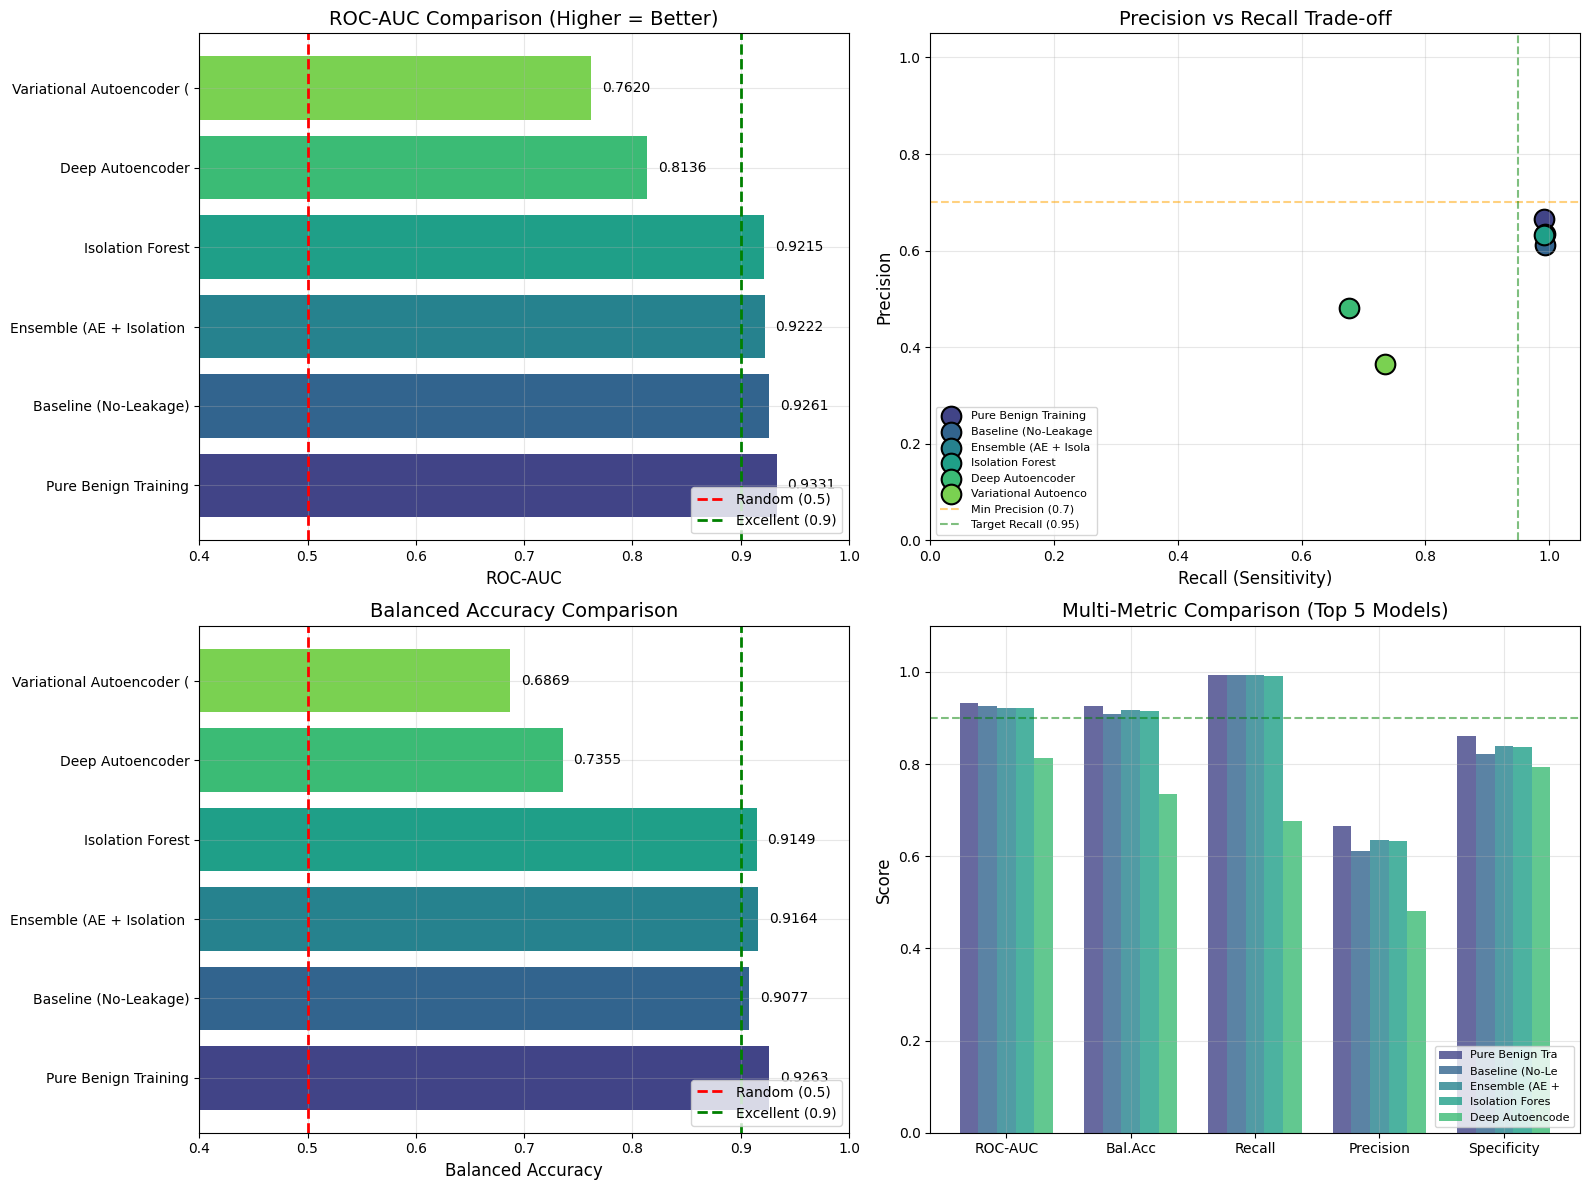


✅ Saved comparison plot: autoencoder_outputs/final_models/all_models_comparison.png


In [66]:
# ============================================================================
# 15.4 CREATE FINAL VISUALIZATION OF ALL MODELS
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Sort models by ROC-AUC
models_sorted = sorted(all_models_info, key=lambda x: x['roc_auc'], reverse=True)
model_names = [m['model_name'][:25] for m in models_sorted]
n_models = len(models_sorted)
colors = plt.cm.viridis(np.linspace(0.2, 0.8, n_models))

# Plot 1: ROC-AUC Comparison
ax1 = axes[0, 0]
roc_aucs = [m['roc_auc'] for m in models_sorted]
bars = ax1.barh(model_names, roc_aucs, color=colors)
ax1.axvline(x=0.5, color='red', linestyle='--', linewidth=2, label='Random (0.5)')
ax1.axvline(x=0.9, color='green', linestyle='--', linewidth=2, label='Excellent (0.9)')
ax1.set_xlabel('ROC-AUC', fontsize=12)
ax1.set_title('ROC-AUC Comparison (Higher = Better)', fontsize=14)
ax1.set_xlim(0.4, 1.0)
for bar, val in zip(bars, roc_aucs):
    ax1.text(val + 0.01, bar.get_y() + bar.get_height()/2, f'{val:.4f}', va='center', fontsize=10)
ax1.legend(loc='lower right')
ax1.grid(True, alpha=0.3)

# Plot 2: Recall vs Precision
ax2 = axes[0, 1]
recalls = [m['recall'] for m in models_sorted]
precisions = [m['precision'] for m in models_sorted]
for i, m in enumerate(models_sorted):
    ax2.scatter(recalls[i], precisions[i], s=200, c=[colors[i]], 
                label=m['model_name'][:20], edgecolors='black', linewidth=1.5)
ax2.set_xlabel('Recall (Sensitivity)', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.set_title('Precision vs Recall Trade-off', fontsize=14)
ax2.set_xlim(0, 1.05)
ax2.set_ylim(0, 1.05)
ax2.axhline(y=0.7, color='orange', linestyle='--', alpha=0.5, label='Min Precision (0.7)')
ax2.axvline(x=0.95, color='green', linestyle='--', alpha=0.5, label='Target Recall (0.95)')
ax2.legend(loc='lower left', fontsize=8)
ax2.grid(True, alpha=0.3)

# Plot 3: Balanced Accuracy
ax3 = axes[1, 0]
bal_accs = [m['balanced_accuracy'] for m in models_sorted]
bars = ax3.barh(model_names, bal_accs, color=colors)
ax3.axvline(x=0.5, color='red', linestyle='--', linewidth=2, label='Random (0.5)')
ax3.axvline(x=0.9, color='green', linestyle='--', linewidth=2, label='Excellent (0.9)')
ax3.set_xlabel('Balanced Accuracy', fontsize=12)
ax3.set_title('Balanced Accuracy Comparison', fontsize=14)
ax3.set_xlim(0.4, 1.0)
for bar, val in zip(bars, bal_accs):
    ax3.text(val + 0.01, bar.get_y() + bar.get_height()/2, f'{val:.4f}', va='center', fontsize=10)
ax3.legend(loc='lower right')
ax3.grid(True, alpha=0.3)

# Plot 4: Multi-metric Radar Chart (simplified as grouped bar)
ax4 = axes[1, 1]
metrics_to_compare = ['roc_auc', 'balanced_accuracy', 'recall', 'precision', 'specificity']
metric_labels = ['ROC-AUC', 'Bal.Acc', 'Recall', 'Precision', 'Specificity']
x = np.arange(len(metrics_to_compare))
width = 0.15

for i, m in enumerate(models_sorted[:5]):  # Top 5 models only
    values = [m.get(metric, 0) for metric in metrics_to_compare]
    ax4.bar(x + i*width, values, width, label=m['model_name'][:15], color=colors[i], alpha=0.8)

ax4.set_ylabel('Score', fontsize=12)
ax4.set_title('Multi-Metric Comparison (Top 5 Models)', fontsize=14)
ax4.set_xticks(x + width * 2)
ax4.set_xticklabels(metric_labels, fontsize=10)
ax4.legend(loc='lower right', fontsize=8)
ax4.set_ylim(0, 1.1)
ax4.axhline(y=0.9, color='green', linestyle='--', alpha=0.5)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{final_output_dir}/all_models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Saved comparison plot: {final_output_dir}/all_models_comparison.png")

In [67]:
# ============================================================================
# 15.5 PRINT FINAL SUMMARY AND FILE LISTING
# ============================================================================

print("=" * 100)
print("FINAL SUMMARY: ALL SAVED FILES")
print("=" * 100)

# List all files in output directory
print(f"\n📁 Output Directory: {final_output_dir}/")
print("-" * 60)

for file in sorted(os.listdir(final_output_dir)):
    file_path = os.path.join(final_output_dir, file)
    file_size = os.path.getsize(file_path)
    if file_size > 1024*1024:
        size_str = f"{file_size/(1024*1024):.2f} MB"
    elif file_size > 1024:
        size_str = f"{file_size/1024:.2f} KB"
    else:
        size_str = f"{file_size} bytes"
    print(f"   📄 {file:<45} ({size_str})")

# Print how to load models
print("\n" + "=" * 100)
print("HOW TO LOAD AND USE THE SAVED MODELS")
print("=" * 100)
print("""
# Example: Load the best autoencoder model
# ----------------------------------------

import torch
import pickle
import json

# 1. Load model architecture (need to define the class first)
checkpoint = torch.load('autoencoder_outputs/final_models/model_baseline_no_leakage.pth')
model = SIEMAutoencoder(
    input_dim=checkpoint['input_dim'], 
    latent_dim=checkpoint['latent_dim']
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 2. Load feature processor
with open('autoencoder_outputs/final_models/feature_processor_no_leak.pkl', 'rb') as f:
    processor = pickle.load(f)

# 3. Load optimal threshold and feature names
with open('autoencoder_outputs/final_models/all_models_results.json', 'r') as f:
    results = json.load(f)
    threshold = results['models'][0]['threshold']  # Get threshold for first model

# 4. For new data prediction:
# X_new = processor.fit_transform(new_data)  # Process new data
# latent, recon_error = extract_latent_vectors(model, X_new)
# predictions = (recon_error > threshold).astype(int)  # 1 = anomaly

# For Isolation Forest:
# with open('autoencoder_outputs/final_models/model_isolation_forest.pkl', 'rb') as f:
#     iso_forest = pickle.load(f)
# predictions = iso_forest.predict(X_new)  # -1 = anomaly, 1 = normal
""")

# Best model recommendation
best_model = max(all_models_info, key=lambda x: x['roc_auc'])
print("\n" + "=" * 100)
print("🏆 RECOMMENDED MODEL FOR DEPLOYMENT")
print("=" * 100)
print(f"""
Model: {best_model['model_name']}
File:  {best_model['model_file']}

Performance Metrics:
  • ROC-AUC:           {best_model['roc_auc']:.4f}
  • Balanced Accuracy: {best_model['balanced_accuracy']:.4f}
  • Recall:            {best_model['recall']:.4f} (catches {best_model['recall']*100:.1f}% of attacks)
  • Precision:         {best_model['precision']:.4f}
  • Specificity:       {best_model['specificity']:.4f}
  
Optimal Threshold: {best_model['threshold']:.6f}

Use this model for production deployment!
""")

print("=" * 100)
print("✅ ALL MODELS AND RESULTS SAVED SUCCESSFULLY!")
print("=" * 100)

FINAL SUMMARY: ALL SAVED FILES

📁 Output Directory: autoencoder_outputs/final_models/
------------------------------------------------------------
   📄 all_models_comparison.png                     (261.48 KB)
   📄 all_models_results.csv                        (1.69 KB)
   📄 all_models_results.json                       (3.77 KB)
   📄 benign_latent_center.npy                      (384 bytes)
   📄 feature_names.json                            (4.41 KB)
   📄 feature_processor_no_leak.pkl                 (6.58 KB)
   📄 model_baseline_no_leakage.pth                 (781.87 KB)
   📄 model_deep_autoencoder.pth                    (2.21 MB)
   📄 model_isolation_forest.pkl                    (2.16 MB)
   📄 model_pure_benign.pth                         (781.47 KB)
   📄 model_vae.pth                                 (811.45 KB)

HOW TO LOAD AND USE THE SAVED MODELS

# Example: Load the best autoencoder model
# ----------------------------------------

import torch
import pickle
import json

# 1. L